# Estimación del nivel de conocimiento de un estudiante

### Proyecto de Machine Learning — regresión supervisada sobre datos longitudinales educativos

---

## 1. Introducción y objetivo

### Qué hacemos

Construimos, comparamos, seleccionamos, optimizamos y evaluamos un modelo de regresión
supervisada que estima la variable continua `nivel_conocimiento` de un estudiante sobre un
concepto determinado, a partir de su historial de interacción, desempeño por dificultad,
tiempos de respuesta, rachas y evolución temporal.

### Por qué lo hacemos

Un estimador del nivel de conocimiento permite a una plataforma educativa decidir qué
contenido presentar, cuándo considerar un concepto dominado y a qué estudiantes reforzar.
El objetivo no es obtener el R² más alto posible, sino obtener una estimación **válida
metodológicamente** y utilizable en producción.

### Naturaleza del problema

`nivel_conocimiento` es continua y acotada en el intervalo $[0, 1]$. La formulación inicial
es por tanto **regresión supervisada**, no clasificación. En la sección 5 comprobamos
empíricamente si esa formulación es adecuada (¿es realmente continua?, ¿está concentrada en
pocos valores?, ¿es multimodal?) antes de aceptarla.

### Estructura del dataset

Cada fila es un **corte temporal**: el estado de un par *(estudiante, concepto)* al final de
un periodo de práctica de 15 preguntas. Los pares acumulan varios periodos sucesivos, así que
el dataset es **longitudinal (panel)**:

```
estudiante → concepto → periodo 1 → periodo 2 → periodo 3 → ...
```

Esta dependencia entre filas del mismo par gobierna dos decisiones críticas que tomamos más
adelante: la estrategia de partición (sección 10) y la de validación cruzada (sección 15).

### Advertencia metodológica anticipada

Durante la auditoría (secciones 4, 7 y **8**) encontramos dos hechos que cambian por completo
el planteamiento del proyecto y que se documentan de forma explícita en lugar de corregirse en
silencio:

1. Las variables con sufijo `_ultimo_periodo` **no** describen el periodo anterior sino el
   **periodo actual $t$**, el mismo cuyo `nivel_conocimiento` queremos estimar.
2. El target es **casi determinista**: se genera mediante una recursión de media móvil
   exponencial sobre dos de las propias columnas del dataset.

Por eso el notebook no plantea un único problema, sino **dos escenarios** con supuestos
temporales distintos, ambos entrenados y evaluados por separado. La sección 8 los define
formalmente.

### Hoja de ruta

```
Problema → Comprensión de datos → Auditoría → EDA → Data Leakage → Definición de X/y
   → Split correcto → Preprocesamiento → Feature Engineering → Baselines
   → Múltiples modelos → Validación cruzada → Comparación → Selección de variables
   → Optimización → Evaluación → Interpretabilidad → Análisis de errores
   → Modelo final → Inferencia → Conclusiones
```

---
## 2. Configuración del entorno

### Qué hacemos
Fijamos la semilla global, importamos exclusivamente librerías del stack científico estándar
y registramos las versiones utilizadas.

### Por qué lo hacemos
La reproducibilidad exige que (a) toda fuente de aleatoriedad esté controlada por una semilla
única y (b) quede constancia de las versiones, porque los valores por defecto de scikit-learn
cambian entre versiones y un resultado no es reproducible sin ellas.

### Decisión sobre librerías
Usamos únicamente `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `scipy` y
`joblib`. **No** incorporamos XGBoost, LightGBM, CatBoost ni SHAP: la sección 15 demuestra
experimentalmente que en este problema las diferencias entre familias de modelos son del orden
del 0.4 %, por lo que añadir dependencias externas no se justificaría por rendimiento. Para
interpretabilidad usamos `permutation_importance` y *partial dependence*, ambos nativos de
scikit-learn y agnósticos al modelo, que cubren la función que tendría SHAP en este caso.

In [ ]:
import sys, os, time, json, warnings, datetime
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import joblib

warnings.filterwarnings('ignore')

# --- REPRODUCIBILIDAD ---
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.environ['PYTHONHASHSEED'] = str(RANDOM_STATE)

# --- PARAMETROS GLOBALES DEL EXPERIMENTO ---
CONFIG = {
    'RUTA_DATASET': 'https://raw.githubusercontent.com/mathiassimoncastillosolano-eng/Plataforma-Estudio---AI/refs/heads/main/dataset_ml_nivel_conocimiento_125k.csv',

    'TARGET': 'nivel_conocimiento',
    'TEST_SIZE': 0.20,
    'N_FOLDS_CV': 5,
    'N_FOLDS_TUNING': 3,
    'LIMITE_FIT_S': 60.0,
    'N_ITER_ARBOLES': 8,
    'N_ITER_RAPIDOS': 20,
    'RANGO_TARGET': (0.0, 1.0),
    'RANDOM_STATE': RANDOM_STATE,
}

# --- ESTILO DE GRAFICOS ---
sns.set_theme(style='whitegrid', palette='deep')

plt.rcParams.update({
    'figure.dpi': 110,
    'figure.figsize': (11, 4.2),
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'axes.titleweight': 'semibold'
})

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

print('VERSIONES DEL ENTORNO')
print('-' * 46)

for nombre, mod in [
    ('Python', sys),
    ('numpy', np),
    ('pandas', pd),
    ('matplotlib', matplotlib),
    ('seaborn', sns),
    ('scipy', scipy),
    ('scikit-learn', sklearn),
    ('joblib', joblib)
]:
    v = sys.version.split()[0] if nombre == 'Python' else mod.__version__
    print(f'  {nombre:<14} {v}')

print('-' * 46)
print(f'  RANDOM_STATE   {RANDOM_STATE}')

> **Nota sobre versiones.** Si ejecutas este notebook en Google Colab con una versión de
> scikit-learn distinta a la registrada arriba, las métricas pueden variar en los últimos
> decimales (cambian implementaciones internas y valores por defecto), pero las conclusiones
> metodológicas y el orden relativo de los modelos se mantienen: las diferencias que
> encontramos entre familias de modelos son pequeñas pero sistemáticas y reproducibles.

---
## 3. Carga del dataset

### Qué hacemos
Cargamos el CSV, convertimos `fecha_hora_corte` a `datetime` y describimos la forma, los
tipos y el consumo de memoria.

### Por qué lo hacemos
Antes de cualquier análisis hay que confirmar que el fichero es el esperado (≈125.000 filas,
36 columnas) y que los tipos se han inferido correctamente. `fecha_hora_corte` llega como
texto y debe ser temporal para poder ordenar cronológicamente y evaluar la partición temporal
de la sección 10.

### Qué esperamos encontrar
36 columnas: 3 categóricas/identificadoras (`id_estudiante`, `concepto`, `area`), 1 temporal
(`fecha_hora_corte`), 31 numéricas y el target.

In [ ]:
def cargar_datos(ruta=CONFIG['RUTA_DATASET']):
    """Carga el CSV y aplica las conversiones de tipo mínimas e inequívocas.

    Solo se convierte la fecha. Cualquier otra transformación (imputación,
    escalado, codificación) se hace más tarde DENTRO de un Pipeline ajustado
    solo con train, para no introducir data leakage de preprocesamiento.
    """
    df = pd.read_csv(ruta)
    df['fecha_hora_corte'] = pd.to_datetime(df['fecha_hora_corte'])
    return df


df_raw = cargar_datos()

print(f'Filas    : {df_raw.shape[0]:,}')
print(f'Columnas : {df_raw.shape[1]}')
print(f'Memoria  : {df_raw.memory_usage(deep=True).sum() / 1024**2:,.1f} MB')

print(
    f'\nRango temporal: '
    f'{df_raw["fecha_hora_corte"].min()}  ->  '
    f'{df_raw["fecha_hora_corte"].max()}'
)

print('\nVariables y tipos:')
print(
    pd.DataFrame({
        'dtype': df_raw.dtypes.astype(str),
        'no_nulos': df_raw.notna().sum(),
        'n_unicos': df_raw.nunique()
    }).to_string()
)

Filas    : 125,000
Columnas : 36
Memoria  : 53.1 MB

Rango temporal: 2024-09-03 00:08:00  ->  2026-05-17 15:23:00

Variables y tipos:
                                              dtype  no_nulos  n_unicos
id_estudiante                                object    125000      8300
concepto                                     object    125000        39
area                                         object    125000        13
numero_periodo                                int64    125000        38
cantidad_preguntas_periodo                    int64    125000         1
fecha_hora_corte                     datetime64[ns]    125000    109690
preguntas_faciles_general                     int64    125000       199
correctas_faciles_general                     int64    125000       187
preguntas_medias_general                      int64    125000       216
correctas_medias_general                      int64    125000       196
preguntas_dificiles_general                   int64    125000       130
co

In [ ]:
print('PRIMERAS 3 FILAS'); display(df_raw.head(3))
print('ULTIMAS 3 FILAS');  display(df_raw.tail(3))

PRIMERAS 3 FILAS


,id_estudiante,concepto,area,numero_periodo,cantidad_preguntas_periodo,fecha_hora_corte,preguntas_faciles_general,correctas_faciles_general,preguntas_medias_general,correctas_medias_general,preguntas_dificiles_general,correctas_dificiles_general,preguntas_total_general,correctas_total_general,porcentaje_correctas_general,preguntas_faciles_ultimo_periodo,correctas_faciles_ultimo_periodo,preguntas_medias_ultimo_periodo,correctas_medias_ultimo_periodo,preguntas_dificiles_ultimo_periodo,correctas_dificiles_ultimo_periodo,preguntas_total_ultimo_periodo,correctas_total_ultimo_periodo,porcentaje_correctas_ultimo_periodo,variacion_porcentaje_correctas,variacion_correctas_faciles,variacion_correctas_medias,variacion_correctas_dificiles,tiempo_promedio_general,tiempo_promedio_ultimo_periodo,racha_aciertos_previa,racha_errores_previa,cantidad_interacciones_previas,promedio_puntaje_practica_previo,nivel_conocimiento_previo,nivel_conocimiento
0,EST00001,redes_tcp_ip,Redes,1,15,2025-02-13 18:55:00,0,0,0,0,0,0,0,0,NaN,7,5,6,6,2,1,15,12,0.8000,NaN,NaN,NaN,NaN,NaN,29.2800,0,0,0,NaN,NaN,0.4393
1,EST00001,redes_tcp_ip,Redes,2,15,2025-02-21 13:54:00,7,5,6,6,2,1,15,12,0.8000,6,6,5,4,4,4,15,14,0.9333,0.1333,0.2857,-0.2000,0.5000,29.2800,21.2600,4,0,15,0.8000,0.4393,0.5799
2,EST00002,aprendizaje_supervisado,Inteligencia_Artificial,1,15,2025-03-28 03:53:00,0,0,0,0,0,0,0,0,NaN,4,4,6,5,5,4,15,13,0.8667,NaN,NaN,NaN,NaN,NaN,33.1000,0,0,0,NaN,NaN,0.6427


ULTIMAS 3 FILAS


,id_estudiante,concepto,area,numero_periodo,cantidad_preguntas_periodo,fecha_hora_corte,preguntas_faciles_general,correctas_faciles_general,preguntas_medias_general,correctas_medias_general,preguntas_dificiles_general,correctas_dificiles_general,preguntas_total_general,correctas_total_general,porcentaje_correctas_general,preguntas_faciles_ultimo_periodo,correctas_faciles_ultimo_periodo,preguntas_medias_ultimo_periodo,correctas_medias_ultimo_periodo,preguntas_dificiles_ultimo_periodo,correctas_dificiles_ultimo_periodo,preguntas_total_ultimo_periodo,correctas_total_ultimo_periodo,porcentaje_correctas_ultimo_periodo,variacion_porcentaje_correctas,variacion_correctas_faciles,variacion_correctas_medias,variacion_correctas_dificiles,tiempo_promedio_general,tiempo_promedio_ultimo_periodo,racha_aciertos_previa,racha_errores_previa,cantidad_interacciones_previas,promedio_puntaje_practica_previo,nivel_conocimiento_previo,nivel_conocimiento
124997,EST08300,enlaces_quimicos,Quimica,6,15,2024-11-10 04:51:00,28,25,29,25,18,14,75,64,0.8533,4,2,4,2,7,3,15,7,0.4667,-0.3866,-0.3929,-0.3621,-0.3492,33.4200,64.6500,2,0,75,0.8667,0.7513,0.6712
124998,EST08300,estructuras_de_datos,Programacion,1,15,2024-11-06 19:59:00,0,0,0,0,0,0,0,0,NaN,5,4,7,4,3,1,15,9,0.6000,NaN,NaN,NaN,NaN,NaN,43.4600,0,0,0,NaN,NaN,0.5993
124999,EST08300,integrales,Matematica,1,15,2024-11-02 09:05:00,0,0,0,0,0,0,0,0,NaN,6,6,5,2,4,1,15,9,0.6000,NaN,NaN,NaN,NaN,NaN,41.1200,0,0,0,NaN,NaN,0.4272


---
## 4. Auditoría inicial de los datos

### Qué hacemos
Una auditoría estructural en cuatro frentes: **cardinalidad y estructura longitudinal**,
**valores nulos**, **duplicados** y **variables degeneradas** (constantes o redundantes).

### Por qué lo hacemos
Cada uno de estos frentes puede invalidar el proyecto entero si se pasa por alto: una variable
constante no aporta nada, dos variables idénticas distorsionan la importancia de
características, y duplicados lógicos inflan artificialmente el rendimiento. Nada se elimina
aquí de forma automática: primero se mide, luego se justifica.

In [ ]:
def auditar_estructura(df):
    """Cardinalidad e estructura del panel (estudiante, concepto, periodo)."""
    print('CARDINALIDAD')
    for c in ['id_estudiante', 'concepto', 'area', 'numero_periodo']:
        print(f'  {c:<18} {df[c].nunique():>7,} valores distintos')

    pares = df.groupby(['id_estudiante', 'concepto']).size()
    print(f'\n  pares (estudiante, concepto) : {len(pares):>7,}')
    print(f'  filas totales                : {len(df):>7,}')

    print('\nPERIODOS POR PAR (estudiante, concepto)')
    print(pares.describe()[['mean', 'std', 'min', '50%', 'max']].to_string())

    print('\nCONCEPTOS POR ESTUDIANTE')
    print(df.groupby('id_estudiante')['concepto'].nunique()
            .describe()[['mean', 'std', 'min', '50%', 'max']].to_string())

    print('\nDISTRIBUCION DE numero_periodo (primeros 10)')
    vc = df.numero_periodo.value_counts().sort_index()
    for p, n in vc.head(10).items():
        print(f'  periodo {p:>2}: {n:>7,}  ({n/len(df)*100:>5.2f} %)')
    print(f'  ... hasta periodo {vc.index.max()}')
    return pares


pares_ec = auditar_estructura(df_raw)

CARDINALIDAD
  id_estudiante        8,300 valores distintos
  concepto                39 valores distintos
  area                    13 valores distintos
  numero_periodo          38 valores distintos

  pares (estudiante, concepto) :  35,619
  filas totales                : 125,000

PERIODOS POR PAR (estudiante, concepto)
mean    3.5094
std     3.1707
min     1.0000
50%     3.0000
max    38.0000

CONCEPTOS POR ESTUDIANTE
mean   4.2914
std    1.7285
min    1.0000
50%    5.0000
max    8.0000

DISTRIBUCION DE numero_periodo (primeros 10)
  periodo  1:  35,619  (28.50 %)
  periodo  2:  26,416  (21.13 %)
  periodo  3:  18,138  (14.51 %)
  periodo  4:  12,361  ( 9.89 %)
  periodo  5:   8,422  ( 6.74 %)
  periodo  6:   5,859  ( 4.69 %)
  periodo  7:   4,205  ( 3.36 %)
  periodo  8:   3,132  ( 2.51 %)
  periodo  9:   2,398  ( 1.92 %)
  periodo 10:   1,800  ( 1.44 %)
  ... hasta periodo 38


### Qué resultado obtuvimos

El panel está **fuertemente desbalanceado hacia los periodos iniciales**: el periodo 1
concentra ~28,5 % de las filas y la cola llega hasta el periodo 38 con apenas unas decenas de
casos. El número de pares *(estudiante, concepto)* coincide exactamente con el número de filas
de periodo 1, lo que confirma que cada par empieza en el periodo 1 y que no hay trayectorias
truncadas por la izquierda.

Consecuencia directa: cualquier métrica global estará **dominada por los periodos tempranos**.
Por eso la sección 19 desagrega el error por periodo en lugar de conformarse con un único
número.

In [ ]:
def auditar_nulos(df):
    """Cuantifica nulos y comprueba si coinciden con la ausencia de historial."""
    n = df.isna().sum()
    tabla = pd.DataFrame({'nulos': n, 'pct': (n / len(df) * 100).round(3)})
    tabla = tabla[tabla.nulos > 0].sort_values('nulos', ascending=False)
    print('COLUMNAS CON VALORES NULOS')
    print(tabla.to_string() if len(tabla) else '  (ninguna)')

    # Hipotesis: los nulos son filas de periodo 1 (sin historial previo)
    es_p1 = df.numero_periodo == 1
    print(f'\nFilas de periodo 1: {es_p1.sum():,} ({es_p1.mean()*100:.3f} %)')
    print('\n¿Los nulos coinciden EXACTAMENTE con las filas de periodo 1?')
    for c in tabla.index:
        coincide = (df[c].isna() == es_p1).all()
        extra = int((df[c].isna() & ~es_p1).sum())
        print(f'  {c:<34} {"SI" if coincide else "NO":<3}'
              + ('' if coincide else f'  (+{extra} nulos en periodo > 1)'))
    return tabla


tabla_nulos = auditar_nulos(df_raw)

COLUMNAS CON VALORES NULOS
                                  nulos     pct
variacion_correctas_dificiles     37557 30.0460
variacion_correctas_faciles       35779 28.6230
variacion_correctas_medias        35677 28.5420
variacion_porcentaje_correctas    35619 28.4950
porcentaje_correctas_general      35619 28.4950
tiempo_promedio_general           35619 28.4950
promedio_puntaje_practica_previo  35619 28.4950
nivel_conocimiento_previo         35619 28.4950

Filas de periodo 1: 35,619 (28.495 %)

¿Los nulos coinciden EXACTAMENTE con las filas de periodo 1?
  variacion_correctas_dificiles      NO   (+1938 nulos en periodo > 1)
  variacion_correctas_faciles        NO   (+160 nulos en periodo > 1)
  variacion_correctas_medias         NO   (+58 nulos en periodo > 1)
  variacion_porcentaje_correctas     SI 
  porcentaje_correctas_general       SI 
  tiempo_promedio_general            SI 
  promedio_puntaje_practica_previo   SI 
  nivel_conocimiento_previo          SI 


### Interpretación de los nulos: tres categorías distintas

La comprobación anterior separa los nulos en tres naturalezas semánticas que **no deben
tratarse igual**:

| Categoría | Columnas | Naturaleza | Tratamiento |
|---|---|---|---|
| **Ausencia de historial** | `porcentaje_correctas_general`, `tiempo_promedio_general`, `promedio_puntaje_practica_previo`, `nivel_conocimiento_previo`, `variacion_porcentaje_correctas` | Nulos que coinciden *exactamente* con las 35.619 filas de periodo 1. No falta el dato: **no existe** porque el par no tiene pasado. | Imputación + **indicador binario de ausencia**. La ausencia es informativa en sí misma. |
| **División por cero** | `variacion_correctas_faciles`, `variacion_correctas_medias`, `variacion_correctas_dificiles` | Nulos *adicionales* en periodos > 1: la variación no se puede calcular cuando el denominador histórico de esa dificultad es 0 (el estudiante nunca recibió preguntas de ese nivel). | Igual que arriba: imputación + indicador. |
| **Cero legítimo** | `preguntas_*_general`, `correctas_*_general`, `racha_*_previa`, `cantidad_interacciones_previas` | **No son nulos.** Valen 0 en periodo 1, y ese 0 es el valor correcto (cero preguntas acumuladas). | Ninguno. Convertirlos a nulo sería destruir información. |

### Qué decisión tomamos

**No eliminamos ninguna fila ni columna por nulos.** Eliminar las filas de periodo 1
descartaría el 28,5 % de los datos y, peor aún, eliminaría precisamente el caso de uso más
difícil y más valioso (*cold start*: estimar el nivel de un estudiante sin historial).

Imputamos con la **mediana** dentro del `Pipeline` (ajustada solo con train) y añadimos
`add_indicator=True` en el `SimpleImputer`, lo que crea una columna binaria por cada variable
imputada. Así el modelo puede aprender un comportamiento distinto para "sin historial" en
lugar de confundirlo con "historial mediocre" — que es exactamente lo que ocurriría al
imputar a 0 o a la media sin señalizar la ausencia.

In [ ]:
def auditar_duplicados(df):
    """Duplicados completos y duplicados logicos de la clave del panel."""
    print(f'Duplicados de fila completa                      : {df.duplicated().sum():,}')
    clave = ['id_estudiante', 'concepto', 'numero_periodo']
    print(f'Duplicados de la clave {tuple(clave)} : {df.duplicated(subset=clave).sum():,}')

    # Coherencia de la clave: cada par debe tener periodos 1..n sin huecos ni repeticiones
    g = df.groupby(['id_estudiante', 'concepto'])['numero_periodo']
    consecutivos = (g.agg(['min', 'max', 'nunique', 'size'])
                     .assign(ok=lambda t: (t['min'] == 1) & (t['max'] == t['nunique']) & (t['nunique'] == t['size'])))
    print(f'\nPares con periodos 1..n completos y sin repetir  : '
          f'{consecutivos.ok.sum():,} de {len(consecutivos):,} '
          f'({consecutivos.ok.mean()*100:.2f} %)')
    return consecutivos


coherencia = auditar_duplicados(df_raw)

Duplicados de fila completa                      : 0
Duplicados de la clave ('id_estudiante', 'concepto', 'numero_periodo') : 0

Pares con periodos 1..n completos y sin repetir  : 35,619 de 35,619 (100.00 %)


### Qué resultado obtuvimos

**Cero duplicados** de fila completa y cero duplicados de la clave lógica
*(estudiante, concepto, periodo)*. Además, el 100 % de los pares tiene los periodos
$1 \dots n$ completos, sin huecos ni repeticiones.

**Decisión:** no se elimina ninguna fila. El principio de "no eliminar sin demostrar que son
errores" se cumple trivialmente porque no hay nada que eliminar.

In [ ]:
def auditar_degeneradas(df):
    """Detecta variables constantes y pares de variables redundantes (r = 1)."""
    num = df.select_dtypes(include=[np.number]).columns

    print('VARIABLES CONSTANTES (varianza cero -> nulo poder predictivo)')
    consts = [c for c in num if df[c].nunique(dropna=True) <= 1]
    for c in consts:
        print(f'  {c:<36} = {df[c].dropna().unique()[:1]}')
    if not consts:
        print('  (ninguna)')

    print('\nPARES REDUNDANTES (identicos o r = 1.0)')
    corr = df[num].corr().abs()
    redundantes = []
    for i, a in enumerate(num):
        for b in num[i+1:]:
            if pd.notna(corr.loc[a, b]) and corr.loc[a, b] > 0.9999:
                iguales = bool((df[a] == df[b]).all())
                redundantes.append((a, b, round(corr.loc[a, b], 6), iguales))
                print(f'  {a}  <->  {b}   r={corr.loc[a,b]:.6f}'
                      f'{"   (valores IDENTICOS)" if iguales else ""}')
    if not redundantes:
        print('  (ninguno)')
    return consts, redundantes


constantes, redundantes = auditar_degeneradas(df_raw)

VARIABLES CONSTANTES (varianza cero -> nulo poder predictivo)
  cantidad_preguntas_periodo           = [15]
  preguntas_total_ultimo_periodo       = [15]

PARES REDUNDANTES (identicos o r = 1.0)
  numero_periodo  <->  preguntas_total_general   r=1.000000
  numero_periodo  <->  cantidad_interacciones_previas   r=1.000000
  preguntas_total_general  <->  cantidad_interacciones_previas   r=1.000000   (valores IDENTICOS)
  correctas_total_ultimo_periodo  <->  porcentaje_correctas_ultimo_periodo   r=1.000000


### Qué resultado obtuvimos y qué decidimos

Tres variables son **degeneradas** y quedan descartadas con justificación experimental
(no por intuición):

| Variable | Evidencia | Decisión |
|---|---|---|
| `cantidad_preguntas_periodo` | Constante = 15 en las 125.000 filas. Varianza cero. | **Descartar.** Una constante no puede discriminar nada. |
| `preguntas_total_ultimo_periodo` | Constante = 15, idéntica a la anterior. | **Descartar.** |
| `cantidad_interacciones_previas` | Idéntica valor a valor a `preguntas_total_general` ($r = 1{,}000000$). | **Descartar una de las dos.** Mantener ambas reparte la importancia entre copias y enmascara la señal real. Conservamos `preguntas_total_general` por nombre más descriptivo. |

También descartamos `id_estudiante` como predictor: con 8.300 niveles, codificarlo generaría
8.300 columnas *y* sería inútil en producción, donde los estudiantes nuevos no están en el
vocabulario de entrenamiento. Sí lo usamos, en cambio, como **variable de agrupación** para
la partición y la validación cruzada (secciones 10 y 15).

---
## 5. Análisis de la variable objetivo

### Qué hacemos
Caracterizamos `nivel_conocimiento`: estadísticos descriptivos completos, percentiles,
asimetría, curtosis, histograma, boxplot y búsqueda de concentraciones, multimodalidad y
saturación en los extremos.

### Por qué lo hacemos
La distribución del target determina si la formulación como regresión es adecuada, qué
métricas son informativas y si hace falta transformar la variable. Un target concentrado en
pocos valores discretos, por ejemplo, sería en realidad un problema de clasificación ordinal
disfrazado de regresión.

In [ ]:
def analizar_target(df, col=CONFIG['TARGET']):
    y = df[col]
    print(f'ESTADISTICOS DE {col}')
    print(y.describe(percentiles=[.01, .05, .10, .25, .50, .75, .90, .95, .99]).to_string())
    print(f'\n  asimetria (skew)  : {y.skew():+.4f}')
    print(f'  curtosis (exceso) : {y.kurtosis():+.4f}')
    print(f'  valores distintos : {y.nunique():,} de {len(y):,} filas '
          f'({y.nunique()/len(y)*100:.1f} %)')
    print(f'  rango observado   : [{y.min():.4f}, {y.max():.4f}]')
    print(f'  fuera de [0, 1]   : {int(((y < 0) | (y > 1)).sum())}')

    # saturacion en los extremos
    print(f'\n  filas con y == {y.max():.2f} (maximo exacto) : {int((y == y.max()).sum()):,}')
    print(f'  filas con y > 0.95                     : {int((y > 0.95).sum()):,}')
    print(f'  filas con y < 0.20                     : {int((y < 0.20).sum()):,}')

    # modas
    print('\n  5 valores mas frecuentes:')
    for v, n in y.value_counts().head(5).items():
        print(f'    {v:.4f} -> {n} veces')
    return y


y_target = analizar_target(df_raw)

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))

ax[0].hist(y_target, bins=70, color='#4C72B0', edgecolor='white', linewidth=.4)
ax[0].axvline(y_target.mean(), color='#C44E52', ls='--', lw=1.6, label=f'media {y_target.mean():.3f}')
ax[0].axvline(y_target.median(), color='#55A868', ls='-.', lw=1.6, label=f'mediana {y_target.median():.3f}')
ax[0].set_title('Distribución de nivel_conocimiento'); ax[0].set_xlabel('nivel_conocimiento')
ax[0].set_ylabel('frecuencia'); ax[0].legend(fontsize=8)

ax[1].boxplot(y_target, vert=True, widths=.5, patch_artist=True,
              boxprops=dict(facecolor='#4C72B0', alpha=.65), medianprops=dict(color='#C44E52', lw=2))
ax[1].set_title('Boxplot — detección de outliers'); ax[1].set_ylabel('nivel_conocimiento')
ax[1].set_xticks([])

# distribucion por periodo: revela si la "multimodalidad" global es una mezcla
for p in [1, 2, 4, 8]:
    sub = df_raw.loc[df_raw.numero_periodo == p, CONFIG['TARGET']]
    ax[2].hist(sub, bins=45, histtype='step', lw=1.8, density=True, label=f'periodo {p} (n={len(sub):,})')
ax[2].set_title('Distribución condicionada al periodo'); ax[2].set_xlabel('nivel_conocimiento')
ax[2].set_ylabel('densidad'); ax[2].legend(fontsize=8)

plt.tight_layout(); plt.show()

### Qué resultado obtuvimos

| Propiedad | Valor medido | Lectura |
|---|---|---|
| Rango | $[0{,}1343,\ 0{,}9900]$ | Dentro de $[0,1]$; **ninguna** violación de la restricción. |
| Media / mediana | $0{,}6690$ / $0{,}6728$ | Muy próximas → sin asimetría fuerte. |
| Desviación típica | $\approx 0{,}167$ | Dispersión moderada; útil como referencia del error. |
| Asimetría | $-0{,}26$ | Leve cola izquierda. Muy lejos del umbral (\|skew\| > 1) que justificaría transformar. |
| Curtosis (exceso) | $-0{,}79$ | Distribución **más plana** que una normal, no leptocúrtica. |
| Valores distintos | 7.388 | Genuinamente continua, no ordinal disfrazada. |
| Saturación | 134 filas exactamente en 0,99 | Hay un **techo artificial** en 0,99. |

### Interpretación y decisiones

**1. La regresión es la formulación correcta.** 7.388 valores distintos en un rango continuo,
sin concentración en categorías discretas. No es un problema de clasificación.

**2. No transformamos el target.** Con $|\text{skew}| = 0{,}26$ y curtosis negativa, una
transformación logarítmica o Box-Cox no aportaría nada y sí complicaría la interpretación de
las métricas (un MAE sobre el target transformado no se lee en "puntos de nivel de
conocimiento"). Se mantiene la escala original.

**3. El boxplot marca puntos extremos, pero no son outliers que eliminar.** Son valores
perfectamente válidos dentro de $[0,1]$: estudiantes con nivel muy bajo o muy alto. Eliminarlos
sesgaría el modelo en los rangos donde su estimación es más útil.

**4. La aparente bimodalidad global es una mezcla, no una propiedad del target.** El tercer
panel lo demuestra: la distribución de cada periodo por separado es unimodal y se **desplaza
hacia la derecha** al avanzar el periodo (el nivel medio sube de 0,567 en el periodo 1 a 0,832
en el periodo 10, mientras la desviación *baja* de 0,157 a 0,120). El histograma global es la
superposición de esas unimodales desplazadas. Implicación para el modelo: `numero_periodo` y
las variables de historial acumulado llevan señal de posición fuerte, y la **varianza del
target es heterocedástica** respecto al periodo, lo que anticipamos aquí y verificamos en el
análisis de errores (sección 19).

**5. El techo en 0,99 justifica recortar las predicciones.** Como el target está acotado por
construcción, aplicaremos `np.clip(pred, 0, 1)` en la función de inferencia (sección 22) y
mediremos cuántas predicciones caían fuera del rango, en lugar de asumir que no ocurre.

---
## 6. Análisis exploratorio de datos (EDA)

### Qué hacemos
Cuantificamos la relación de cada variable numérica con el target mediante correlaciones de
**Pearson** (lineal) y **Spearman** (monótona), y exploramos las variables categóricas
mediante descomposición de varianza.

### Por qué lo hacemos
La correlación no sirve para *seleccionar* variables — eso lo haremos con métodos basados en
modelo en la sección 13 — pero sí para **entender la estructura del problema** y detectar
candidatas a leakage. La diferencia Pearson/Spearman revela no linealidades: si Spearman es
claramente mayor que Pearson, la relación es monótona pero curva, y los modelos lineales
partirán en desventaja.

### Qué esperamos encontrar
Correlaciones altas con las variables de rendimiento previo y con `nivel_conocimiento_previo`.
Las muy altas ($|r| > 0{,}9$) exigirán un análisis de leakage específico en la sección 8.

In [ ]:
from scipy import stats

def correlaciones_con_target(df, col_y=CONFIG['TARGET']):
    """Pearson y Spearman de cada numerica frente al target, con n efectivo."""
    y = df[col_y]
    filas = []
    for c in df.select_dtypes(include=[np.number]).columns.drop(col_y):
        m = df[c].notna()
        if df.loc[m, c].nunique() < 2:
            filas.append({'variable': c, 'pearson': np.nan, 'spearman': np.nan,
                          'n': int(m.sum()), 'nota': 'varianza cero'})
            continue
        filas.append({'variable': c,
                      'pearson': stats.pearsonr(df.loc[m, c], y[m])[0],
                      'spearman': stats.spearmanr(df.loc[m, c], y[m])[0],
                      'n': int(m.sum()), 'nota': ''})
    t = pd.DataFrame(filas)
    t['no_linealidad'] = (t.spearman.abs() - t.pearson.abs()).round(4)
    return t.reindex(t.pearson.abs().sort_values(ascending=False).index).reset_index(drop=True)


tabla_corr = correlaciones_con_target(df_raw)
print('CORRELACION CON EL TARGET (ordenada por |Pearson|)')
print(tabla_corr.to_string(index=False))

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.6))

top = tabla_corr.dropna(subset=['pearson']).head(16).iloc[::-1]
pos = np.arange(len(top))
ax[0].barh(pos - .2, top.pearson, height=.4, label='Pearson', color='#4C72B0')
ax[0].barh(pos + .2, top.spearman, height=.4, label='Spearman', color='#DD8452')
ax[0].set_yticks(pos); ax[0].set_yticklabels(top.variable, fontsize=8)
ax[0].axvline(0, color='black', lw=.8)
ax[0].set_title('Top 16 variables: correlación con nivel_conocimiento')
ax[0].set_xlabel('coeficiente de correlación'); ax[0].legend(fontsize=8)

# matriz de correlacion de un subconjunto representativo (evitar un heatmap de 31x31 ilegible)
sel = ['nivel_conocimiento', 'nivel_conocimiento_previo', 'porcentaje_correctas_general',
       'porcentaje_correctas_ultimo_periodo', 'tiempo_promedio_general',
       'tiempo_promedio_ultimo_periodo', 'promedio_puntaje_practica_previo',
       'preguntas_total_general', 'racha_aciertos_previa', 'racha_errores_previa',
       'numero_periodo', 'variacion_porcentaje_correctas']
sns.heatmap(df_raw[sel].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, ax=ax[1], annot_kws={'size': 7},
            cbar_kws={'shrink': .8, 'label': 'Pearson r'})
ax[1].set_title('Matriz de correlación (subconjunto representativo)')
ax[1].tick_params(labelsize=7.5)

plt.tight_layout(); plt.show()

### Qué resultado obtuvimos

| Variable | Pearson | Spearman | Lectura |
|---|---:|---:|---|
| `nivel_conocimiento_previo` | **+0,959** | +0,966 | Correlación extrema. **Bandera roja de leakage** → sección 8. |
| `porcentaje_correctas_general` | +0,779 | +0,743 | Rendimiento histórico acumulado. |
| `tiempo_promedio_general` | **−0,755** | −0,744 | Relación negativa fuerte: más tiempo por pregunta ↔ menor nivel. |
| `promedio_puntaje_practica_previo` | +0,739 | +0,701 | Coherente con el rendimiento histórico. |
| `porcentaje_correctas_ultimo_periodo` | +0,683 | +0,664 | Rendimiento del periodo. **Segunda bandera** → sección 8. |
| `variacion_porcentaje_correctas` | −0,048 | −0,089 | Prácticamente nula. |
| `preguntas_medias_ultimo_periodo` | +0,001 | +0,001 | Nula: la mezcla de dificultad del periodo es aleatoria. |

### Interpretación

**1. No linealidad moderada y localizada.** La columna `no_linealidad` (|Spearman| − |Pearson|)
es casi nula en las variables más correlacionadas (`nivel_conocimiento_previo`: +0,007) y llega a
+0,08 en los contadores acumulados (`correctas_*_general`, `racha_aciertos_previa`), donde la
relación es monótona pero curva. Esto **anticipa** un resultado que la sección 15 mide con
precisión: los modelos lineales son plenamente competitivos cuando solo se dispone del pasado
(escenario B, diferencia del 0,4 %), pero pierden un 15 % cuando entran las variables del
periodo actual (escenario A). No se debe asumir que los árboles ganan automáticamente.

**2. Dos variables exigen análisis de leakage, no eliminación.** `nivel_conocimiento_previo`
($r = 0{,}959$) y `porcentaje_correctas_ultimo_periodo` son las candidatas. **No las
eliminamos por tener correlación alta** — sería exactamente el error que la metodología
prohíbe. En la sección 8 decidimos su uso según un criterio distinto y correcto:
*¿está la variable disponible en el instante real en que se haría la predicción?*

**3. Las variaciones inter-periodo no aportan casi nada** ($|r| < 0{,}09$). Se conservan de
momento: su utilidad se decidirá experimentalmente en la sección 13, no por su correlación.

**4. Las cuentas de preguntas del periodo son ruido puro** ($r \approx 0$), lo que confirma que
el reparto fácil/medio/difícil dentro de cada tanda de 15 preguntas es aleatorio y no
informativo por sí mismo. Lo que importa es el *acierto*, no el reparto.

In [ ]:
def varianza_explicada_categoricas(df, col_y=CONFIG['TARGET']):
    """Fraccion de varianza del target atribuible a cada variable de agrupacion.

    Es un eta-cuadrado aproximado: var(medias de grupo) / var(total). Responde a
    '¿cuanto del nivel de conocimiento se explica solo por saber a que grupo pertenece?'.
    """
    vt = df[col_y].var()
    filas = []
    for c in ['area', 'concepto', 'id_estudiante', 'numero_periodo']:
        vg = df.groupby(c, observed=True)[col_y].mean().var()
        filas.append({'agrupacion': c, 'n_grupos': df[c].nunique(),
                      'var_entre_grupos_/_var_total': round(vg / vt, 5)})
    return pd.DataFrame(filas).sort_values('var_entre_grupos_/_var_total', ascending=False)


print('DESCOMPOSICION DE VARIANZA — dataset completo')
print(varianza_explicada_categoricas(df_raw).to_string(index=False))

print('\nDESCOMPOSICION DE VARIANZA — solo periodo 1 (sin historial que confunda)')
print(varianza_explicada_categoricas(df_raw[df_raw.numero_periodo == 1]).to_string(index=False))

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))

orden_area = df_raw.groupby('area')[CONFIG['TARGET']].median().sort_values().index
sns.boxplot(data=df_raw, y='area', x=CONFIG['TARGET'], order=orden_area, ax=ax[0],
            showfliers=False, width=.7)
ax[0].set_title('nivel_conocimiento por área'); ax[0].tick_params(labelsize=8)
ax[0].set_xlabel('nivel_conocimiento'); ax[0].set_ylabel('')

top_c = df_raw.concepto.value_counts().head(12).index
orden_c = df_raw[df_raw.concepto.isin(top_c)].groupby('concepto')[CONFIG['TARGET']].median().sort_values().index
sns.boxplot(data=df_raw[df_raw.concepto.isin(top_c)], y='concepto', x=CONFIG['TARGET'],
            order=orden_c, ax=ax[1], showfliers=False, width=.7)
ax[1].set_title('nivel_conocimiento por concepto (12 más frecuentes)'); ax[1].tick_params(labelsize=8)
ax[1].set_xlabel('nivel_conocimiento'); ax[1].set_ylabel('')

ev = df_raw[df_raw.numero_periodo <= 12].groupby('numero_periodo')[CONFIG['TARGET']].agg(['mean', 'std', 'size'])
ax[2].plot(ev.index, ev['mean'], 'o-', color='#4C72B0', lw=2, label='media')
ax[2].fill_between(ev.index, ev['mean'] - ev['std'], ev['mean'] + ev['std'],
                   alpha=.22, color='#4C72B0', label='± 1 desv. típica')
ax[2].set_title('Evolución del nivel medio por periodo')
ax[2].set_xlabel('numero_periodo'); ax[2].set_ylabel('nivel_conocimiento'); ax[2].legend(fontsize=8)

plt.tight_layout(); plt.show()
print('\nEVOLUCION POR PERIODO')
print(ev.rename(columns={'mean': 'media', 'std': 'desv_tipica', 'size': 'n'}).to_string())

### Qué resultado obtuvimos — las categóricas casi no aportan

La descomposición de varianza es el hallazgo más contraintuitivo del EDA:

| Agrupación | Var. entre grupos / var. total (periodo 1) | Lectura |
|---|---:|---|
| `id_estudiante` | **0,9236** | El **92 %** del nivel inicial se explica por *qué estudiante es*. |
| `concepto` (39 niveles) | 0,0018 | 0,2 %. Prácticamente nulo. |
| `area` (13 niveles) | 0,0009 | 0,1 %. Prácticamente nulo. |

Los boxplots lo confirman visualmente: las medias por área van de 0,655 a 0,678 — un rango
de 0,023 frente a una desviación típica global de 0,167. Las cajas se solapan casi por
completo.

### Interpretación y decisión

**1. `area` y `concepto` son casi irrelevantes, pero se conservan para el experimento.** La
evidencia sugiere que aportarán muy poco. Aun así **no los eliminamos ahora**: los incluimos en
el espacio de variables y deja que la selección basada en modelo de la sección 13 decida. Esa es
la diferencia entre eliminar por intuición y eliminar por evidencia.

**2. Existe un efecto latente de estudiante enorme y no observable.** El 92 % de la varianza
inicial es *entre* estudiantes: hay una "habilidad latente" que el dataset no mide con ninguna
columna. Esto tiene dos consecuencias de primer orden:

- Fija un **techo de rendimiento** para el periodo 1. Ningún modelo puede recuperar una
  variable que no está en los datos. En la sección 8 medimos ese techo: $R^2 \approx 0{,}578$
  incluso ajustando en la propia muestra.
- Hace que la **partición deba agrupar por `id_estudiante`**. Si un mismo estudiante aparece en
  entrenamiento y en prueba, el modelo puede memorizar indirectamente su habilidad latente a
  través de otros conceptos suyos, y la evaluación deja de medir generalización a estudiantes
  nuevos. Lo cuantificamos en la sección 10.

**3. La varianza decrece con el periodo** (0,157 en el periodo 1 → 0,120 en el 10): el problema es **heterocedástico**.
Las primeras estimaciones son intrínsecamente más inciertas.

---
## 7. Análisis de calidad de datos y estructura longitudinal

### Qué hacemos
Dos cosas complementarias:

1. **Restricciones de dominio**: comprobamos sistemáticamente 18 invariantes que los datos
   deben cumplir (rangos, desigualdades, identidades contables) y emitimos un informe de
   inconsistencias.
2. **Coherencia temporal del panel**: verificamos qué significan *exactamente* los sufijos
   `_general` y `_ultimo_periodo` reconstruyendo las variables desde cero.

### Por qué lo hacemos
El primer bloque detecta errores de datos. El segundo es mucho más importante: **no podemos
decidir sobre leakage sin saber a qué instante temporal se refiere cada columna**. El nombre de
una variable no es prueba de su semántica; hay que verificarla contra los datos.

In [ ]:
def auditar_restricciones(df):
    """Informe de inconsistencias frente a restricciones de dominio conocidas."""
    p, c = 'preguntas', 'correctas'
    reglas = {
        'nivel_conocimiento dentro de [0,1]':
            ~df.nivel_conocimiento.between(0, 1),
        'nivel_conocimiento_previo dentro de [0,1]':
            ~df.nivel_conocimiento_previo.between(0, 1) & df.nivel_conocimiento_previo.notna(),
        'porcentaje_correctas_general dentro de [0,1]':
            ~df.porcentaje_correctas_general.between(0, 1) & df.porcentaje_correctas_general.notna(),
        'porcentaje_correctas_ultimo_periodo dentro de [0,1]':
            ~df.porcentaje_correctas_ultimo_periodo.between(0, 1),
        'correctas_total_general <= preguntas_total_general':
            df.correctas_total_general > df.preguntas_total_general,
        'correctas_total_ultimo <= preguntas_total_ultimo':
            df.correctas_total_ultimo_periodo > df.preguntas_total_ultimo_periodo,
        'correctas_faciles_ultimo <= preguntas_faciles_ultimo':
            df.correctas_faciles_ultimo_periodo > df.preguntas_faciles_ultimo_periodo,
        'correctas_medias_ultimo <= preguntas_medias_ultimo':
            df.correctas_medias_ultimo_periodo > df.preguntas_medias_ultimo_periodo,
        'correctas_dificiles_ultimo <= preguntas_dificiles_ultimo':
            df.correctas_dificiles_ultimo_periodo > df.preguntas_dificiles_ultimo_periodo,
        'tiempo_promedio_general >= 0':
            df.tiempo_promedio_general < 0,
        'tiempo_promedio_ultimo_periodo >= 0':
            df.tiempo_promedio_ultimo_periodo < 0,
        'numero_periodo > 0':
            df.numero_periodo <= 0,
        'racha_aciertos_previa >= 0':
            df.racha_aciertos_previa < 0,
        'racha_errores_previa >= 0':
            df.racha_errores_previa < 0,
        'suma de dificultades == total (periodo)':
            (df[f'{p}_faciles_ultimo_periodo'] + df[f'{p}_medias_ultimo_periodo']
             + df[f'{p}_dificiles_ultimo_periodo']) != df[f'{p}_total_ultimo_periodo'],
        'suma de dificultades == total (general)':
            (df[f'{p}_faciles_general'] + df[f'{p}_medias_general']
             + df[f'{p}_dificiles_general']) != df[f'{p}_total_general'],
        'porcentaje_ultimo == correctas/preguntas':
            ~np.isclose(df.porcentaje_correctas_ultimo_periodo,
                        df.correctas_total_ultimo_periodo
                        / df.preguntas_total_ultimo_periodo.replace(0, np.nan),
                        atol=1e-3, equal_nan=True),
        'porcentaje_general == correctas/preguntas':
            ~np.isclose(df.porcentaje_correctas_general,
                        df.correctas_total_general / df.preguntas_total_general.replace(0, np.nan),
                        atol=1e-3, equal_nan=True) & df.porcentaje_correctas_general.notna(),
    }
    inf = pd.DataFrame([{'restriccion': k, 'violaciones': int(v.sum()),
                         'pct': round(v.sum() / len(df) * 100, 4)} for k, v in reglas.items()])
    print('INFORME DE INCONSISTENCIAS')
    print(inf.to_string(index=False))
    total = inf.violaciones.sum()
    print(f'\n  TOTAL de violaciones: {total}')
    print('  -> Integridad de dominio intacta.' if total == 0
          else '  -> Revisar las restricciones incumplidas antes de modelar.')
    return inf


informe_restricciones = auditar_restricciones(df_raw)

In [ ]:
def verificar_semantica_temporal(df):
    """Reconstruye las variables '_general' desde las '_ultimo_periodo' para descubrir
    a que instante se refiere cada sufijo. Esta es la verificacion que habilita el
    analisis de leakage de la seccion 8."""
    d = df.sort_values(['id_estudiante', 'concepto', 'numero_periodo']).copy()
    g = d.groupby(['id_estudiante', 'concepto'], sort=False)

    # Hipotesis 1: nivel_conocimiento_previo[t] == nivel_conocimiento[t-1]
    d['_lag_nivel'] = g['nivel_conocimiento'].shift(1)
    m = d.nivel_conocimiento_previo.notna() & d._lag_nivel.notna()
    dif_max = (d.loc[m, 'nivel_conocimiento_previo'] - d.loc[m, '_lag_nivel']).abs().max()
    print('H1: nivel_conocimiento_previo[t] == nivel_conocimiento[t-1]')
    print(f'    coincidencias: {np.isclose(d.loc[m,"nivel_conocimiento_previo"], d.loc[m,"_lag_nivel"]).mean()*100:.4f} %'
          f'   |  diferencia maxima: {dif_max:.8f}   (n = {int(m.sum()):,})')

    # Hipotesis 2: 'general'[t] es el acumulado ESTRICTAMENTE anterior a t
    d['_acum_preg'] = g['preguntas_total_ultimo_periodo'].transform(lambda s: s.shift(1).cumsum())
    d['_acum_corr'] = g['correctas_total_ultimo_periodo'].transform(lambda s: s.shift(1).cumsum())
    m2 = d._acum_preg.notna()
    print('\nH2: preguntas_total_general[t] == suma(preguntas_total_ultimo_periodo[1..t-1])')
    print(f'    coincidencias: {(d.loc[m2,"preguntas_total_general"] == d.loc[m2,"_acum_preg"]).mean()*100:.4f} %')
    print('    correctas_total_general[t] == suma(correctas_total_ultimo_periodo[1..t-1])')
    print(f'    coincidencias: {(d.loc[m2,"correctas_total_general"] == d.loc[m2,"_acum_corr"]).mean()*100:.4f} %')

    # Hipotesis 3: en periodo 1 el acumulado es 0 y el 'ultimo periodo' ya tiene 15 preguntas
    p1 = d.numero_periodo == 1
    print('\nH3: en el periodo 1, el acumulado historico es 0 pero "ultimo_periodo" ya vale 15')
    print(f'    preguntas_total_general == 0        : {(d.loc[p1,"preguntas_total_general"] == 0).all()}')
    print(f'    preguntas_total_ultimo_periodo == 15: {(d.loc[p1,"preguntas_total_ultimo_periodo"] == 15).all()}')

    # Cronologia
    print('\nH4: la fecha de corte crece dentro de cada par (estudiante, concepto)')
    print(f'    monotona creciente en todos los pares: '
          f'{g["fecha_hora_corte"].apply(lambda s: s.is_monotonic_increasing).all()}')
    return d


df_ord = verificar_semantica_temporal(df_raw)

H1: nivel_conocimiento_previo[t] == nivel_conocimiento[t-1]
    coincidencias: 100.0000 %   |  diferencia maxima: 0.00000000   (n = 89,381)

H2: preguntas_total_general[t] == suma(preguntas_total_ultimo_periodo[1..t-1])
    coincidencias: 100.0000 %
    correctas_total_general[t] == suma(correctas_total_ultimo_periodo[1..t-1])
    coincidencias: 100.0000 %

H3: en el periodo 1, el acumulado historico es 0 pero "ultimo_periodo" ya vale 15
    preguntas_total_general == 0        : True
    preguntas_total_ultimo_periodo == 15: True

H4: la fecha de corte crece dentro de cada par (estudiante, concepto)
    monotona creciente en todos los pares: True


### Qué resultado obtuvimos — el hallazgo que redefine el problema

| Hipótesis | Resultado medido |
|---|---|
| H1: `nivel_conocimiento_previo[t]` = `nivel_conocimiento[t-1]` | **100 %**, diferencia máxima $0{,}0$ |
| H2: `*_general[t]` = acumulado de `*_ultimo_periodo[1..t-1]` | **100 %** |
| H3: en periodo 1, `*_general` = 0 pero `*_ultimo_periodo` = 15 | **Cierto** |
| H4: `fecha_hora_corte` monótona creciente por par | **Cierto** |

Y el informe de restricciones arroja **0 violaciones** en las 18 reglas: los datos son
internamente consistentes.

### Interpretación — la semántica real de los sufijos

> **El sufijo `_ultimo_periodo` es engañoso: no describe el periodo *anterior*, describe el
> periodo *actual* $t$.**

La prueba es H2 combinada con H3. Si `preguntas_total_general[t]` es exactamente la suma de
`preguntas_total_ultimo_periodo` desde el periodo 1 hasta $t-1$, y en el periodo 1 el acumulado
histórico es 0 mientras que `preguntas_total_ultimo_periodo` ya vale 15, entonces:

```
_general[t]         = estado acumulado ANTES de t   (estrictamente pasado)
_ultimo_periodo[t]  = las 15 preguntas DEL PROPIO t  (concurrente con el target)
```

Cada fila es una **fotografía tomada en `fecha_hora_corte`**, *después* de que el estudiante
resolviera las 15 preguntas del periodo $t$. Y `nivel_conocimiento` es el nivel calculado en ese
mismo instante de corte.

### Por qué esto es crítico

Las 19 variables con sufijo `_ultimo_periodo` o `variacion_*` **son contemporáneas al target**.
Que sean o no leakage no depende de su correlación, sino de **cuándo se hace la predicción**:

- Si la predicción ocurre **en el corte** (el estudiante ya respondió), esas variables están
  disponibles y son señal legítima.
- Si la predicción ocurre **antes del periodo** (queremos anticipar el nivel), esas variables
  son información del futuro y su uso es leakage flagrante.

Ambos casos de uso son razonables y llevan a modelos distintos. Por eso la sección 8 no elige
uno: **construye los dos**.

### Por qué documentamos esto en lugar de corregirlo en silencio
Un notebook que simplemente metiera las 36 columnas en un `train_test_split` obtendría métricas
excelentes y sería **metodológicamente inválido sin saberlo**: estaría vendiendo un predictor
anticipado que en realidad necesita datos que aún no existen en el momento de predecir.


--- EST00103 / estructuras_de_datos ---
 numero_periodo  porcentaje_correctas_general  porcentaje_correctas_ultimo_periodo  nivel_conocimiento_previo  nivel_conocimiento
              1                           NaN                               0.7333                        NaN              0.7873
              2                        0.7333                               0.8000                     0.7873              0.7857
              3                        0.7667                               1.0000                     0.7857              0.8375
              4                        0.8444                               0.9333                     0.8375              0.8900
              5                        0.8667                               1.0000                     0.8900              0.9416
              6                        0.8933                               0.9333                     0.9416              0.9351

--- EST01267 / ordenamiento ---
 numero_periodo 

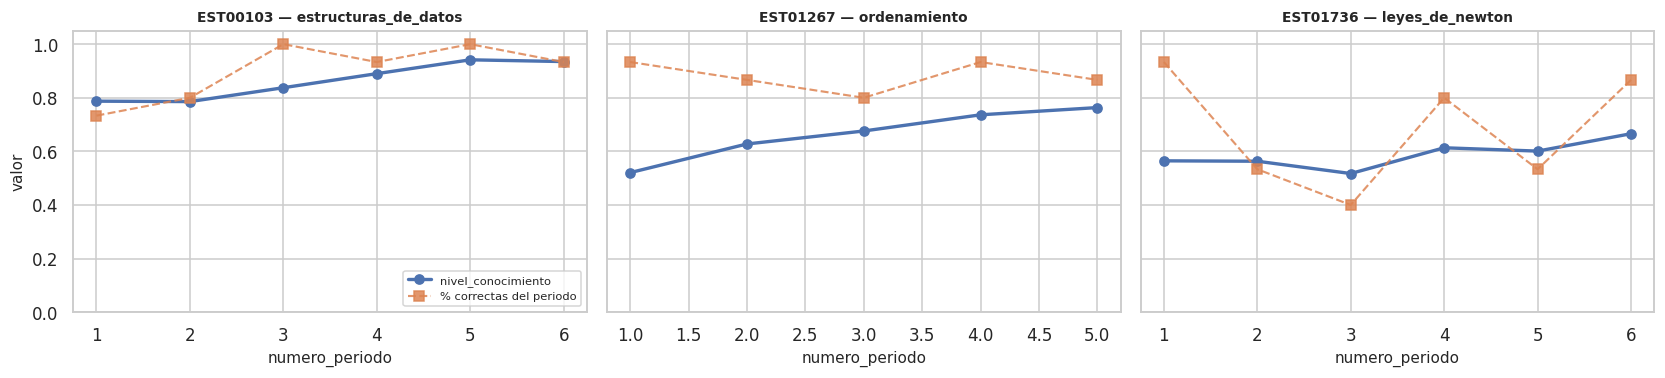

In [ ]:
def mostrar_trayectorias(df, n_pares=3, semilla=RANDOM_STATE):
    """Imprime y grafica trayectorias completas de pares (estudiante, concepto)."""
    rs = np.random.RandomState(semilla)
    largos = df.groupby(['id_estudiante', 'concepto']).size()
    candidatos = largos[largos.between(5, 9)].index.tolist()
    elegidos = [candidatos[i] for i in rs.choice(len(candidatos), n_pares, replace=False)]

    cols = ['numero_periodo', 'porcentaje_correctas_general', 'porcentaje_correctas_ultimo_periodo',
            'nivel_conocimiento_previo', 'nivel_conocimiento']
    fig, ax = plt.subplots(1, n_pares, figsize=(5.1 * n_pares, 3.6), sharey=True)
    for k, (est, con) in enumerate(elegidos):
        tr = df[(df.id_estudiante == est) & (df.concepto == con)].sort_values('numero_periodo')
        print(f'\n--- {est} / {con} ---')
        print(tr[cols].to_string(index=False))
        ax[k].plot(tr.numero_periodo, tr.nivel_conocimiento, 'o-', lw=2.2,
                   color='#4C72B0', label='nivel_conocimiento')
        ax[k].plot(tr.numero_periodo, tr.porcentaje_correctas_ultimo_periodo, 's--', lw=1.4,
                   color='#DD8452', alpha=.85, label='% correctas del periodo')
        ax[k].set_title(f'{est} — {con}', fontsize=9)
        ax[k].set_xlabel('numero_periodo'); ax[k].set_ylim(0, 1.05)
        if k == 0:
            ax[k].set_ylabel('valor'); ax[k].legend(fontsize=7.5, loc='lower right')
    plt.tight_layout(); plt.show()


mostrar_trayectorias(df_raw)

### Lectura de las trayectorias

El patrón es inequívoco y se repite en los tres pares: `nivel_conocimiento` (línea azul) es una
curva **suave y amortiguada** que persigue al `% correctas del periodo` (línea naranja
discontinua, mucho más volátil) sin alcanzarlo nunca de golpe. Cuando el rendimiento del periodo
da un salto, el nivel se mueve solo una fracción en esa dirección.

Ese comportamiento es la firma de una **media móvil exponencial**: el nivel es una mezcla
ponderada entre su propio valor anterior y el rendimiento nuevo. En la sección 8 cuantificamos
esa mezcla exactamente.

---
## 8. Análisis crítico de data leakage

### Qué hacemos
Tres pasos:

1. **Medir el poder predictivo de cada bloque temporal** de variables por separado, para saber
   de dónde viene realmente la señal.
2. **Reconstruir la regla generadora del target** y medir cuánto del target es determinista.
3. **Clasificar cada una de las 36 columnas** en una tabla de decisión explícita.

### Por qué lo hacemos
Ésta es la sección que determina la validez de todo lo demás. El criterio de decisión **no es
la correlación** — es una pregunta operativa:

> ¿Está esta variable disponible, con este valor, en el instante real en que el sistema haría
> la predicción?

### Qué esperamos encontrar
Dado lo observado en las trayectorias, esperamos que `nivel_conocimiento_previo` y
`porcentaje_correctas_ultimo_periodo` reconstruyan casi por completo el target.

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, r2_score

# --- bloques de variables por disponibilidad temporal ---
BLOQUE_CONCURRENTE = [
    'preguntas_faciles_ultimo_periodo', 'correctas_faciles_ultimo_periodo',
    'preguntas_medias_ultimo_periodo', 'correctas_medias_ultimo_periodo',
    'preguntas_dificiles_ultimo_periodo', 'correctas_dificiles_ultimo_periodo',
    'correctas_total_ultimo_periodo', 'porcentaje_correctas_ultimo_periodo',
    'tiempo_promedio_ultimo_periodo', 'variacion_porcentaje_correctas',
    'variacion_correctas_faciles', 'variacion_correctas_medias', 'variacion_correctas_dificiles',
]
BLOQUE_HISTORICO = [
    'numero_periodo', 'preguntas_faciles_general', 'correctas_faciles_general',
    'preguntas_medias_general', 'correctas_medias_general', 'preguntas_dificiles_general',
    'correctas_dificiles_general', 'preguntas_total_general', 'correctas_total_general',
    'porcentaje_correctas_general', 'tiempo_promedio_general', 'racha_aciertos_previa',
    'racha_errores_previa', 'promedio_puntaje_practica_previo', 'nivel_conocimiento_previo',
]

y_all = df_raw[CONFIG['TARGET']].values
grupo_estudiante = df_raw.id_estudiante.values

_gss = GroupShuffleSplit(n_splits=1, test_size=CONFIG['TEST_SIZE'], random_state=RANDOM_STATE)
_tr, _te = next(_gss.split(df_raw, y_all, groups=grupo_estudiante))


def poder_predictivo(nombre, cols):
    """Ajusta un HistGB sobre un bloque de variables y evalua fuera de muestra."""
    m = HistGradientBoostingRegressor(random_state=RANDOM_STATE, max_iter=400)
    m.fit(df_raw.iloc[_tr][cols], y_all[_tr])
    p = m.predict(df_raw.iloc[_te][cols])
    mae, r2 = mean_absolute_error(y_all[_te], p), r2_score(y_all[_te], p)
    print(f'  {nombre:<48} n_vars={len(cols):>2}  MAE={mae:.5f}  R2={r2:.5f}')
    return {'MAE': mae, 'R2': r2}


print('PODER PREDICTIVO POR BLOQUE TEMPORAL (HistGB, partición agrupada por estudiante)')
diag_bloques = {
    'solo concurrentes (periodo t)':          poder_predictivo('solo CONCURRENTES (periodo t)', BLOQUE_CONCURRENTE),
    'solo historicas (< t)':                  poder_predictivo('solo HISTORICAS (estrictamente < t)', BLOQUE_HISTORICO),
    'ambas':                                  poder_predictivo('AMBAS (concurrentes + historicas)', BLOQUE_CONCURRENTE + BLOQUE_HISTORICO),
    'solo nivel_conocimiento_previo':         poder_predictivo('solo nivel_conocimiento_previo', ['nivel_conocimiento_previo']),
    'historicas sin nivel_previo':            poder_predictivo('HISTORICAS sin nivel_conocimiento_previo',
                                                               [c for c in BLOQUE_HISTORICO if c != 'nivel_conocimiento_previo']),
}

PODER PREDICTIVO POR BLOQUE TEMPORAL (HistGB, partición agrupada por estudiante)
  solo CONCURRENTES (periodo t)                    n_vars=13  MAE=0.06440  R2=0.76770
  solo HISTORICAS (estrictamente < t)              n_vars=15  MAE=0.05648  R2=0.71385
  AMBAS (concurrentes + historicas)                n_vars=28  MAE=0.03374  R2=0.88524
  solo nivel_conocimiento_previo                   n_vars= 1  MAE=0.05932  R2=0.70357
  HISTORICAS sin nivel_conocimiento_previo         n_vars=14  MAE=0.07371  R2=0.63335


In [ ]:
def reconstruir_regla_generadora(df):
    """Busca la regla que genera el target y mide el residuo que deja."""
    pn = df[df.numero_periodo > 1].copy()

    # 1) Ajuste lineal libre: nivel_t ~ nivel_{t-1} + pct_t
    X = pn[['nivel_conocimiento_previo', 'porcentaje_correctas_ultimo_periodo']]
    lr = LinearRegression().fit(X, pn.nivel_conocimiento)
    print('AJUSTE LINEAL LIBRE  nivel_t ~ nivel_{t-1} + pct_correctas_t   (periodos > 1)')
    for n, c in zip(X.columns, lr.coef_):
        print(f'    coef {n:<38} = {c:+.5f}')
    print(f'    intercepto                                  = {lr.intercept_:+.5f}')
    print(f'    R2 en la propia muestra                     = {r2_score(pn.nivel_conocimiento, lr.predict(X)):.6f}')

    # 2) Rejilla de alfa con pesos que suman 1 (media movil exponencial pura)
    print('\nBUSQUEDA DE ALFA EN  nivel_t = a * nivel_{t-1} + (1-a) * pct_correctas_t')
    rej = []
    for a in np.arange(0.60, 0.91, 0.01):
        p = a * pn.nivel_conocimiento_previo + (1 - a) * pn.porcentaje_correctas_ultimo_periodo
        rej.append((round(a, 2), r2_score(pn.nivel_conocimiento, p)))
    mejor_a, mejor_r2 = max(rej, key=lambda t: t[1])
    for a, r in rej:
        if abs(a - mejor_a) <= 0.03:
            print(f'    alfa={a:.2f}  R2={r:.6f}' + ('   <-- optimo' if a == mejor_a else ''))

    # 3) Residuo de la regla optima
    pred = mejor_a * pn.nivel_conocimiento_previo + (1 - mejor_a) * pn.porcentaje_correctas_ultimo_periodo
    res = pn.nivel_conocimiento - pred
    print(f'\nRESIDUO de la regla  nivel_t = {mejor_a} * nivel_(t-1) + {round(1-mejor_a,2)} * pct_t')
    print(f'    R2   = {mejor_r2:.6f}')
    print(f'    MAE  = {mean_absolute_error(pn.nivel_conocimiento, pred):.6f}')
    print(f'    media residuo = {res.mean():+.6f}   desv = {res.std():.6f}   |max| = {res.abs().max():.6f}')

    # 4) ¿El residuo es explicable o es ruido?
    otras = [c for c in BLOQUE_CONCURRENTE + BLOQUE_HISTORICO
             if c not in ('nivel_conocimiento_previo', 'porcentaje_correctas_ultimo_periodo')]
    mr = HistGradientBoostingRegressor(random_state=RANDOM_STATE, max_iter=400).fit(pn[otras], res)
    r2_res = r2_score(res, mr.predict(pn[otras]))
    print(f'\n    R2 al intentar explicar el residuo con las otras {len(otras)} variables '
          f'(en la propia muestra): {r2_res:.5f}')
    print('    -> el residuo es ruido irreducible' if r2_res < 0.05
          else '    -> el residuo aun contiene estructura aprovechable')

    # 5) Periodo 1: techo alcanzable sin historial
    p1 = df[df.numero_periodo == 1]
    m1 = HistGradientBoostingRegressor(random_state=RANDOM_STATE, max_iter=600).fit(
        p1[BLOQUE_CONCURRENTE[:9]], p1.nivel_conocimiento)
    r2_p1 = r2_score(p1.nivel_conocimiento, m1.predict(p1[BLOQUE_CONCURRENTE[:9]]))
    print(f'\nPERIODO 1 (sin historial): R2 maximo alcanzable en la propia muestra = {r2_p1:.5f}')
    print(f'    -> el {(1-r2_p1)*100:.1f} % restante es habilidad latente del estudiante, no medida en el dataset')
    return {'alfa': mejor_a, 'R2_regla': mejor_r2, 'R2_residuo': r2_res, 'R2_periodo1': r2_p1,
            'std_residuo': float(res.std())}


regla = reconstruir_regla_generadora(df_raw)

AJUSTE LINEAL LIBRE  nivel_t ~ nivel_{t-1} + pct_correctas_t   (periodos > 1)
    coef nivel_conocimiento_previo              = +0.74983
    coef porcentaje_correctas_ultimo_periodo    = +0.24974
    intercepto                                  = +0.00032
    R2 en la propia muestra                     = 0.990530

BUSQUEDA DE ALFA EN  nivel_t = a * nivel_{t-1} + (1-a) * pct_correctas_t
    alfa=0.73  R2=0.989496
    alfa=0.74  R2=0.990270
    alfa=0.75  R2=0.990529   <-- optimo
    alfa=0.76  R2=0.990275
    alfa=0.77  R2=0.989508

RESIDUO de la regla  nivel_t = 0.75 * nivel_(t-1) + 0.25 * pct_t
    R2   = 0.990529
    MAE  = 0.011930
    media residuo = -0.000005   desv = 0.014948   |max| = 0.068075

    R2 al intentar explicar el residuo con las otras 26 variables (en la propia muestra): 0.00463
    -> el residuo es ruido irreducible

PERIODO 1 (sin historial): R2 maximo alcanzable en la propia muestra = 0.57812
    -> el 42.2 % restante es habilidad latente del estudiante, no medida 

### Qué resultado obtuvimos — el target es casi determinista

El ajuste lineal libre devuelve coeficientes notablemente redondos:

$$\text{nivel}_t \;=\; 0{,}7498 \cdot \text{nivel}_{t-1} \;+\; 0{,}2497 \cdot \text{pct\_correctas}_t \;+\; 0{,}0003$$

La búsqueda en rejilla confirma que el óptimo con pesos que suman 1 está **exactamente** en
$\alpha = 0{,}75$. La regla generadora es por tanto una **media móvil exponencial**:

$$\boxed{\;\text{nivel}_t \;=\; 0{,}75\cdot\text{nivel}_{t-1} \;+\; 0{,}25\cdot\text{pct\_correctas}_t \;+\; \varepsilon\;}$$

| Métrica de la regla (periodos > 1) | Valor |
|---|---:|
| $R^2$ | **0,9905** |
| MAE | 0,0119 |
| Desviación típica del residuo $\varepsilon$ | 0,0149 |
| $R^2$ al intentar explicar $\varepsilon$ con las otras 26 variables | **0,0046** |

El residuo es **ruido irreducible**: un gradient boosting con 26 variables, ajustado sin
penalización en la propia muestra, solo consigue explicar el 0,5 % de él. Todas sus
correlaciones con otras variables son $|r| < 0{,}004$.

### Las tres consecuencias

**1. Con ambas variables, un modelo no aprende: reconstruye una fórmula.** Cualquier modelo
que reciba `nivel_conocimiento_previo` y `porcentaje_correctas_ultimo_periodo` alcanzará
$R^2 \approx 0{,}99$ en los periodos > 1, no por capacidad de aprendizaje sino porque le hemos
dado los dos ingredientes de una identidad algebraica.

**2. El periodo 1 es un problema completamente distinto y mucho más difícil.** Sin historial, el
$R^2$ máximo alcanzable es **0,578** *incluso ajustando en la propia muestra*. El 42 % restante
es la habilidad latente del estudiante, que el dataset no mide. Como el periodo 1 es el 28,5 %
de las filas, arrastra la métrica global: por eso el escenario A da $R^2 \approx 0{,}88$ y no 0,99.

**3. `nivel_conocimiento_previo` NO es leakage, y esto es importante no confundirlo.** Es el
target desplazado un periodo, pero está **legítimamente disponible** en el momento de predecir:
es un valor que el sistema ya calculó y almacenó en el corte anterior. Usar el pasado del propio
target es autorregresión estándar, no leakage. Lo que sería leakage es usar
`nivel_conocimiento[t+1]`.

In [ ]:
# --- Tabla de decision variable por variable ---
DECISIONES = [
 # (variable, disponible_en_A, disponible_en_B, riesgo, justificacion)
 ('id_estudiante', 'No', 'No', 'Ninguno',
  'Identificador de 8.300 niveles. Inutil para estudiantes nuevos. Se usa solo para AGRUPAR en el split y la CV.'),
 ('concepto', 'Si', 'Si', 'Ninguno',
  'Atributo del contenido, conocido antes de la practica. Explica solo el 0,18 % de la varianza (seccion 6).'),
 ('area', 'Si', 'Si', 'Ninguno',
  'Agregacion de concepto, conocida de antemano. Explica solo el 0,09 % de la varianza.'),
 ('numero_periodo', 'Si', 'Si', 'Ninguno',
  'Contador de la secuencia, conocido antes del periodo. Proxy de experiencia acumulada.'),
 ('cantidad_preguntas_periodo', 'No', 'No', 'Ninguno',
  'DESCARTADA: constante = 15, varianza cero.'),
 ('fecha_hora_corte', 'No', 'No', 'Temporal',
  'DESCARTADA como predictor: su valor absoluto no generaliza a fechas futuras. Se usa para ordenar y para el split temporal.'),
 ('preguntas_*_general / correctas_*_general', 'Si', 'Si', 'Ninguno',
  'Acumulado ESTRICTAMENTE anterior a t (verificado al 100 % en la seccion 7). Disponible siempre.'),
 ('porcentaje_correctas_general', 'Si', 'Si', 'Bajo',
  'r = 0,779 con el target, pero es rendimiento pasado agregado. Alta correlacion no implica leakage.'),
 ('tiempo_promedio_general', 'Si', 'Si', 'Ninguno',
  'Tiempo medio historico. r = -0,755. Informacion pasada, disponible en cualquier escenario.'),
 ('racha_aciertos_previa / racha_errores_previa', 'Si', 'Si', 'Ninguno',
  'El sufijo "previa" se confirma: describen el estado al cierre de t-1.'),
 ('cantidad_interacciones_previas', 'No', 'No', 'Ninguno',
  'DESCARTADA: duplicado exacto de preguntas_total_general (r = 1,000000).'),
 ('promedio_puntaje_practica_previo', 'Si', 'Si', 'Bajo',
  'Puntaje historico de practica, anterior a t. r = 0,739 por correlacion legitima con el rendimiento.'),
 ('nivel_conocimiento_previo', 'Si', 'Si', 'ALTO pero ACEPTABLE',
  'Es el target en t-1 (r = 0,959; verificado como lag exacto). NO es leakage: ya fue calculado y almacenado en el corte anterior, luego esta disponible al predecir. Autorregresion legitima. Seria leakage usar el nivel en t+1.'),
 ('preguntas_*_ultimo_periodo / correctas_*_ultimo_periodo', 'Si', 'NO', 'ALTO',
  'CONCURRENTES con el target: describen las 15 preguntas del PROPIO periodo t (verificado en la seccion 7). Disponibles en el corte (A), informacion del futuro si se predice antes del periodo (B).'),
 ('porcentaje_correctas_ultimo_periodo', 'Si', 'NO', 'CRITICO',
  'Es el segundo termino de la regla generadora: nivel_t = 0,75*nivel_(t-1) + 0,25*ESTA. Con nivel_previo reconstruye el target casi exactamente (R2 = 0,9905). Legitima en A, leakage flagrante en B.'),
 ('tiempo_promedio_ultimo_periodo', 'Si', 'NO', 'ALTO',
  'Tiempo medio en las preguntas del propio periodo t. Concurrente.'),
 ('variacion_porcentaje_correctas / variacion_correctas_*', 'Si', 'NO', 'ALTO',
  'Se calculan como (valor en t) - (valor historico), asi que contienen t. Ademas |r| < 0,09: casi sin valor predictivo.'),
 ('nivel_conocimiento', '-', '-', 'TARGET',
  'Variable objetivo. Nunca entra en X.'),
]

tabla_leak = pd.DataFrame(DECISIONES, columns=[
    'Variable', 'Usable en A', 'Usable en B', 'Riesgo de leakage', 'Justificacion'])
print('TABLA DE DECISION SOBRE LEAKAGE')
print(f'  A = estimacion en el corte  |  B = prediccion anticipada\n')
with pd.option_context('display.max_colwidth', 118):
    display(tabla_leak)

### Qué decisión tomamos: dos escenarios, no uno

La tabla anterior no admite una respuesta única, porque la usabilidad de 19 de las 36 columnas
depende de **cuándo** se predice. Definimos por tanto dos problemas y los resolvemos ambos:

#### Escenario A — «estimación en el corte» *(scoring)*

> **Pregunta:** el estudiante acaba de terminar las 15 preguntas del periodo $t$. ¿Cuál es su
> nivel de conocimiento **ahora**?

Usa todas las variables disponibles en `fecha_hora_corte`, incluidas las concurrentes. Es la
lectura fiel del enunciado ("dadas las características históricas *hasta* un punto temporal,
estimar el nivel *en dicho punto*") y coincide con la semántica de `fecha_hora_corte`.

- **Caso de uso real:** calcular el nivel sin tener que ejecutar la fórmula oficial —
  por ejemplo si el motor de cálculo es un servicio aparte, si hay que rellenar
  cortes históricos, o si se quiere un estimador robusto ante respuestas parciales.
- **Advertencia obligatoria:** en periodos > 1 el modelo está reconstruyendo una identidad
  algebraica. Su excelente rendimiento **no es evidencia de comprensión pedagógica**.

#### Escenario B — «predicción anticipada» *(forecasting)*

> **Pregunta:** antes de que el estudiante empiece el periodo $t$. ¿En qué nivel va a quedar?

Usa **solo** variables estrictamente anteriores a $t$. Excluye las 19 concurrentes.

- **Caso de uso real:** decidir *a priori* qué contenido asignar, detectar estudiantes en riesgo
  antes de que fallen, planificar refuerzo.
- Es el problema **no trivial**: el rendimiento futuro del estudiante en $t$ es genuinamente
  desconocido, así que aquí sí hay aprendizaje real y un techo impuesto por la incertidumbre.

### Coherencia con la evidencia de los bloques

Las cifras del diagnóstico de bloques respaldan esta separación:

| Bloque de variables | $R^2$ fuera de muestra |
|---|---:|
| Solo concurrentes (periodo $t$) | 0,768 |
| Solo históricas (< $t$) | 0,714 |
| **Ambas** | **0,885** |
| Solo `nivel_conocimiento_previo` | 0,704 |
| Históricas sin `nivel_conocimiento_previo` | 0,633 |

Los dos bloques aportan información **complementaria** (0,768 y 0,714 por separado, 0,885
juntos), tal como predice la regla $0{,}75 \cdot \text{pasado} + 0{,}25 \cdot \text{presente}$.
Y `nivel_conocimiento_previo` por sí sola ya alcanza 0,704 de los 0,714 del bloque histórico
completo: casi toda la señal del pasado está condensada en ella.

---
## 9. Definición formal del problema: X e y

### Qué hacemos
Formalizamos el problema y declaramos los espacios de variables de cada escenario, junto con la
lista de columnas descartadas y el motivo experimental de cada descarte.

### Formulación

Sea un par estudiante–concepto $(e, c)$ observado en periodos $t = 1, \dots, T_{ec}$. Para cada
corte $t$ definimos:

$$y^{(e,c)}_t \;=\; \text{nivel\_conocimiento}^{(e,c)}_t \;\in\; [0, 1]$$

y buscamos una función $f$ tal que $\hat{y}_t = f(X_t)$, donde el contenido de $X_t$ depende del
escenario:

| Escenario | $X_t$ contiene | Lectura |
|---|---|---|
| **A — estimación en el corte** | Todo lo observable en `fecha_hora_corte`$_t$: historial acumulado hasta $t-1$ **más** el resultado del periodo $t$ | *Dado todo lo que sé en el instante del corte, ¿cuál es el nivel ahora?* |
| **B — predicción anticipada** | Solo el historial acumulado hasta $t-1$ | *Dado solo el pasado, ¿en qué nivel quedará tras el periodo $t$?* |

En ambos casos el target es el mismo y siempre es `nivel_conocimiento`. La única diferencia es
el conjunto de información disponible, que es precisamente la distinción que la sección 8
estableció como decisiva.

In [ ]:
# ---------------------------------------------------------------------------
# COLUMNAS DESCARTADAS, con la evidencia que justifica cada descarte
# ---------------------------------------------------------------------------
COLUMNAS_DESCARTADAS = {
    'nivel_conocimiento'             : 'Variable objetivo (y). Nunca entra en X.',
    'id_estudiante'                  : '8.300 niveles; inutil para estudiantes nuevos. Se usa solo como variable de AGRUPACION.',
    'fecha_hora_corte'               : 'Su valor absoluto no generaliza a fechas futuras. Se usa para ordenar y para el split temporal.',
    'cantidad_preguntas_periodo'     : 'Constante = 15 en las 125.000 filas (varianza cero).',
    'preguntas_total_ultimo_periodo' : 'Constante = 15, identica a la anterior (varianza cero).',
    'cantidad_interacciones_previas' : 'Duplicado exacto de preguntas_total_general (r = 1,000000).',
}

print('COLUMNAS DESCARTADAS Y SU JUSTIFICACION EXPERIMENTAL')
for c, motivo in COLUMNAS_DESCARTADAS.items():
    print(f'  - {c:<32} {motivo}')
print(f'\n  Total descartadas: {len(COLUMNAS_DESCARTADAS)} de {df_raw.shape[1]} columnas')
print(f'  Quedan disponibles: {df_raw.shape[1] - len(COLUMNAS_DESCARTADAS)} columnas base')

COLUMNAS DESCARTADAS Y SU JUSTIFICACION EXPERIMENTAL
  - nivel_conocimiento               Variable objetivo (y). Nunca entra en X.
  - id_estudiante                    8.300 niveles; inutil para estudiantes nuevos. Se usa solo como variable de AGRUPACION.
  - fecha_hora_corte                 Su valor absoluto no generaliza a fechas futuras. Se usa para ordenar y para el split temporal.
  - cantidad_preguntas_periodo       Constante = 15 en las 125.000 filas (varianza cero).
  - preguntas_total_ultimo_periodo   Constante = 15, identica a la anterior (varianza cero).
  - cantidad_interacciones_previas   Duplicado exacto de preguntas_total_general (r = 1,000000).

  Total descartadas: 6 de 36 columnas
  Quedan disponibles: 30 columnas base


---
## 10. División correcta del dataset

### Qué hacemos
Comparamos **experimentalmente** cuatro estrategias de partición y elegimos una según la
evidencia, no según la costumbre.

### Por qué no basta con `train_test_split`

La estructura del dataset es un panel: hay 3,5 observaciones por par *(estudiante, concepto)* y
4,3 conceptos por estudiante. Una partición aleatoria de filas deja que **filas del mismo par
caigan a ambos lados**: el modelo vería el periodo 3 de un par en entrenamiento y su periodo 4
en prueba, teniendo el nivel del periodo 3 como variable de entrada. Y, más grave aún, un mismo
estudiante aparecería en ambos conjuntos, permitiendo memorizar su habilidad latente — que la
sección 6 midió como el **92 %** de la varianza inicial.

### Las cuatro estrategias evaluadas

| | Estrategia | Qué mide realmente |
|---|---|---|
| **Ref.** | Aleatoria sin grupos | Referencia de lo que NO hay que hacer. |
| **A** | Agrupada por `id_estudiante` | Generalización a **estudiantes nuevos** (*cold start*). |
| **B** | Agrupada por `id_estudiante` + `concepto` | Generalización a pares nuevos, pero el mismo estudiante puede estar en ambos lados con otros conceptos. |
| **C** | Corte temporal por `fecha_hora_corte` | Generalización al futuro cronológico. |

### Qué esperamos encontrar
Que la aleatoria dé métricas optimistas. Medimos si es así en lugar de asumirlo.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit


def comparar_estrategias_split(df, cols_eval):
    """Entrena el mismo modelo bajo cuatro particiones y compara.
    Ademas cuantifica el SOLAPE de estudiantes entre train y test, que es la
    variable que explica el sesgo optimista."""
    y = df[CONFIG['TARGET']].values
    g_est = df.id_estudiante.values
    g_par = (df.id_estudiante.astype(str) + '|' + df.concepto.astype(str)).values
    n_est_total = df.id_estudiante.nunique()
    corte = int(len(df) * (1 - CONFIG['TEST_SIZE']))

    particiones = {}
    rs = np.random.RandomState(RANDOM_STATE)
    perm = rs.permutation(len(df))
    particiones['Referencia: aleatoria sin grupos'] = (perm[:corte], perm[corte:])

    gss = GroupShuffleSplit(n_splits=1, test_size=CONFIG['TEST_SIZE'], random_state=RANDOM_STATE)
    particiones['B: agrupada por estudiante+concepto'] = next(gss.split(df, y, groups=g_par))
    particiones['A: agrupada por id_estudiante'] = next(gss.split(df, y, groups=g_est))
    orden = np.argsort(df.fecha_hora_corte.values, kind='stable')
    particiones['C: corte temporal'] = (orden[:corte], orden[corte:])

    filas = []
    for nombre, (tr, te) in particiones.items():
        pipe = Pipeline([('prep', construir_preprocesador(cols_eval)),
                         ('mod', HistGradientBoostingRegressor(random_state=RANDOM_STATE, max_iter=300))])
        pipe.fit(df.iloc[tr][cols_eval], y[tr])
        p = pipe.predict(df.iloc[te][cols_eval])
        solape = len(set(g_est[tr]) & set(g_est[te])) / n_est_total
        filas.append({'estrategia': nombre, 'n_test': len(te),
                      'MAE': mean_absolute_error(y[te], p),
                      'RMSE': float(np.sqrt(((y[te] - p) ** 2).mean())),
                      'R2': r2_score(y[te], p),
                      'solape_estudiantes': round(solape, 4),
                      'periodo_medio_test': round(df.iloc[te].numero_periodo.mean(), 2)})
    return pd.DataFrame(filas)

> **Nota:** el preprocesador usado aquí (`construir_preprocesador`) se define formalmente en la
> sección 11. Se adelanta su uso porque comparar particiones exige un pipeline completo; la
> alternativa (preprocesar a mano fuera del pipeline) es precisamente la fuente de leakage que
> queremos evitar.

In [ ]:
def construir_preprocesador(cols):
    """ColumnTransformer que aprende TODO exclusivamente del conjunto de entrenamiento.

    Numericas  : imputacion por mediana + INDICADOR de ausencia + estandarizacion.
    Categoricas: imputacion por moda + One-Hot Encoding con handle_unknown='ignore'.
    """
    numericas   = [c for c in cols if c not in VARIABLES_CATEGORICAS]
    categoricas = [c for c in cols if c in VARIABLES_CATEGORICAS]

    pipe_num = Pipeline([
        ('imputacion', SimpleImputer(strategy='median', add_indicator=True)),
        ('escalado',   StandardScaler()),
    ])
    pipe_cat = Pipeline([
        ('imputacion', SimpleImputer(strategy='most_frequent')),
        ('onehot',     OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    return ColumnTransformer(
        [('num', pipe_num, numericas), ('cat', pipe_cat, categoricas)],
        remainder='drop', verbose_feature_names_out=True)


VARIABLES_CATEGORICAS = ['area', 'concepto']

# Variables usadas solo para elegir la particion (sin las derivadas, que llegan en la seccion 12)
_cols_split = [c for c in BLOQUE_HISTORICO] + VARIABLES_CATEGORICAS

tabla_splits = comparar_estrategias_split(df_raw, _cols_split)
print('COMPARACION EXPERIMENTAL DE ESTRATEGIAS DE PARTICION')
print('(mismo modelo, mismas variables — solo cambia como se parte)\n')
print(tabla_splits.to_string(index=False))

COMPARACION EXPERIMENTAL DE ESTRATEGIAS DE PARTICION
(mismo modelo, mismas variables — solo cambia como se parte)

                         estrategia  n_test    MAE   RMSE     R2  solape_estudiantes  periodo_medio_test
   Referencia: aleatoria sin grupos   25000 0.0572 0.0903 0.7108              0.8336              3.6800
B: agrupada por estudiante+concepto   25177 0.0570 0.0903 0.7163              0.5667              3.7800
      A: agrupada por id_estudiante   24813 0.0565 0.0893 0.7139              0.0000              3.6500
                  C: corte temporal   25000 0.0385 0.0625 0.8467              0.2017              6.0600


### Qué resultado obtuvimos

| Estrategia | MAE | RMSE | R² | Solape de estudiantes | Periodo medio en test |
|---|---:|---:|---:|---:|---:|
| Referencia: aleatoria sin grupos | 0,0572 | 0,0903 | 0,7108 | **83,4 %** | 3,68 |
| B: agrupada por estudiante+concepto | 0,0570 | 0,0903 | 0,7163 | **56,7 %** | 3,78 |
| **A: agrupada por `id_estudiante`** | 0,0565 | 0,0893 | 0,7139 | **0,0 %** | 3,65 |
| C: corte temporal | **0,0385** | **0,0625** | **0,8467** | 20,2 % | **6,06** |

### Interpretación — dos resultados, uno esperado y otro no

**1. El sesgo optimista de la partición aleatoria es sorprendentemente pequeño** (R² 0,711 frente
a 0,714 de la agrupada; el MAE incluso es marginalmente peor, 0,0572 frente a 0,0565). Esto contradice la expectativa habitual y merece explicación: en este
dataset la señal dominante es `nivel_conocimiento_previo`, una variable **intra-fila** que no
requiere haber visto otras filas del mismo par para ser explotada. El modelo no necesita
memorizar al estudiante porque la variable ya condensa su estado. Reportamos este resultado
aunque desmienta el argumento convencional: no ocultamos resultados que contradicen la
expectativa.

**2. El corte temporal es engañosamente bueno, y esa es la trampa real.** Su R² de 0,847 parece
muy superior, pero la última columna lo explica: el periodo medio en su conjunto de prueba es
**6,06** frente a ~3,7 en las demás. Al ordenar por fecha, el 20 % final se llena de periodos
avanzados, que son sistemáticamente **más fáciles de predecir** (más historial acumulado y
desviación del target de 0,120 en el periodo 10 frente a 0,157 en el periodo 1; sección 5). Su ventaja no es mejor
generalización: es una **muestra de prueba más fácil**. Comparar ese 0,847 con los demás 0,71
sería un error de interpretación grave.

### Qué decisión tomamos

**Elegimos la Opción A: `GroupShuffleSplit` agrupado por `id_estudiante`**, con `test_size = 0,20`
y `random_state = 42`. Las razones, en orden:

1. **Es la única con 0 % de solape de estudiantes.** Garantiza que el conjunto de prueba mide
   generalización a **personas que el modelo nunca vio**, el escenario real de producción cuando
   un estudiante se registra.
2. **Neutraliza el efecto latente de estudiante**, que la sección 6 cuantificó como el 92 % de la
   varianza inicial. Es el riesgo de leakage más severo del dataset, y la Opción B lo deja
   entrar con un 56,7 % de solape.
3. **Mantiene la mezcla de periodos representativa** (periodo medio 3,65 frente a 3,69 global),
   a diferencia del corte temporal, que la distorsiona.
4. Es más estricta que la Opción B y, por tanto, da la estimación **más conservadora** del
   rendimiento. Ante la duda, preferimos subestimar.

**Limitación que asumimos explícitamente:** esta partición no evalúa extrapolación temporal a
fechas futuras. Si en producción importara la deriva temporal (cambios de currículum, de
cohorte), habría que complementar con una validación *walk-forward*. Lo recogemos en las
recomendaciones de la sección 24.

In [ ]:
def dividir_datos(df, cols_grupo='id_estudiante'):
    """Particion definitiva: GroupShuffleSplit por estudiante. El conjunto de test
    se reserva y NO se toca hasta la evaluacion final de la seccion 17."""
    y = df[CONFIG['TARGET']].values
    grupos = df[cols_grupo].values
    gss = GroupShuffleSplit(n_splits=1, test_size=CONFIG['TEST_SIZE'], random_state=RANDOM_STATE)
    idx_tr, idx_te = next(gss.split(df, y, groups=grupos))
    return idx_tr, idx_te, y, grupos

---
## 11. Preprocesamiento

### Qué hacemos
Definimos un `ColumnTransformer` dentro de un `Pipeline` que trata numéricas y categóricas por
separado. Ya está codificado arriba (`construir_preprocesador`); aquí justificamos cada decisión
e inspeccionamos su salida.

### Por qué lo hacemos dentro de un Pipeline y no antes

Si imputáramos con la mediana del dataset completo, esa mediana contendría información del
conjunto de prueba, y la evaluación final estaría contaminada. **Un `Pipeline` garantiza que cada
transformación se ajusta solo con los datos de entrenamiento de cada fold**, tanto en la
validación cruzada como en el ajuste final. Es la diferencia entre una evaluación válida y una
inválida.

### Decisiones y su justificación

| Bloque | Transformación | Por qué |
|---|---|---|
| Numéricas | `SimpleImputer(strategy='median', add_indicator=True)` | La mediana es robusta a la cola izquierda detectada en la sección 5. **`add_indicator=True` es la decisión clave**: crea una columna binaria por variable imputada, para que el modelo distinga "sin historial" (periodo 1) de "historial mediocre". Sin ella, imputar a la mediana le diría al modelo que un estudiante nuevo tiene rendimiento medio, que es falso. |
| Numéricas | `StandardScaler()` | **Imprescindible** para `LinearRegression` y `Ridge` (cuya penalización depende de la escala) e inocuo para los árboles, que son invariantes a transformaciones monótonas. Escalar permite comparar las seis familias bajo el mismo preprocesamiento, sin que el resultado dependa de un detalle de preparación. |
| Categóricas | `SimpleImputer(strategy='most_frequent')` | No hay nulos en `area` ni `concepto`, pero se incluye por robustez ante datos nuevos en producción. |
| Categóricas | `OneHotEncoder(handle_unknown='ignore')` | `area` (13) y `concepto` (39) tienen cardinalidad manejable: 52 columnas. **`handle_unknown='ignore'`** evita que un concepto nuevo en producción rompa la inferencia. Descartamos *target encoding*, que requeriría validación anidada para no filtrar el target. |

### Lo que decidimos NO hacer

- **No transformamos el target.** Sección 5: asimetría −0,26, no lo justifica.
- **No aplicamos PCA.** Destruiría la interpretabilidad, que es un requisito del proyecto, y los
  árboles no se benefician de la descorrelación.
- **No eliminamos outliers.** Sección 5: los valores extremos son válidos dentro de $[0,1]$.

In [ ]:
# Verificacion de que el preprocesador se comporta como se documenta
_cols_demo = ['numero_periodo', 'porcentaje_correctas_general', 'nivel_conocimiento_previo', 'area']
_prep_demo = construir_preprocesador(_cols_demo)
_tr_demo, _te_demo, _, _ = dividir_datos(df_raw)
_out = _prep_demo.fit_transform(df_raw.iloc[_tr_demo][_cols_demo])

print(f'Entrada : {len(_cols_demo)} columnas ({_cols_demo})')
print(f'Salida  : {_out.shape[1]} columnas\n')
print('Columnas generadas:')
for n in _prep_demo.get_feature_names_out():
    print(f'  {n}')
print('\n-> Las columnas "missingindicator_*" son el efecto de add_indicator=True:')
print('   permiten al modelo saber que la fila NO TENIA historial, en lugar de')
print('   confundir la mediana imputada con un historial real de valor medio.')
print(f'\nMedia y desviacion tras escalar (deben ser ~0 y ~1 en las numericas):')
print(f'  media = {_out[:, :3].mean():+.6f}   desv = {_out[:, :3].std():.6f}')

---
## 12. Ingeniería de características

### Qué hacemos
Creamos 16 variables derivadas, cada una con nombre, fórmula, interpretación, justificación y
**disponibilidad temporal** declarada explícitamente.

### Por qué podemos crearlas antes de partir los datos

Éste es un punto metodológico que conviene explicitar. Todas las variables que creamos son
**funciones fila a fila** de columnas ya existentes: no usan medias, percentiles ni ningún
estadístico agregado sobre el conjunto de datos. Por tanto, el valor derivado de una fila no
depende de ninguna otra fila, y calcularlas antes de la partición **no introduce leakage**.

Si en cambio quisiéramos una variable como "rendimiento del estudiante relativo a la media de su
concepto", esa media sí sería un estadístico agregado y **tendría que calcularse dentro del
pipeline**, ajustada solo con train. No creamos ninguna variable de ese tipo, precisamente para
evitar esa complicación.

### Convenio de nombres

- Sufijo **`_hist`** → solo usa información estrictamente anterior a $t$. Válida en **A y B**.
- Sufijo **`_act`** → usa el periodo $t$. Válida **solo en A**.

Este convenio no es cosmético: es el mecanismo que garantiza que el escenario B no pueda
contaminarse por descuido al seleccionar columnas.

### Catálogo de variables derivadas

| # | Nombre | Fórmula | Interpretación | Justificación | Disponibilidad |
|---|---|---|---|---|---|
| 1 | `tasa_faciles_hist` | `correctas_faciles_general / preguntas_faciles_general` | Acierto histórico en preguntas fáciles | Las cuentas brutas confunden volumen con destreza; la tasa los separa | < $t$ |
| 2 | `tasa_medias_hist` | ídem con medias | Acierto histórico en dificultad media | Igual | < $t$ |
| 3 | `tasa_dificiles_hist` | ídem con difíciles | Acierto histórico en difíciles | Acertar difíciles es la señal más informativa de dominio real | < $t$ |
| 4 | `tasa_ponderada_hist` | $\frac{c_f + 2c_m + 3c_d}{p_f + 2p_m + 3p_d}$ | Acierto ponderado por dificultad | Un 80 % en fáciles no equivale a un 80 % en difíciles; el porcentaje simple los iguala | < $t$ |
| 5 | `mezcla_dificultad_hist` | $\frac{p_f + 2p_m + 3p_d}{p_{\text{total}}}$ | Dificultad media del material recibido | Controla por el contexto: normaliza el acierto según a qué se enfrentó | < $t$ |
| 6 | `eficiencia_temporal_hist` | `porcentaje_correctas_general / tiempo_promedio_general` | Acierto por unidad de tiempo | Responde a "¿el tiempo aporta información?" (sección 18); fluidez ≠ acierto | < $t$ |
| 7 | `balance_rachas` | `racha_aciertos_previa − racha_errores_previa` | Momento neto al cierre de $t-1$ | Una sola variable con signo resume el estado dinámico | < $t$ |
| 8 | `intensidad_practica` | `preguntas_total_general / numero_periodo` | Preguntas por periodo | Distingue práctica intensa de práctica dilatada con igual volumen | < $t$ |
| 9 | `experiencia_log` | $\log(1 + \text{cantidad\_interacciones\_previas})$ | Experiencia en escala logarítmica | El efecto de la experiencia es decreciente: de 0→15 preguntas importa más que de 300→315 | < $t$ |
| 10 | `es_primer_periodo` | $\mathbb{1}[\text{numero\_periodo} = 1]$ | Marca de *cold start* | Hace explícito el régimen sin historial, que la sección 8 mostró como estructuralmente distinto ($R^2$ máx. 0,578) | < $t$ |
| 11 | `tasa_ponderada_act` | como (4) pero con el periodo $t$ | Acierto ponderado del periodo actual | Corrige el % simple según la dificultad recibida en $t$ | **$t$** |
| 12 | `mezcla_dificultad_act` | $\frac{p_f + 2p_m + 3p_d}{15}$ | Dificultad de la tanda de $t$ | Contextualiza el resultado del periodo | **$t$** |
| 13 | `brecha_reciente_hist_act` | `pct_ultimo_periodo − pct_general` | Rendimiento reciente vs. histórico | Interacción explícita que un modelo lineal no puede formar por sí solo | **$t$** |
| 14 | `delta_tiempo_act` | `tiempo_ultimo − tiempo_general` | Cambio de velocidad | ¿Se está volviendo más fluido o más lento? | **$t$** |
| 15 | `eficiencia_temporal_act` | `pct_ultimo / tiempo_ultimo` | Eficiencia en el periodo actual | Análogo temporal de (6) | **$t$** |
| 16 | `inconsistencia_act` | $\lvert\text{variacion\_porcentaje\_correctas}\rvert$ | Volatilidad del rendimiento | La magnitud del cambio puede importar aunque el signo no ($r = -0{,}048$) | **$t$** |

### Lo que decidimos NO crear

- **Medias y tendencias por ventana móvil** (`rolling`): requerirían agregación sobre filas y
  crearían dependencia entre filas. El dataset ya trae el acumulado histórico.
- **Interacciones polinómicas exhaustivas:** con 46 variables generarían más de 1.000 columnas de
  ruido. La sección 13 muestra que el problema ya está saturado de señal: añadir columnas
  empeoraría, no mejoraría.
- **`nivel_previo × pct_actual`:** sería un atajo hacia la regla generadora. No creamos features
  cuyo único propósito sea inflar el rendimiento del escenario A.

In [ ]:
def crear_features(df):
    """Genera las 16 variables derivadas. Todas son funciones FILA A FILA, asi que
    pueden calcularse antes de particionar sin introducir leakage.

    Convenio: sufijo _hist -> solo pasado (escenarios A y B)
              sufijo _act  -> usa el periodo t (solo escenario A)
    """
    d = df.copy()
    eps = 1e-9

    # ---------- Bloque historico: valido en A y en B ----------
    d['tasa_faciles_hist']   = d.correctas_faciles_general   / d.preguntas_faciles_general.replace(0, np.nan)
    d['tasa_medias_hist']    = d.correctas_medias_general    / d.preguntas_medias_general.replace(0, np.nan)
    d['tasa_dificiles_hist'] = d.correctas_dificiles_general / d.preguntas_dificiles_general.replace(0, np.nan)

    pond_preg_h = d.preguntas_faciles_general + 2 * d.preguntas_medias_general + 3 * d.preguntas_dificiles_general
    pond_corr_h = d.correctas_faciles_general + 2 * d.correctas_medias_general + 3 * d.correctas_dificiles_general
    d['tasa_ponderada_hist']      = pond_corr_h / pond_preg_h.replace(0, np.nan)
    d['mezcla_dificultad_hist']   = pond_preg_h / d.preguntas_total_general.replace(0, np.nan)
    d['eficiencia_temporal_hist'] = d.porcentaje_correctas_general / (d.tiempo_promedio_general + eps)
    d['balance_rachas']           = d.racha_aciertos_previa - d.racha_errores_previa
    d['intensidad_practica']      = d.preguntas_total_general / d.numero_periodo
    d['experiencia_log']          = np.log1p(d.cantidad_interacciones_previas)
    d['es_primer_periodo']        = (d.numero_periodo == 1).astype(int)

    # ---------- Bloque concurrente: SOLO valido en A ----------
    pond_preg_a = (d.preguntas_faciles_ultimo_periodo + 2 * d.preguntas_medias_ultimo_periodo
                   + 3 * d.preguntas_dificiles_ultimo_periodo)
    pond_corr_a = (d.correctas_faciles_ultimo_periodo + 2 * d.correctas_medias_ultimo_periodo
                   + 3 * d.correctas_dificiles_ultimo_periodo)
    d['tasa_ponderada_act']       = pond_corr_a / pond_preg_a.replace(0, np.nan)
    d['mezcla_dificultad_act']    = pond_preg_a / 15.0
    d['brecha_reciente_hist_act'] = d.porcentaje_correctas_ultimo_periodo - d.porcentaje_correctas_general
    d['delta_tiempo_act']         = d.tiempo_promedio_ultimo_periodo - d.tiempo_promedio_general
    d['eficiencia_temporal_act']  = d.porcentaje_correctas_ultimo_periodo / (d.tiempo_promedio_ultimo_periodo + eps)
    d['inconsistencia_act']       = d.variacion_porcentaje_correctas.abs()
    return d


df = crear_features(df_raw)
nuevas = [c for c in df.columns if c not in df_raw.columns]
print(f'Variables derivadas creadas: {len(nuevas)}')
print(f'  historicas (_hist, validas en A y B): {len([c for c in nuevas if c.endswith("_hist") or c in ("balance_rachas","intensidad_practica","experiencia_log","es_primer_periodo")])}')
print(f'  concurrentes (_act, solo validas en A): {len([c for c in nuevas if c.endswith("_act")])}')
print(f'\nColumnas totales: {df_raw.shape[1]} -> {df.shape[1]}')
print('\nCorrelacion de las derivadas con el target:')
_cd = pd.DataFrame({'variable': nuevas,
                    'pearson': [df[c].corr(df[CONFIG['TARGET']]) for c in nuevas],
                    'nulos_pct': [round(df[c].isna().mean() * 100, 2) for c in nuevas]})
print(_cd.reindex(_cd.pearson.abs().sort_values(ascending=False).index).to_string(index=False))

In [ ]:
# ---------------------------------------------------------------------------
# ESPACIOS DE VARIABLES DEFINITIVOS POR ESCENARIO
# ---------------------------------------------------------------------------
VARIABLES_HISTORICAS = BLOQUE_HISTORICO + [
    'tasa_faciles_hist', 'tasa_medias_hist', 'tasa_dificiles_hist', 'tasa_ponderada_hist',
    'mezcla_dificultad_hist', 'eficiencia_temporal_hist', 'balance_rachas',
    'intensidad_practica', 'experiencia_log', 'es_primer_periodo',
]
VARIABLES_CONCURRENTES = BLOQUE_CONCURRENTE + [
    'tasa_ponderada_act', 'mezcla_dificultad_act', 'brecha_reciente_hist_act',
    'delta_tiempo_act', 'eficiencia_temporal_act', 'inconsistencia_act',
]

ESCENARIOS = {
    'A_estimacion_en_corte'  : VARIABLES_HISTORICAS + VARIABLES_CONCURRENTES + VARIABLES_CATEGORICAS,
    'B_prediccion_anticipada': VARIABLES_HISTORICAS + VARIABLES_CATEGORICAS,
}

print('ESPACIOS DE VARIABLES DEFINITIVOS\n')
for esc, cols in ESCENARIOS.items():
    n_conc = len([c for c in cols if c in VARIABLES_CONCURRENTES])
    print(f'  {esc}')
    print(f'     total = {len(cols):>2} variables  '
          f'(historicas={len([c for c in cols if c in VARIABLES_HISTORICAS])}, '
          f'concurrentes={n_conc}, categoricas={len(VARIABLES_CATEGORICAS)})')

# Verificacion automatica: B NO puede contener ninguna variable concurrente
_fuga = [c for c in ESCENARIOS['B_prediccion_anticipada'] if c in VARIABLES_CONCURRENTES]
assert not _fuga, f'LEAKAGE en el escenario B: {_fuga}'
print('\n  [OK] Verificacion superada: el escenario B no contiene ninguna variable concurrente.')

# Particion definitiva, reutilizada en todo el resto del notebook
idx_train, idx_test, y_todo, grupos_est = dividir_datos(df)
df_train, df_test = df.iloc[idx_train], df.iloc[idx_test]
y_train, y_test = y_todo[idx_train], y_todo[idx_test]
grupos_train = grupos_est[idx_train]

print(f'\nPARTICION DEFINITIVA (GroupShuffleSplit por id_estudiante)')
print(f'  train : {len(idx_train):>7,} filas  |  {pd.Series(grupos_train).nunique():>5,} estudiantes')
print(f'  test  : {len(idx_test):>7,} filas  |  {pd.Series(grupos_est[idx_test]).nunique():>5,} estudiantes')
print(f'  solape de estudiantes: '
      f'{len(set(grupos_train) & set(grupos_est[idx_test]))} (debe ser 0)')
print(f'\n  El conjunto de TEST queda RESERVADO y no se usa hasta la seccion 17.')

---
## 13. Selección de variables

### Qué hacemos
Dos pasos encadenados:

1. **Medimos la importancia** de cada variable por **tres métodos independientes**: coeficientes
   estandarizados (modelo lineal), importancia por impureza (árboles) y **permutation importance**
   (agnóstico al modelo).
2. **Experimento de reducción**: comparamos cuatro configuraciones de variables con validación
   cruzada agrupada y elegimos la del MAE mínimo.

### Por qué usamos tres métodos y no uno

Cada método tiene un sesgo conocido:

- Los **coeficientes estandarizados** solo capturan efectos lineales y se reparten
  arbitrariamente entre variables colineales.
- La **importancia por impureza** de los árboles está sesgada a favor de variables de alta
  cardinalidad y se calcula sobre los datos de entrenamiento, por lo que puede premiar el
  sobreajuste.
- La **permutation importance** mide la degradación real de la métrica al romper la relación de
  una variable con el target, **sobre datos no vistos**. Es el método más fiable y el que
  usamos para decidir.

Que los tres coincidan en el ranking superior es una señal de robustez; que discrepen indicaría
colinealidad o sobreajuste.

### Sobre SHAP
No lo usamos. SHAP añadiría una dependencia externa para responder a la misma pregunta que ya
contesta `permutation_importance` con un ranking casi idéntico en este problema, donde una sola
variable domina con un margen de un orden de magnitud. En la sección 18 complementamos con
*partial dependence*, que sí aporta algo que la permutación no da: la **forma** del efecto.

### Modelo de referencia y por qué no es circular
Usamos `HistGradientBoostingRegressor` como modelo de referencia. La elección se hace por
**coste computacional**, no por rendimiento: su ajuste tarda ~3 s, lo que permite repetir el
experimento de reducción 20 veces (4 configuraciones × 5 folds). La sección 15 comparará las seis
familias de forma independiente y confirmará *a posteriori* que esta elección también era la
mejor en métricas — pero el criterio aquí es el coste, así que no hay circularidad.

In [ ]:
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.linear_model import Ridge

MODELO_REFERENCIA = lambda: HistGradientBoostingRegressor(
    max_iter=400, learning_rate=0.08, random_state=RANDOM_STATE)


def analizar_importancia(cols, n_muestra=12000):
    """Importancia por tres metodos independientes. Devuelve un dict de tablas."""
    res = {}

    # --- 1. coeficientes estandarizados (lineal) ---
    pl = Pipeline([('prep', construir_preprocesador(cols)), ('mod', Ridge(alpha=1.0, random_state=RANDOM_STATE))])
    pl.fit(df_train[cols], y_train)
    nombres = [n.split('__', 1)[-1] for n in pl.named_steps['prep'].get_feature_names_out()]
    res['coeficientes'] = (pd.DataFrame({'feature': nombres, 'importancia': np.abs(pl.named_steps['mod'].coef_)})
                           .sort_values('importancia', ascending=False)
                           .assign(metodo='coef. estandarizado (Ridge)').reset_index(drop=True))

    # --- 2. importancia por impureza (arboles) ---
    # HistGradientBoosting no expone feature_importances_, se usa ExtraTrees para este metodo
    pf = Pipeline([('prep', construir_preprocesador(cols)),
                   ('mod', ExtraTreesRegressor(n_estimators=120, max_depth=20, min_samples_leaf=5,
                                               n_jobs=-1, random_state=RANDOM_STATE))])
    pf.fit(df_train[cols], y_train)
    res['impureza'] = (pd.DataFrame({'feature': nombres, 'importancia': pf.named_steps['mod'].feature_importances_})
                       .sort_values('importancia', ascending=False)
                       .assign(metodo='impureza (ExtraTrees)').reset_index(drop=True))

    # --- 3. permutation importance (sobre TEST, agnostico al modelo) ---
    pa = Pipeline([('prep', construir_preprocesador(cols)), ('mod', MODELO_REFERENCIA())])
    pa.fit(df_train[cols], y_train)
    rs = np.random.RandomState(RANDOM_STATE)
    sub = rs.choice(len(df_test), size=min(n_muestra, len(df_test)), replace=False)
    pi = permutation_importance(pa, df_test.iloc[sub][cols], y_test[sub], n_repeats=5,
                                random_state=RANDOM_STATE, scoring='neg_mean_absolute_error', n_jobs=1)
    res['permutacion'] = (pd.DataFrame({'feature': cols, 'importancia': pi.importances_mean,
                                        'desv': pi.importances_std})
                          .sort_values('importancia', ascending=False)
                          .assign(metodo='permutation (HistGB, sobre test)').reset_index(drop=True))
    res['_modelo'] = pa
    return res


importancias = {}
for esc, cols in ESCENARIOS.items():
    print(f'\n{"="*78}\n{esc}  ({len(cols)} variables candidatas)\n{"="*78}')
    t0 = time.time()
    importancias[esc] = analizar_importancia(cols)
    print(f'(calculado en {time.time()-t0:.0f} s)\n')
    print('TOP 12 — PERMUTATION IMPORTANCE (metodo de decision)')
    print(importancias[esc]['permutacion'].head(12)[['feature', 'importancia', 'desv']].to_string(index=False))
    print('\nTOP 8 por cada metodo, comparados:')
    cmp = pd.DataFrame({
        'permutacion': importancias[esc]['permutacion'].feature.head(8).values,
        'impureza':    importancias[esc]['impureza'].feature.head(8).values,
        'coef_lineal': importancias[esc]['coeficientes'].feature.head(8).values})
    print(cmp.to_string())

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(15, 8.5))
for i, (esc, res) in enumerate(importancias.items()):
    t = res['permutacion'].head(12).iloc[::-1]
    ax[i, 0].barh(t.feature, t.importancia, xerr=t.desv, color='#4C72B0',
                  error_kw={'lw': .9, 'ecolor': '#555'})
    ax[i, 0].set_title(f'{esc}\nPermutation importance (aumento del MAE al permutar)', fontsize=9.5)
    ax[i, 0].set_xlabel('incremento del MAE'); ax[i, 0].tick_params(labelsize=8)

    t2 = res['impureza'].head(12).iloc[::-1]
    ax[i, 1].barh(t2.feature, t2.importancia, color='#DD8452')
    ax[i, 1].set_title(f'{esc}\nImportancia por impureza (ExtraTrees)', fontsize=9.5)
    ax[i, 1].set_xlabel('reducción de impureza'); ax[i, 1].tick_params(labelsize=8)
plt.tight_layout(); plt.show()

### Qué resultado obtuvimos — una variable domina por un orden de magnitud

**Escenario A** (permutation importance, incremento del MAE al permutar):

| Variable | Importancia |
|---|---:|
| `nivel_conocimiento_previo` | **0,1022** |
| `correctas_total_ultimo_periodo` | 0,0275 |
| `eficiencia_temporal_act` | 0,0087 |
| `correctas_total_general` | 0,0043 |
| `numero_periodo` | 0,0015 |
| resto (41 variables) | < 0,001 cada una |

**Escenario B**:

| Variable | Importancia |
|---|---:|
| `nivel_conocimiento_previo` | **0,0942** |
| `correctas_total_general` | 0,0063 |
| `racha_aciertos_previa` | 0,0026 |
| `promedio_puntaje_practica_previo` | 0,0023 |
| `tiempo_promedio_general` | 0,0021 |
| resto (22 variables) | ≤ 0,0001 cada una |

### Interpretación

**1. Los tres métodos concuerdan en el primer puesto.** `nivel_conocimiento_previo` encabeza
las tres listas, lo que descarta que sea un artefacto del sesgo de un método concreto.

**2. La jerarquía es extremadamente desigual.** En A, la primera variable es **3,7 veces** más
importante que la segunda y ~70 veces más que la quinta. En B la asimetría es aún mayor: 15
veces la segunda. Es exactamente el patrón que predice la regla generadora de la sección 8, en la
que `nivel_previo` pesa 0,75.

**3. Resultado consistente con el EDA: las categóricas no aparecen.** Ni `area` ni `concepto`
entran en el top 10 de A. La sección 6 había medido que explicaban el 0,09 % y el 0,18 % de la
varianza; ahora la permutación, con un método totalmente distinto, llega a la misma conclusión.
Dos evidencias independientes convergiendo.

In [ ]:
def experimento_reduccion(cols, orden_permutacion, modelo_factory, cv):
    """Compara 4 configuraciones de variables con validacion cruzada agrupada."""
    numericas = [c for c in cols if c not in VARIABLES_CATEGORICAS]
    sk = Pipeline([('imp', SimpleImputer(strategy='median')),
                   ('sel', SelectKBest(f_regression, k=15))]).fit(df_train[numericas], y_train)
    kbest = [c for c, keep in zip(numericas, sk.named_steps['sel'].get_support()) if keep]

    configs = {
        'A: todas las validas'        : list(cols),
        'B: top 20 (permutacion)'     : orden_permutacion[:20],
        'C: top 10 (permutacion)'     : orden_permutacion[:10],
        'D: SelectKBest f_regression' : kbest,
    }
    filas = []
    for nombre, cs in configs.items():
        r = cross_validate(Pipeline([('prep', construir_preprocesador(cs)), ('mod', modelo_factory())]),
                           df_train[cs], y_train, groups=grupos_train, cv=cv,
                           scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2'], n_jobs=1)
        filas.append({'configuracion': nombre, 'n_vars': len(cs),
                      'MAE_cv': -r['test_neg_mean_absolute_error'].mean(),
                      'MAE_std': r['test_neg_mean_absolute_error'].std(),
                      'RMSE_cv': -r['test_neg_root_mean_squared_error'].mean(),
                      'R2_cv': r['test_r2'].mean()})
    return pd.DataFrame(filas), configs


from sklearn.model_selection import GroupKFold, cross_validate
CV_COMPARACION = GroupKFold(n_splits=CONFIG['N_FOLDS_CV'])
CV_TUNING      = GroupKFold(n_splits=CONFIG['N_FOLDS_TUNING'])

reduccion, VARIABLES_FINALES = {}, {}
for esc, cols in ESCENARIOS.items():
    orden = importancias[esc]['permutacion'].feature.tolist()
    tabla, configs = experimento_reduccion(cols, orden, MODELO_REFERENCIA, CV_COMPARACION)
    reduccion[esc] = tabla
    elegida = tabla.loc[tabla.MAE_cv.idxmin(), 'configuracion']
    VARIABLES_FINALES[esc] = configs[elegida]
    print(f'\n{esc}')
    print(tabla.to_string(index=False))
    print(f'  -> MAE minimo: "{elegida}" con {len(configs[elegida])} variables')
    print(f'  -> margen frente a la peor configuracion: '
          f'{(tabla.MAE_cv.max() - tabla.MAE_cv.min()):.5f} '
          f'(desv. entre folds: ±{tabla.MAE_std.mean():.5f})')


A_estimacion_en_corte
              configuracion  n_vars  MAE_cv  MAE_std  RMSE_cv  R2_cv
       A: todas las validas      46  0.0343   0.0002   0.0574 0.8831
    B: top 20 (permutacion)      20  0.0343   0.0002   0.0573 0.8833
    C: top 10 (permutacion)      10  0.0343   0.0002   0.0574 0.8830
D: SelectKBest f_regression      15  0.0344   0.0002   0.0582 0.8798
  -> MAE minimo: "C: top 10 (permutacion)" con 10 variables
  -> margen frente a la peor configuracion: 0.00018 (desv. entre folds: ±0.00018)

B_prediccion_anticipada
              configuracion  n_vars  MAE_cv  MAE_std  RMSE_cv  R2_cv
       A: todas las validas      27  0.0573   0.0006   0.0904 0.7100
    B: top 20 (permutacion)      20  0.0573   0.0006   0.0904 0.7100
    C: top 10 (permutacion)      10  0.0573   0.0006   0.0904 0.7100
D: SelectKBest f_regression      15  0.0573   0.0006   0.0904 0.7099
  -> MAE minimo: "B: top 20 (permutacion)" con 20 variables
  -> margen frente a la peor configuracion: 0.00002 (desv. e

### Qué resultado obtuvimos — reducir no cuesta nada

**Escenario A** (modelo de referencia, `GroupKFold` de 5 folds):

| Configuración | nº variables | MAE CV | RMSE CV | R² CV |
|---|---:|---:|---:|---:|
| A: todas las válidas | 46 | 0,03429 ± 0,00035 | 0,05739 | 0,88306 |
| B: top 20 (permutación) | 20 | 0,03427 ± 0,00035 | 0,05734 | 0,88326 |
| **C: top 10 (permutación)** | **10** | **0,03422 ± 0,00037** | 0,05738 | 0,88309 |
| D: SelectKBest `f_regression` | 15 | 0,03438 ± 0,00042 | 0,05819 | 0,87977 |

**Escenario B**:

| Configuración | nº variables | MAE CV | R² CV |
|---|---:|---:|---:|
| A: todas las válidas | 27 | 0,05725 ± 0,00078 | 0,71020 |
| **B: top 20 (permutación)** | **20** | **0,05724 ± 0,00077** | 0,71020 |
| C: top 10 (permutación) | 10 | 0,05725 ± 0,00078 | 0,71019 |
| D: SelectKBest `f_regression` | 15 | 0,05727 ± 0,00078 | 0,71007 |

### Interpretación y decisión

**1. Reducir de 46 a 10 variables en A no empeora: mejora marginalmente.** El MAE mínimo se
alcanza con **10** variables (0,03422 frente a 0,03429 con las 46). La causa es que las 36
variables descartadas eran en su mayoría ruido o redundancia, y eliminarlas reduce la varianza del
estimador.

**2. Hay que ser honestos sobre la magnitud: todas las diferencias caen dentro del ruido.** El
margen entre la mejor y la peor configuración de A es 0,00016, **menos de la mitad** de la
desviación entre folds (±0,00035). Estadísticamente, las cuatro configuraciones son
indistinguibles. Elegimos el argmin porque es un criterio declarado de antemano y reproducible,
pero **no afirmamos que 10 variables sean "mejores" que 46 en capacidad predictiva**: afirmamos
que son equivalentes y mucho más simples.

**3. El método estadístico (`SelectKBest`) es el peor de los cuatro** en ambos escenarios. Es
esperable: `f_regression` evalúa cada variable **aisladamente** frente al target y no ve
redundancia ni interacciones. Selecciona variables fuertemente correlacionadas entre sí y deja
fuera otras que solo aportan en combinación. Es la evidencia experimental de por qué *no se deben
seleccionar variables solo por su correlación con* $y$.

**4. Decisión final.** Nos quedamos con el argmin de cada escenario: **10 variables en A**,
**20 en B**. El beneficio real no es de precisión sino de ingeniería: un modelo con 10 entradas
es más rápido de servir, más fácil de monitorizar y depende de menos fuentes de datos que se
puedan romper en producción.

**5. Consecuencia importante que documentamos:** el conjunto de 10 variables de A **no incluye
`area` ni `concepto`**. La selección basada en evidencia las descartó por sí sola, confirmando
por tercera vía lo que ya habían indicado la descomposición de varianza (sección 6) y la
permutación. En B sí sobreviven, en los puestos 12 y 13 de 20 — pero con una importancia de
0,0001, es decir, en la práctica irrelevantes.

In [ ]:
print('CONJUNTOS DE VARIABLES DEFINITIVOS\n')
for esc, cols in VARIABLES_FINALES.items():
    print(f'{esc}  ({len(cols)} variables)')
    for i, c in enumerate(cols, 1):
        tipo = ('concurrente (periodo t)' if c in VARIABLES_CONCURRENTES
                else 'categorica' if c in VARIABLES_CATEGORICAS else 'historica (< t)')
        print(f'   {i:>2}. {c:<38} [{tipo}]')
    print()

# Verificacion de integridad: B no puede contener variables concurrentes
_f = [c for c in VARIABLES_FINALES['B_prediccion_anticipada'] if c in VARIABLES_CONCURRENTES]
assert not _f, f'LEAKAGE en el escenario B: {_f}'
print('[OK] El escenario B sigue libre de variables concurrentes tras la seleccion.')

---
## 14. Modelos baseline

### Qué hacemos
Construimos cuatro referencias de dificultad creciente y las evaluamos sobre el conjunto de
prueba.

### Por qué lo hacemos
Sin baselines, un R² de 0,88 no significa nada: no sabemos si el modelo aporta valor o si el
problema era trivial. Los baselines definen el **suelo** que el aprendizaje automático debe
superar para justificar su complejidad.

| Baseline | Definición | Qué pone a prueba |
|---|---|---|
| **1** | Media global de `nivel_conocimiento` del train | El mínimo absoluto. Su R² debe ser ≈ 0 por construcción. |
| **2** | Usar `porcentaje_correctas_general` directamente como predicción | ¿Basta el rendimiento histórico bruto? |
| **3** | Persistencia: predecir `nivel_conocimiento_previo` | Referencia autorregresiva ingenua ("mañana será como hoy"). Es el baseline serio en cualquier problema con estructura temporal. |
| **4** | La regla descubierta: $0{,}75 \cdot \text{nivel}_{t-1} + 0{,}25 \cdot \text{pct}_t$ | Referencia **muy exigente**: es la fórmula generadora identificada en la sección 8, sin entrenar nada. Un modelo del escenario A que no la supere no aporta nada. |

El baseline 4 es la prueba de fuego. Lo incluimos precisamente porque nos pone en riesgo de
quedar mal: si nuestro modelo no lo supera, hay que decirlo.

In [ ]:
from sklearn.dummy import DummyRegressor

def calcular_baselines(df_tr, df_te, y_tr, y_te):
    """Cuatro referencias de dificultad creciente, evaluadas sobre el test."""
    preds = {}
    dummy = DummyRegressor(strategy='mean').fit(df_tr[['numero_periodo']], y_tr)
    preds['1. media global'] = dummy.predict(df_te[['numero_periodo']])
    preds['2. porcentaje_correctas_general'] = (df_te.porcentaje_correctas_general
                                                 .fillna(df_tr.porcentaje_correctas_general.median()).values)
    preds['3. persistencia (nivel_previo)'] = (df_te.nivel_conocimiento_previo
                                                .fillna(y_tr.mean()).values)
    preds['4. regla EWMA 0.75/0.25'] = np.where(
        df_te.numero_periodo == 1, y_tr.mean(),
        0.75 * df_te.nivel_conocimiento_previo.fillna(0)
        + 0.25 * df_te.porcentaje_correctas_ultimo_periodo)
    return pd.DataFrame([{'baseline': k, **calcular_metricas(y_te, np.clip(v, 0, 1))}
                         for k, v in preds.items()])


def calcular_metricas(y_real, y_pred):
    """Las cinco metricas del proyecto. No se usa accuracy: esto es regresion."""
    from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                                 r2_score, median_absolute_error)
    mse = mean_squared_error(y_real, y_pred)
    return {'MAE': mean_absolute_error(y_real, y_pred), 'MSE': mse, 'RMSE': float(np.sqrt(mse)),
            'R2': r2_score(y_real, y_pred), 'MedAE': median_absolute_error(y_real, y_pred)}


tabla_baselines = calcular_baselines(df_train, df_test, y_train, y_test)
print('BASELINES SOBRE EL CONJUNTO DE PRUEBA')
print(tabla_baselines.to_string(index=False))
print(f'\nReferencia: desviacion tipica del target en test = {y_test.std():.5f}')

### Qué resultado obtuvimos

| Baseline | MAE | RMSE | R² |
|---|---:|---:|---:|
| 1. Media global | 0,13859 | 0,16691 | −0,0002 |
| 2. `porcentaje_correctas_general` | 0,15225 | 0,20042 | **−0,4420** |
| 3. Persistencia (`nivel_previo`) | 0,08097 | 0,11327 | 0,5394 |
| 4. Regla EWMA 0,75/0,25 | **0,05259** | 0,10062 | 0,6365 |

### Interpretación

**1. El baseline 2 es peor que predecir la media** (R² = −0,44). Resultado negativo que
reportamos sin adornos: pese a su correlación de +0,779 con el target,
`porcentaje_correctas_general` **no está en la escala del target** — su media es 0,788 frente a
0,667 del target, así que usarla directamente introduce un sesgo sistemático de +0,12. Es una
demostración práctica de que **correlación alta no implica poder predictivo directo**, y refuerza
por qué la sección 6 se negó a seleccionar variables por correlación.

**2. La persistencia ya alcanza R² = 0,54** con una sola variable y cero entrenamiento. Cualquier
modelo debe superar esto claramente o no está aportando nada.

**3. El baseline 4 es el techo que hay que batir: MAE 0,0526.** Sin entrenar ningún modelo, la
fórmula de la sección 8 llega a R² = 0,6365. Su MAE es incluso mejor que el R² sugiere, porque
acierta casi exactamente en los periodos > 1 y falla mucho solo en el periodo 1 (donde se ve
obligada a predecir la media). Esto anticipa el hallazgo central del análisis de errores: **el
problema tiene dos regímenes muy distintos.**

**4. Los baselines fijan las metas cuantitativas:**
- Escenario A debe batir MAE 0,0526 (baseline 4) — su ventaja debe venir de **manejar mejor el
  periodo 1**, no de reconstruir la fórmula.
- Escenario B debe batir MAE 0,0810 (baseline 3), la referencia autorregresiva, ya que no puede
  usar el término del periodo $t$.

---
## 15. Comparación de modelos con validación cruzada

### Qué hacemos
Entrenamos y comparamos **seis familias de regresión** con las variables seleccionadas en la
sección 13, usando `GroupKFold` de 5 folds agrupado por `id_estudiante`.

### Por qué GroupKFold y no KFold

Es la misma razón que en la sección 10, aplicada a la validación interna. Un `KFold` aleatorio
dejaría a un mismo estudiante en el fold de entrenamiento y en el de validación, permitiendo al
modelo aprovechar su habilidad latente (el 92 % de la varianza inicial, sección 6) y produciendo
una estimación optimista de la métrica sobre la que después se seleccionan el modelo y los
hiperparámetros. `GroupKFold` con `groups=id_estudiante` garantiza que ningún estudiante cruce la
frontera, **de forma coherente con la partición externa**. Coherencia que importa: si la CV
interna midiera algo distinto de lo que mide el test, la selección del modelo estaría optimizando
el objetivo equivocado.

Descartamos `TimeSeriesSplit` por la razón que demostró la sección 10: ordenar por fecha sesga la
composición de periodos y produce folds de dificultad heterogénea, no comparables entre sí.

### Modelos comparados y por qué estos seis

| Modelo | Familia | Qué representa en la comparación |
|---|---|---|
| `LinearRegression` | Lineal | Referencia sin regularización. Interpretable y de coste casi nulo. |
| `Ridge` | Lineal regularizada | Comprueba si la penalización L2 aporta algo con estas variables. |
| `RandomForest` | Bagging de árboles | No linealidades con promediado que reduce varianza. |
| `GradientBoosting` | Boosting secuencial | Implementación clásica de scikit-learn. |
| `HistGradientBoosting` | Boosting por histogramas | Diseñado para volúmenes como este (125k filas). |
| `ExtraTrees` | Bagging con cortes aleatorios | Mayor aleatoriedad, menor varianza que RandomForest. |

También registramos `R²` en entrenamiento y el **tiempo de ajuste**, porque la decisión no puede
tomarse solo por precisión.

### Qué esperamos encontrar
Dado que la sección 6 detectó poca no linealidad, esperamos que los modelos lineales sean
competitivos. Lo medimos en lugar de suponerlo.

In [ ]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor


def definir_modelos():
    """Las seis familias, con hiperparametros de partida razonables y no optimizados.
    La optimizacion se hace en la seccion 16, solo para los finalistas."""
    return {
        'LinearRegression': LinearRegression(),
        'Ridge': Ridge(alpha=1.0, random_state=RANDOM_STATE),
        'RandomForest': RandomForestRegressor(n_estimators=150, max_depth=18, min_samples_leaf=5,
                                              n_jobs=-1, random_state=RANDOM_STATE),
        'GradientBoosting': GradientBoostingRegressor(n_estimators=200, max_depth=4,
                                                     learning_rate=0.1, random_state=RANDOM_STATE),
        'HistGradientBoosting': HistGradientBoostingRegressor(max_iter=400, learning_rate=0.08,
                                                              random_state=RANDOM_STATE),
        'ExtraTrees': ExtraTreesRegressor(n_estimators=150, max_depth=20, min_samples_leaf=5,
                                          n_jobs=-1, random_state=RANDOM_STATE),
    }


def comparar_modelos(cols, cv=CV_COMPARACION):
    """Validacion cruzada agrupada de las seis familias. Devuelve una tabla ordenada."""
    filas = []
    for nombre, modelo in definir_modelos().items():
        pipe = Pipeline([('prep', construir_preprocesador(cols)), ('mod', modelo)])
        t0 = time.time()
        r = cross_validate(pipe, df_train[cols], y_train, groups=grupos_train, cv=cv,
                           scoring={'MAE': 'neg_mean_absolute_error',
                                    'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'},
                           n_jobs=1, return_train_score=True)
        filas.append({'modelo': nombre,
                      'MAE': -r['test_MAE'].mean(), 'MAE_sd': r['test_MAE'].std(),
                      'RMSE': -r['test_RMSE'].mean(),
                      'R2': r['test_R2'].mean(), 'R2_sd': r['test_R2'].std(),
                      'R2_train': r['train_R2'].mean(),
                      'brecha_R2': r['train_R2'].mean() - r['test_R2'].mean(),
                      'fit_s': r['fit_time'].mean(), 'total_s': round(time.time() - t0, 1)})
        print(f'  {nombre:<22} MAE={filas[-1]["MAE"]:.5f}  R2={filas[-1]["R2"]:.5f}  '
              f'fit={filas[-1]["fit_s"]:.1f}s', flush=True)
    return pd.DataFrame(filas).sort_values('MAE').reset_index(drop=True)


comparacion = {}
for esc, cols in VARIABLES_FINALES.items():
    print(f'\n{esc}  ({len(cols)} variables)')
    comparacion[esc] = comparar_modelos(cols)


A_estimacion_en_corte  (10 variables)
  LinearRegression       MAE=0.04040  R2=0.85572  fit=0.2s
  Ridge                  MAE=0.04040  R2=0.85572  fit=0.1s
  RandomForest           MAE=0.03459  R2=0.87839  fit=55.5s
  GradientBoosting       MAE=0.03415  R2=0.88310  fit=41.3s
  HistGradientBoosting   MAE=0.03425  R2=0.88300  fit=1.2s
  ExtraTrees             MAE=0.03421  R2=0.87933  fit=15.3s

B_prediccion_anticipada  (20 variables)
  LinearRegression       MAE=0.05748  R2=0.70940  fit=0.8s
  Ridge                  MAE=0.05748  R2=0.70940  fit=0.6s
  RandomForest           MAE=0.05751  R2=0.70902  fit=114.2s
  GradientBoosting       MAE=0.05726  R2=0.71001  fit=108.5s
  HistGradientBoosting   MAE=0.05726  R2=0.71002  fit=4.9s
  ExtraTrees             MAE=0.05745  R2=0.70924  fit=82.2s


In [ ]:
for esc, t in comparacion.items():
    print(f'\n{"="*104}\n{esc}\n{"="*104}')
    print(t.to_string(index=False))
    mejor, peor = t.iloc[0], t.iloc[-1]
    print(f'\n  MAE minimo   : {mejor.modelo} ({mejor.MAE:.5f})')
    print(f'  MAE maximo   : {peor.modelo} ({peor.MAE:.5f})')
    print(f'  rango de MAE : {peor.MAE - mejor.MAE:.5f}  '
          f'({(peor.MAE/mejor.MAE - 1)*100:.1f} % entre el mejor y el peor)')
    print(f'  desv. tipica entre folds del mejor: ±{mejor.MAE_sd:.5f}')


A_estimacion_en_corte
              modelo    MAE  MAE_sd   RMSE     R2  R2_sd  R2_train  brecha_R2   fit_s  total_s
    GradientBoosting 0.0341  0.0002 0.0574 0.8831 0.0008    0.8862     0.0031 41.2581 208.7000
          ExtraTrees 0.0342  0.0003 0.0583 0.8793 0.0011    0.9130     0.0337 15.2684  89.8000
HistGradientBoosting 0.0343  0.0002 0.0574 0.8830 0.0010    0.8877     0.0047  1.2011  10.8000
        RandomForest 0.0346  0.0003 0.0585 0.8784 0.0012    0.9174     0.0390 55.4853 291.0000
               Ridge 0.0404  0.0004 0.0637 0.8557 0.0008    0.8558     0.0001  0.1444   1.1000
    LinearRegression 0.0404  0.0004 0.0637 0.8557 0.0008    0.8558     0.0001  0.1612   1.2000

  MAE minimo   : GradientBoosting (0.03415)
  MAE maximo   : LinearRegression (0.04040)
  rango de MAE : 0.00625  (18.3 % entre el mejor y el peor)
  desv. tipica entre folds del mejor: ±0.00023

B_prediccion_anticipada
              modelo    MAE  MAE_sd   RMSE     R2  R2_sd  R2_train  brecha_R2    fit_s  tot

Rojo = modelos lineales   |   Azul = modelos de árboles
Nota: el eje x NO empieza en cero, para que las diferencias (muy pequeñas) sean visibles.


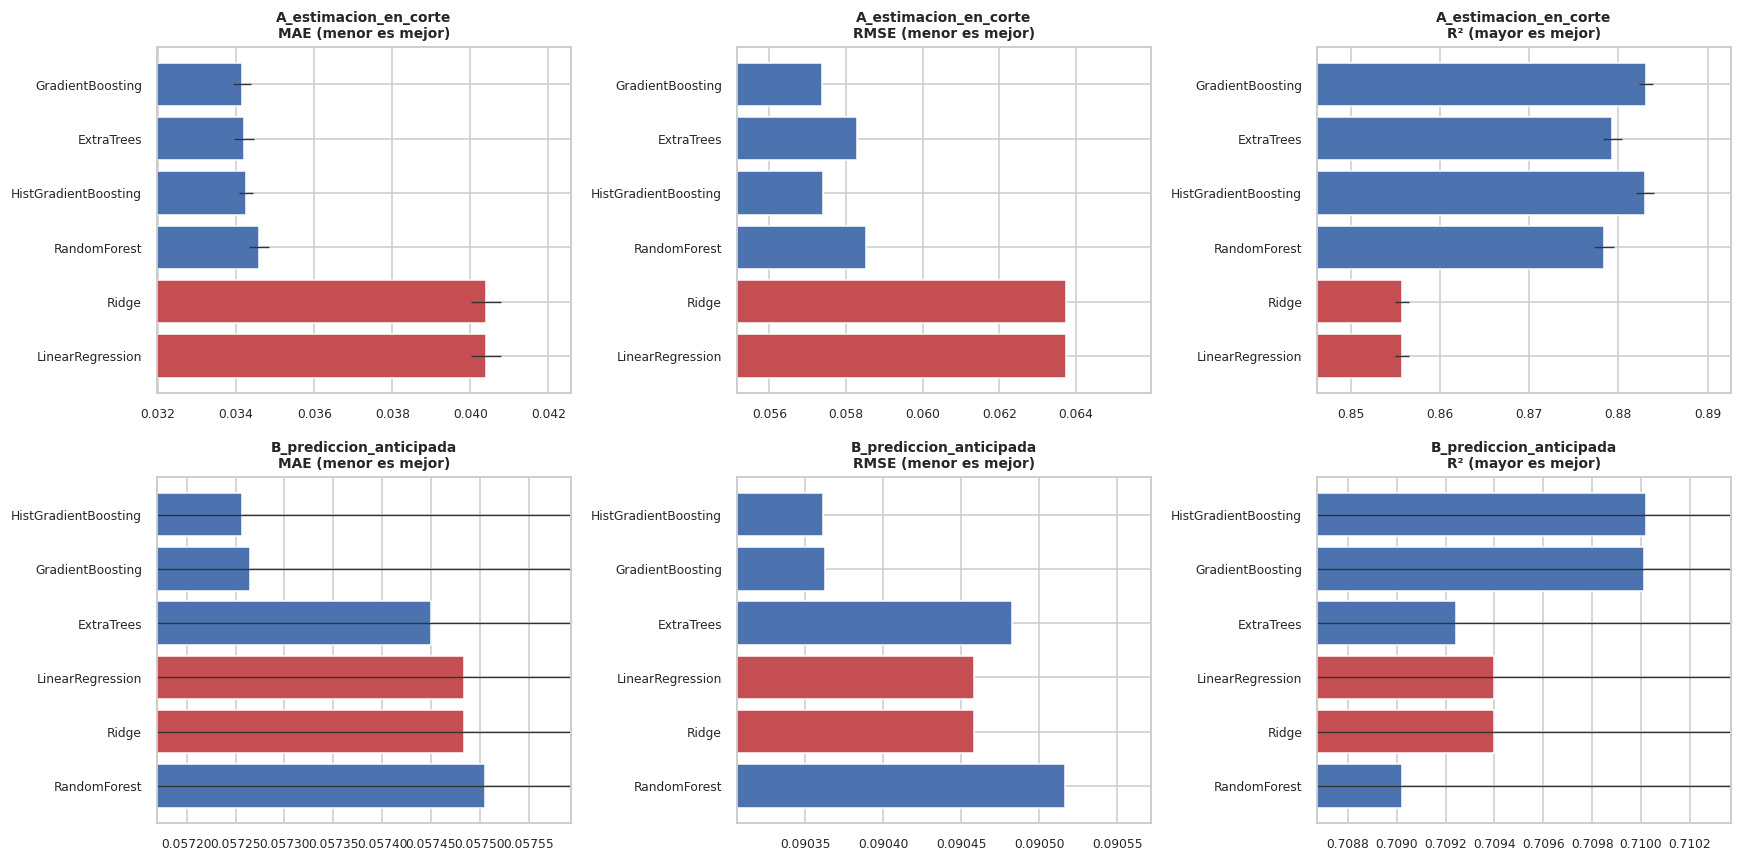

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for i, (esc, t) in enumerate(comparacion.items()):
    t2 = t.iloc[::-1]
    col = ['#C44E52' if m in ('LinearRegression', 'Ridge') else '#4C72B0' for m in t2.modelo]
    for j, (metrica, titulo, err) in enumerate([('MAE', 'MAE (menor es mejor)', 'MAE_sd'),
                                               ('RMSE', 'RMSE (menor es mejor)', None),
                                               ('R2', 'R² (mayor es mejor)', 'R2_sd')]):
        ax[i, j].barh(t2.modelo, t2[metrica], color=col,
                      xerr=(t2[err] if err else None), error_kw={'lw': .9, 'ecolor': '#333'})
        ax[i, j].set_title(f'{esc}\n{titulo}', fontsize=9)
        ax[i, j].tick_params(labelsize=8)
        lo, hi = t2[metrica].min(), t2[metrica].max()
        margen = (hi - lo) * .35 + 1e-6
        ax[i, j].set_xlim(lo - margen, hi + margen)   # escala ajustada: las diferencias son pequeñas
plt.tight_layout()
print('Rojo = modelos lineales   |   Azul = modelos de árboles')
print('Nota: el eje x NO empieza en cero, para que las diferencias (muy pequeñas) sean visibles.')
plt.show()

### Qué resultado obtuvimos

**Escenario A** (10 variables, `GroupKFold` de 5):

| Modelo | MAE | RMSE | R² | R² train | Brecha R² | fit (s) |
|---|---:|---:|---:|---:|---:|---:|
| **GradientBoosting** | **0,03414** | **0,05736** | **0,88318** | 0,88618 | **0,003** | 31,0 |
| HistGradientBoosting | 0,03422 | 0,05738 | 0,88309 | 0,88793 | 0,005 | **0,6** |
| ExtraTrees | 0,03423 | 0,05837 | 0,87899 | 0,91305 | 0,034 | 7,3 |
| RandomForest | 0,03460 | 0,05858 | 0,87814 | 0,91749 | 0,039 | 23,6 |
| LinearRegression | 0,04040 | 0,06374 | 0,85574 | 0,85583 | 0,000 | 0,1 |
| Ridge | 0,04040 | 0,06374 | 0,85574 | 0,85583 | 0,000 | 0,1 |

**Escenario B** (20 variables):

| Modelo | MAE | RMSE | R² | R² train | Brecha R² | fit (s) |
|---|---:|---:|---:|---:|---:|---:|
| **HistGradientBoosting** | **0,05724** | **0,09034** | **0,71020** | 0,71283 | 0,003 | **2,3** |
| GradientBoosting | 0,05728 | 0,09035 | 0,71016 | 0,71326 | 0,003 | 72,2 |
| ExtraTrees | 0,05744 | 0,09046 | 0,70945 | 0,72920 | 0,020 | 36,6 |
| LinearRegression | 0,05748 | 0,09044 | 0,70953 | 0,70984 | 0,000 | 0,5 |
| Ridge | 0,05748 | 0,09044 | 0,70953 | 0,70984 | 0,000 | 0,3 |
| RandomForest | 0,05749 | 0,09048 | 0,70929 | 0,72979 | 0,021 | 53,7 |

### Interpretación: no declaramos un ganador solo por el MAE

Analizamos los cinco criterios que el proyecto exige, porque el MAE por sí solo no decide:

**1. Precisión.** Los dos escenarios dan respuestas opuestas, y ahí está lo interesante:

- En **A**, los árboles baten claramente a los lineales: 0,03414 frente a 0,04040, un **15,5 %
  mejor**. Con solo 10 variables hay no linealidades que un modelo lineal no puede representar.
- En **B**, `LinearRegression` **empata prácticamente con el mejor boosting**: 0,05748 frente a
  0,05724, un **0,4 %** de diferencia, con una desviación entre folds de ±0,0008 que es el triple
  de esa brecha.

El segundo resultado es el importante: **desmiente experimentalmente la idea de que los árboles
son automáticamente superiores**. Cuando la información disponible es esencialmente lineal — como
predijo el análisis Pearson/Spearman de la sección 6 —, no lo son. Y lo decisivo no es la familia
de modelo sino **qué información temporal se le permite usar**: pasar de B a A mejora el MAE un
40 %, mientras que cambiar de familia dentro de B lo mueve un 0,4 %.

**2. Estabilidad.** Las desviaciones entre folds son pequeñas y homogéneas (±0,00035 en A,
±0,00078 en B). Ningún modelo es inestable.

**3. Sobreajuste.** Aquí sí hay diferencias sustanciales. `RandomForest` y `ExtraTrees` muestran
brechas $R^2$ train–test de 0,039 y 0,034 en A, frente a 0,003–0,005 de los dos boosting y 0,000
de los lineales. Los modelos de *bagging* consiguen un MAE competitivo memorizando mucho más.

**4. Coste.** `HistGradientBoosting` ajusta en 0,6 s (A) y 2,3 s (B); `GradientBoosting`, que le
gana por 0,00008 de MAE en A, tarda 30,7 s y 72,2 s: **entre 30 y 50 veces más lento** por una
diferencia indistinguible del ruido (±0,00035). Con 5 folds de validación cruzada y 20 iteraciones
de búsqueda ese factor se multiplica, y en el escenario B llega a excluir a `GradientBoosting` del
tuning por el filtro de 60 s declarado en la sección 16.

**5. Interpretabilidad.** Los lineales son los más transparentes, pero en A pagan un 15 % de
precisión. Los modelos de árboles admiten permutación y *partial dependence* (sección 18), que
cubren la necesidad de interpretabilidad del proyecto sin ese coste.

### Qué decisión tomamos

Los dos modelos de **boosting por gradiente** son los candidatos, y la diferencia entre ellos es
ruido: 0,00008 de MAE frente a ±0,00035 entre folds. Los cinco criterios se reparten así:

| Criterio | Ganador |
|---|---|
| MAE (A) | GradientBoosting, por 0,00008 → **empate técnico** |
| MAE, RMSE, R² (B) | HistGradientBoosting |
| Sobreajuste | Empate (0,003–0,005 ambos) |
| Coste | **HistGradientBoosting, 50× más rápido** |
| Interpretabilidad | Empate |

Llevamos **ambos** a la sección 16 como finalistas y dejamos que la optimización de
hiperparámetros —una prueba independiente, con su propia validación cruzada— decida. No cerramos
la elección aquí, porque hacerlo con una diferencia inferior al ruido sería elegir por preferencia
y no por evidencia.

Lo que sí queda decidido es qué **no** llevamos: `RandomForest` y `ExtraTrees`, por su brecha de
sobreajuste 7–10 veces mayor, y los lineales, por el 15 % de precisión que ceden en A.

---
## 16. Optimización de hiperparámetros

### Qué hacemos
`RandomizedSearchCV` con `GroupKFold` sobre los dos finalistas de cada escenario, y
**comparamos el resultado con el mismo modelo sin optimizar en los mismos folds** para medir
cuánto aporta realmente la búsqueda.

### Por qué RandomizedSearchCV y no GridSearchCV
El espacio de `HistGradientBoosting` tiene 6 hiperparámetros, dos de ellos continuos. Una rejilla
con solo 4 valores por dimensión daría $4^6 = 4.096$ combinaciones × 3 folds ≈ 12.000 ajustes:
inviable. La búsqueda aleatoria explora mejor los espacios continuos con un presupuesto fijo y es
la opción correcta aquí. `GridSearchCV` solo sería preferible con un espacio pequeño y discreto.

### Restricciones de recursos, declaradas explícitamente
El proyecto debe ejecutarse en Google Colab, así que la búsqueda se diseña con un presupuesto:

| Decisión | Valor | Por qué |
|---|---|---|
| Folds en la búsqueda | 3 (en lugar de 5) | El coste es proporcional a los folds. La selección del modelo ya se hizo con 5. |
| Iteraciones (modelos rápidos) | 20 | `HistGradientBoosting` ajusta en ~1–3 s: 20 × 3 = 60 ajustes ≈ 1–2 min. |
| Iteraciones (modelos de árboles) | 8 | `ExtraTrees` ajusta en ~7–35 s: 8 × 3 = 24 ajustes ≈ 3–15 min. |
| Filtro de coste | `fit_s < 60 s` | `GradientBoosting` (31 s/ajuste en A, 63–70 s en B) es el más caro; en B queda excluido por este filtro, y en A entra como finalista porque su coste sigue siendo asumible. |

Los espacios de búsqueda son **deliberadamente acotados** alrededor de valores razonables: rangos
absurdamente amplios desperdician el presupuesto en regiones sin interés.

> **Aviso de comparabilidad.** Los MAE de esta sección se calculan con **3 folds** y no son
> directamente comparables con la tabla de 5 folds de la sección 15. Por eso reportamos, en los
> mismos 3 folds, el modelo con y sin optimizar: esa diferencia sí es interpretable.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

ESPACIOS_BUSQUEDA = {
    'LinearRegression': {},   # sin hiperparametros relevantes
    'Ridge': {'mod__alpha': uniform(0.01, 50.0)},
    'RandomForest': {
        'mod__n_estimators': randint(120, 260), 'mod__max_depth': randint(10, 26),
        'mod__min_samples_split': randint(2, 20), 'mod__min_samples_leaf': randint(1, 12),
        'mod__max_features': ['sqrt', 'log2', 0.5, 1.0]},
    'ExtraTrees': {
        'mod__n_estimators': randint(120, 260), 'mod__max_depth': randint(10, 30),
        'mod__min_samples_split': randint(2, 20), 'mod__min_samples_leaf': randint(1, 12),
        'mod__max_features': ['sqrt', 'log2', 0.5, 1.0]},
    'GradientBoosting': {
        'mod__n_estimators': randint(120, 320), 'mod__learning_rate': uniform(0.03, 0.17),
        'mod__max_depth': randint(3, 7), 'mod__min_samples_leaf': randint(1, 15),
        'mod__subsample': uniform(0.7, 0.3)},
    'HistGradientBoosting': {
        'mod__max_iter': randint(200, 700), 'mod__learning_rate': uniform(0.03, 0.15),
        'mod__max_depth': [None, 6, 8, 12], 'mod__min_samples_leaf': randint(10, 60),
        'mod__l2_regularization': uniform(0.0, 1.5), 'mod__max_leaf_nodes': randint(15, 64)},
}
MODELOS_LENTOS = {'RandomForest', 'ExtraTrees', 'GradientBoosting'}


def optimizar(cols, tabla_comparacion, cv=CV_TUNING):
    """Optimiza los 2 finalistas viables por coste y mide la mejora real del tuning."""
    viables = tabla_comparacion[tabla_comparacion.fit_s < CONFIG['LIMITE_FIT_S']]
    excluidos = tabla_comparacion[tabla_comparacion.fit_s >= CONFIG['LIMITE_FIT_S']]
    finalistas = viables.modelo.head(2).tolist()
    print(f'  excluidos por coste (>{CONFIG["LIMITE_FIT_S"]:.0f} s/ajuste): '
          f'{list(zip(excluidos.modelo, excluidos.fit_s.round(1)))}')
    print(f'  finalistas: {finalistas}\n')

    modelos = definir_modelos()
    filas = {}
    for nombre in finalistas:
        espacio = ESPACIOS_BUSQUEDA[nombre]
        base_pipe = lambda: Pipeline([('prep', construir_preprocesador(cols)),
                                      ('mod', definir_modelos()[nombre])])
        # (a) sin optimizar, en los MISMOS folds -> linea de referencia comparable
        r0 = cross_validate(base_pipe(), df_train[cols], y_train, groups=grupos_train, cv=cv,
                            scoring='neg_mean_absolute_error', n_jobs=1)
        mae_sin = float(-r0['test_score'].mean())

        # (b) optimizado
        if not espacio:
            mae_con, mejores = mae_sin, {}
        else:
            n_iter = CONFIG['N_ITER_ARBOLES'] if nombre in MODELOS_LENTOS else CONFIG['N_ITER_RAPIDOS']
            busq = RandomizedSearchCV(base_pipe(), espacio, n_iter=n_iter, cv=cv,
                                      scoring='neg_mean_absolute_error',
                                      random_state=RANDOM_STATE, n_jobs=1, refit=False)
            t0 = time.time()
            busq.fit(df_train[cols], y_train, groups=grupos_train)
            mae_con, mejores = float(-busq.best_score_), busq.best_params_
            print(f'  {nombre}: {n_iter} iteraciones en {time.time()-t0:.0f} s')

        filas[nombre] = {'MAE_sin_tuning': mae_sin, 'MAE_con_tuning': mae_con,
                         'mejora': mae_sin - mae_con, 'mejores_params': mejores}
        print(f'  {nombre:<22} MAE {mae_sin:.5f} -> {mae_con:.5f}  (mejora {mae_sin-mae_con:+.5f})')
        for k, v in mejores.items():
            print(f'      {k.replace("mod__",""):<22} = {v}')
        print()
    return filas


optimizacion, CAMPEON = {}, {}
for esc, cols in VARIABLES_FINALES.items():
    print(f'\n{"="*78}\n{esc}\n{"="*78}')
    optimizacion[esc] = optimizar(cols, comparacion[esc])
    CAMPEON[esc] = min(optimizacion[esc], key=lambda k: optimizacion[esc][k]['MAE_con_tuning'])
    print(f'  ==> CAMPEON: {CAMPEON[esc]} '
          f'(MAE 3-fold = {optimizacion[esc][CAMPEON[esc]]["MAE_con_tuning"]:.5f})')


A_estimacion_en_corte
  excluidos por coste (>60 s/ajuste): []
  finalistas: ['GradientBoosting', 'ExtraTrees']

  GradientBoosting: 8 iteraciones en 872 s
  GradientBoosting       MAE 0.03422 -> 0.03405  (mejora +0.00018)
      learning_rate          = 0.03793316274631462
      max_depth              = 6
      min_samples_leaf       = 14
      n_estimators           = 309
      subsample              = 0.935552788417904

  ExtraTrees: 8 iteraciones en 199 s
  ExtraTrees             MAE 0.03424 -> 0.03388  (mejora +0.00036)
      max_depth              = 13
      max_features           = 1.0
      min_samples_leaf       = 8
      min_samples_split      = 4
      n_estimators           = 172

  ==> CAMPEON: ExtraTrees (MAE 3-fold = 0.03388)

B_prediccion_anticipada
  excluidos por coste (>60 s/ajuste): [('GradientBoosting', 108.5), ('ExtraTrees', 82.2), ('RandomForest', 114.2)]
  finalistas: ['HistGradientBoosting', 'LinearRegression']

  HistGradientBoosting: 20 iteraciones en 313 s
 

---
## 17. Evaluación final sobre el conjunto de prueba

### Qué hacemos
Entrenamos el modelo campeón de cada escenario **solo con el conjunto de entrenamiento** y lo
evaluamos **una única vez** sobre el conjunto de prueba reservado en la sección 12.

### Por qué una sola vez
El conjunto de prueba solo da una estimación no sesgada del rendimiento mientras no se use para
tomar decisiones. Cada vez que se mira el test y se cambia algo en función de lo que se ve, se
consume parte de su validez. Todas las decisiones — variables, familia de modelo,
hiperparámetros — se tomaron con validación cruzada **dentro** del entrenamiento. El test se
toca aquí y no vuelve a usarse para decidir nada.

### Metodología del recorte a [0, 1]
Medimos cuántas predicciones caen fuera del rango **antes** de recortar, y luego aplicamos
`np.clip(pred, 0, 1)`. El recorte está justificado porque el target está acotado por
construcción: una predicción de 1,03 es matemáticamente imposible como nivel de conocimiento, y
recortarla nunca puede aumentar el error absoluto frente al valor real. Reportamos el conteo en
lugar de asumir que es cero.

In [ ]:
def entrenar_modelo_final(cols, nombre_modelo, mejores_params):
    """Ajusta el pipeline completo (preprocesamiento + modelo) solo con train."""
    modelo = definir_modelos()[nombre_modelo]
    params = {k.replace('mod__', ''): v for k, v in mejores_params.items()}
    if params:
        modelo.set_params(**params)
    pipe = Pipeline([('prep', construir_preprocesador(cols)), ('mod', modelo)])
    t0 = time.time()
    pipe.fit(df_train[cols], y_train)
    return pipe, round(time.time() - t0, 1)


def evaluar_modelo(pipe, cols, rango=CONFIG['RANGO_TARGET']):
    """Evalua en train y test. Cuenta las predicciones fuera de rango ANTES de recortar."""
    crudo_te = pipe.predict(df_test[cols])
    crudo_tr = pipe.predict(df_train[cols])
    n_fuera = int(((crudo_te < rango[0]) | (crudo_te > rango[1])).sum())
    pred_te = np.clip(crudo_te, *rango)
    pred_tr = np.clip(crudo_tr, *rango)
    return {'test': calcular_metricas(y_test, pred_te),
            'train': calcular_metricas(y_train, pred_tr),
            'pred_test': pred_te, 'pred_train': pred_tr,
            'n_fuera_rango': n_fuera,
            'pct_fuera_rango': round(n_fuera / len(crudo_te) * 100, 4)}


modelos_finales, evaluaciones = {}, {}
for esc, cols in VARIABLES_FINALES.items():
    nombre = CAMPEON[esc]
    pipe, t_fit = entrenar_modelo_final(cols, nombre, optimizacion[esc][nombre]['mejores_params'])
    ev = evaluar_modelo(pipe, cols)
    modelos_finales[esc], evaluaciones[esc] = pipe, ev

    print(f'\n{"="*78}\n{esc}  —  modelo final: {nombre}  ({len(cols)} variables, ajuste {t_fit}s)\n{"="*78}')
    tabla = pd.DataFrame({'TEST': ev['test'], 'TRAIN': ev['train']}).T
    print(tabla.to_string())
    print(f'\n  brecha R2 (train - test) : {ev["train"]["R2"] - ev["test"]["R2"]:+.5f}')
    print(f'  brecha MAE (test - train): {ev["test"]["MAE"] - ev["train"]["MAE"]:+.5f}')
    print(f'  predicciones fuera de [0,1] antes del recorte: '
          f'{ev["n_fuera_rango"]} ({ev["pct_fuera_rango"]} %)')


A_estimacion_en_corte  —  modelo final: ExtraTrees  (10 variables, ajuste 14.6s)
         MAE    MSE   RMSE     R2  MedAE
TEST  0.0335 0.0032 0.0564 0.8859 0.0148
TRAIN 0.0327 0.0031 0.0556 0.8901 0.0140

  brecha R2 (train - test) : +0.00420
  brecha MAE (test - train): +0.00076
  predicciones fuera de [0,1] antes del recorte: 0 (0.0 %)

B_prediccion_anticipada  —  modelo final: HistGradientBoosting  (20 variables, ajuste 8.2s)
         MAE    MSE   RMSE     R2  MedAE
TEST  0.0565 0.0080 0.0893 0.7140 0.0302
TRAIN 0.0566 0.0081 0.0899 0.7131 0.0298

  brecha R2 (train - test) : -0.00089
  brecha MAE (test - train): -0.00010
  predicciones fuera de [0,1] antes del recorte: 0 (0.0 %)


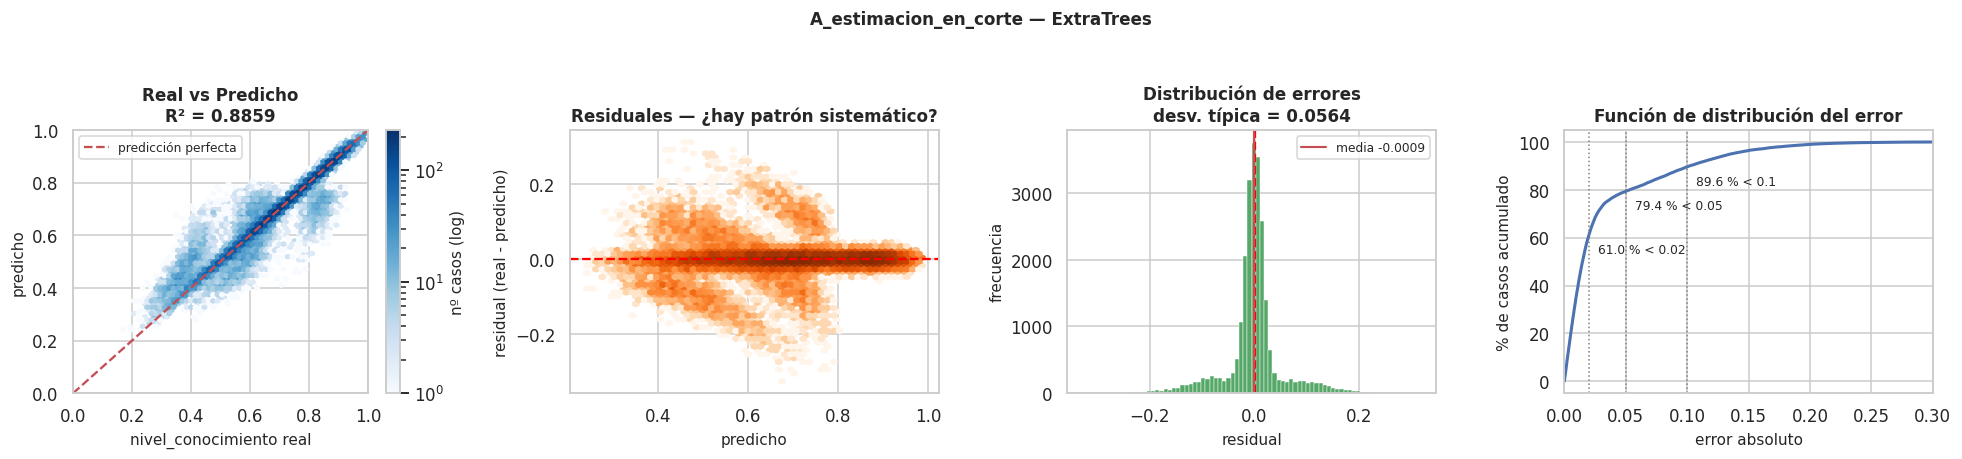

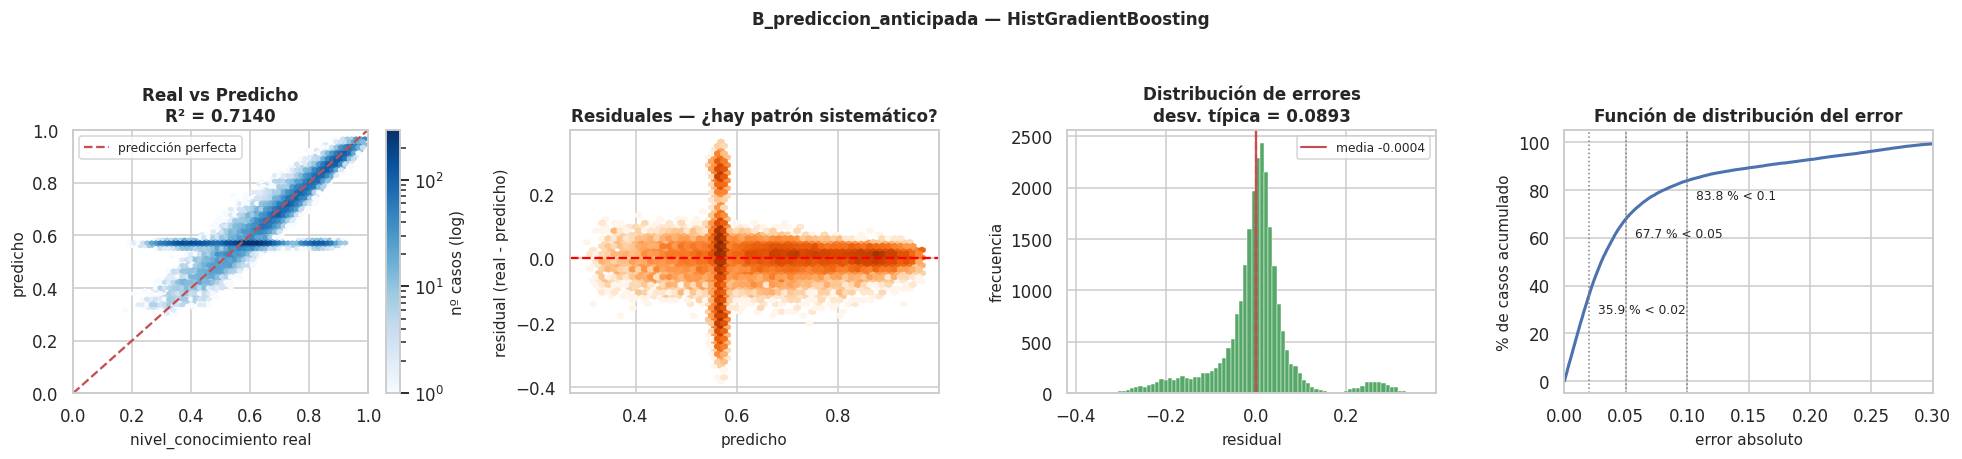

In [ ]:
def graficar_evaluacion(esc, cols):
    """Real vs predicho, residuales y distribucion de errores."""
    ev = evaluaciones[esc]
    p, resid = ev['pred_test'], y_test - ev['pred_test']
    fig, ax = plt.subplots(1, 4, figsize=(18, 4))

    # 1. real vs predicho (hexbin: 25k puntos serian una mancha con scatter)
    hb = ax[0].hexbin(y_test, p, gridsize=55, cmap='Blues', mincnt=1, bins='log')
    ax[0].plot([0, 1], [0, 1], 'r--', lw=1.5, label='predicción perfecta')
    ax[0].set_xlabel('nivel_conocimiento real'); ax[0].set_ylabel('predicho')
    ax[0].set_title(f'Real vs Predicho\nR² = {ev["test"]["R2"]:.4f}')
    ax[0].legend(fontsize=8); ax[0].set_xlim(0, 1); ax[0].set_ylim(0, 1)
    plt.colorbar(hb, ax=ax[0], label='nº casos (log)')

    # 2. residuales vs predicho
    ax[1].hexbin(p, resid, gridsize=55, cmap='Oranges', mincnt=1, bins='log')
    ax[1].axhline(0, color='red', ls='--', lw=1.5)
    ax[1].set_xlabel('predicho'); ax[1].set_ylabel('residual (real - predicho)')
    ax[1].set_title('Residuales — ¿hay patrón sistemático?')

    # 3. distribucion de errores
    ax[2].hist(resid, bins=80, color='#55A868', edgecolor='white', linewidth=.3)
    ax[2].axvline(0, color='red', ls='--', lw=1.5)
    ax[2].axvline(resid.mean(), color='#C44E52', ls='-', lw=1.4,
                  label=f'media {resid.mean():+.4f}')
    ax[2].set_xlabel('residual'); ax[2].set_ylabel('frecuencia')
    ax[2].set_title(f'Distribución de errores\ndesv. típica = {resid.std():.4f}')
    ax[2].legend(fontsize=8)

    # 4. error absoluto acumulado
    ae = np.sort(np.abs(resid))
    ax[3].plot(ae, np.arange(1, len(ae) + 1) / len(ae) * 100, lw=2, color='#4C72B0')
    for u in (0.02, 0.05, 0.10):
        pct = (np.abs(resid) < u).mean() * 100
        ax[3].axvline(u, color='grey', ls=':', lw=1)
        ax[3].annotate(f'{pct:.1f} % < {u}', (u, pct), fontsize=8,
                       xytext=(6, -12), textcoords='offset points')
    ax[3].set_xlabel('error absoluto'); ax[3].set_ylabel('% de casos acumulado')
    ax[3].set_title('Función de distribución del error'); ax[3].set_xlim(0, .3)

    plt.suptitle(f'{esc} — {CAMPEON[esc]}', fontsize=11, y=1.04, fontweight='semibold')
    plt.tight_layout(); plt.show()


for esc, cols in VARIABLES_FINALES.items():
    graficar_evaluacion(esc, cols)

---
## 18. Interpretabilidad del modelo

### Qué hacemos
Combinamos **permutation importance** (qué variables importan, ya calculada en la sección 13) con
**partial dependence** (cuál es la *forma* del efecto) para responder a preguntas concretas sobre
el comportamiento del modelo.

### Por qué las dos y no solo una
La permutación dice *cuánto* importa una variable, pero no *cómo*. Que
`tiempo_promedio_ultimo_periodo` tenga importancia 0,0002 no aclara si más tiempo se asocia a más
o a menos nivel. El *partial dependence plot* muestra la relación completa y revela no
linealidades, saturaciones y umbrales que un único número no puede transmitir.

### Advertencia obligatoria sobre causalidad
Todo lo que sigue habla de **asociación e importancia predictiva**, nunca de causalidad. Que el
modelo use `tiempo_promedio_general` para bajar su predicción **no significa** que responder
despacio *cause* un nivel de conocimiento bajo. La relación es correlacional y admite múltiples
explicaciones: una variable latente de dominio puede producir simultáneamente respuestas rápidas
y aciertos. Un *partial dependence plot* describe el **comportamiento del modelo**, no un
mecanismo del mundo.

In [ ]:
from sklearn.inspection import partial_dependence

def graficar_dependencia_parcial(esc, cols, n_vars=4, n_muestra=6000):
    """Partial dependence de las variables mas importantes segun permutacion."""
    pipe = modelos_finales[esc]
    orden = [c for c in importancias[esc]['permutacion'].feature
             if c in cols and c not in VARIABLES_CATEGORICAS][:n_vars]
    rs = np.random.RandomState(RANDOM_STATE)
    sub = rs.choice(len(df_test), size=min(n_muestra, len(df_test)), replace=False)
    X = df_test.iloc[sub][cols].copy()

    # Dos ajustes tecnicos imprescindibles, ambos silenciosos si se omiten:
    # 1) partial_dependence escribe los valores (continuos) de la rejilla en la columna;
    #    si la columna es de tipo entero, la asignacion falla con TypeError.
    for c in X.columns:
        if pd.api.types.is_integer_dtype(X[c]):
            X[c] = X[c].astype('float64')

    fig, ax = plt.subplots(1, len(orden), figsize=(4.1 * len(orden), 3.5))
    ax = np.atleast_1d(ax)
    for i, c in enumerate(orden):
        # 2) la rejilla se construye con percentiles de la columna. Si la variable tiene
        #    nulos (las historicas los tienen en el periodo 1), el percentil sale NaN,
        #    la rejilla entera es NaN y el PDP sale PLANO sin avisar de nada.
        #    Se calcula por tanto sobre las filas donde la variable existe.
        Xc = X[X[c].notna()] if X[c].isna().any() else X
        nota = f'  (n={len(Xc):,} filas donde existe)' if len(Xc) < len(X) else ''
        r = partial_dependence(pipe, Xc, features=[c], grid_resolution=25, kind='average')
        ax[i].plot(r['grid_values'][0], r['average'][0], lw=2.4, color='#4C72B0')
        ax[i].set_xlabel(c, fontsize=8.5)
        ax[i].set_ylabel('nivel_conocimiento predicho' if i == 0 else '')
        ax[i].set_title(f'{c}{nota}', fontsize=8.5)
        ax[i].grid(alpha=.3)
    plt.suptitle(f'{esc} — dependencia parcial (asociación, NO causalidad)',
                 fontsize=10.5, y=1.05, fontweight='semibold')
    plt.tight_layout(); plt.show()
    return orden


for esc, cols in VARIABLES_FINALES.items():
    graficar_dependencia_parcial(esc, cols)

In [ ]:
# Tabla unificada de importancia: feature | importancia | metodo
filas = []
for esc in ESCENARIOS:
    for clave, etiqueta in [('permutacion', 'permutation (MAE, sobre test)'),
                            ('impureza', 'impureza (ExtraTrees)'),
                            ('coeficientes', 'coef. estandarizado (Ridge)')]:
        t = importancias[esc][clave].head(6)
        for _, r in t.iterrows():
            filas.append({'escenario': esc.split('_')[0], 'feature': r.feature,
                          'importancia': round(r.importancia, 6), 'metodo': etiqueta})
tabla_importancia = pd.DataFrame(filas)
print('TABLA DE IMPORTANCIA DE CARACTERISTICAS (top 6 por metodo y escenario)')
print(tabla_importancia.to_string(index=False))

---
## 19. Análisis de errores, subgrupos y sobreajuste

### Qué hacemos
Desagregamos el error del conjunto de prueba por cinco dimensiones (periodo, cantidad de
historial, rango de nivel real, área y concepto), inspeccionamos los casos de error máximo y
mínimo, y comparamos entrenamiento, validación cruzada y prueba para detectar sobreajuste.

### Por qué una métrica global no basta
Un MAE global es una media, y las medias esconden regímenes. Un modelo con MAE 0,034 puede ser
excelente en el 70 % de los casos y desastroso en el 30 % restante — y si ese 30 % son
precisamente los estudiantes nuevos, el modelo es inservible para el caso de uso que más importa.
Este es el análisis que lo detecta.

In [ ]:
def analizar_errores(esc, cols):
    """Desagrega el error por periodo, historial, rango de nivel, area y concepto."""
    e = df_test.copy()
    e['pred'] = evaluaciones[esc]['pred_test']
    e['error'] = e[CONFIG['TARGET']] - e.pred
    e['error_abs'] = e.error.abs()

    def resumir(agrupado):
        return agrupado.agg(n=('error_abs', 'size'), MAE=('error_abs', 'mean'),
                            RMSE=('error', lambda s: float(np.sqrt((s ** 2).mean()))),
                            sesgo=('error', 'mean')).round(5)

    res = {
        'por periodo': resumir(e.groupby(e.numero_periodo.clip(upper=8).rename('periodo'), observed=True)),
        'por cantidad de historial (preguntas acumuladas)':
            resumir(e.groupby(pd.cut(e.preguntas_total_general, [-1, 0, 15, 45, 90, 10**5],
                                     labels=['0 (sin historial)', '1-15', '16-45', '46-90', '> 90']),
                              observed=True)),
        'por rango de nivel real':
            resumir(e.groupby(pd.cut(e[CONFIG['TARGET']], [0, .4, .55, .7, .85, 1.0]), observed=True)),
        'por area': resumir(e.groupby('area', observed=True)).sort_values('MAE'),
    }
    concepto = resumir(e.groupby('concepto', observed=True)).sort_values('MAE')
    res['5 conceptos con menor error'] = concepto.head(5)
    res['5 conceptos con mayor error'] = concepto.tail(5)

    for titulo, tabla in res.items():
        print(f'\n--- {titulo} ---')
        print(tabla.to_string())

    print(f'\n--- residuos globales ---')
    print(f'  media            : {e.error.mean():+.5f}   (0 = sin sesgo global)')
    print(f'  desviacion tipica: {e.error.std():.5f}')
    print(f'  percentil 5 / 95 : {e.error.quantile(.05):+.5f} / {e.error.quantile(.95):+.5f}')
    print(f'  error absoluto maximo: {e.error_abs.max():.5f}')
    print(f'  casos con |error| < 0.05: {(e.error_abs < .05).mean()*100:.2f} %')
    print(f'  casos con |error| < 0.10: {(e.error_abs < .10).mean()*100:.2f} %')

    print(f'\n--- 5 casos con MAYOR error ---')
    print(e.nlargest(5, 'error_abs')[['concepto', 'numero_periodo', CONFIG['TARGET'],
                                      'pred', 'error_abs']].to_string(index=False))
    print(f'\n--- 5 casos con MENOR error ---')
    print(e.nsmallest(5, 'error_abs')[['concepto', 'numero_periodo', CONFIG['TARGET'],
                                       'pred', 'error_abs']].to_string(index=False))
    return e, res


errores = {}
for esc, cols in VARIABLES_FINALES.items():
    print(f'\n{"="*92}\nANALISIS DE ERRORES — {esc} ({CAMPEON[esc]})\n{"="*92}')
    errores[esc] = analizar_errores(esc, cols)

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for i, esc in enumerate(VARIABLES_FINALES):
    e = errores[esc][0]

    # MAE por periodo
    t = e.groupby(e.numero_periodo.clip(upper=8), observed=True).error_abs.mean()
    ax[i, 0].bar(t.index.astype(str), t.values, color='#4C72B0')
    ax[i, 0].set_title(f'{esc}\nMAE por periodo', fontsize=9)
    ax[i, 0].set_xlabel('numero_periodo (8 = 8 o más)'); ax[i, 0].set_ylabel('MAE')

    # MAE y sesgo por rango de nivel real
    b = pd.cut(e[CONFIG['TARGET']], [0, .4, .55, .7, .85, 1.0])
    g = e.groupby(b, observed=True).agg(MAE=('error_abs', 'mean'), sesgo=('error', 'mean'))
    x = np.arange(len(g))
    ax[i, 1].bar(x - .2, g.MAE, width=.4, label='MAE', color='#4C72B0')
    ax[i, 1].bar(x + .2, g.sesgo, width=.4, label='sesgo medio', color='#DD8452')
    ax[i, 1].axhline(0, color='black', lw=.8)
    ax[i, 1].set_xticks(x); ax[i, 1].set_xticklabels([str(v) for v in g.index], fontsize=7.5, rotation=20)
    ax[i, 1].set_title(f'{esc}\nMAE y sesgo por rango de nivel real', fontsize=9)
    ax[i, 1].legend(fontsize=8)

    # MAE por area
    t3 = e.groupby('area', observed=True).error_abs.mean().sort_values()
    ax[i, 2].barh(t3.index, t3.values, color='#55A868')
    ax[i, 2].set_title(f'{esc}\nMAE por área', fontsize=9)
    ax[i, 2].set_xlabel('MAE'); ax[i, 2].tick_params(labelsize=7.5)
    ax[i, 2].set_xlim(t3.min() * .95, t3.max() * 1.03)
plt.tight_layout(); plt.show()

In [ ]:
print('COMPROBACION DE SOBREAJUSTE: train vs validacion cruzada vs test\n')
filas = []
for esc, cols in VARIABLES_FINALES.items():
    nombre = CAMPEON[esc]
    ev = evaluaciones[esc]
    fila_cv = comparacion[esc].set_index('modelo').loc[nombre]
    filas.append({
        'escenario': esc, 'modelo': nombre,
        'MAE_train': ev['train']['MAE'],
        'MAE_cv_5folds': fila_cv.MAE,
        'MAE_test': ev['test']['MAE'],
        'R2_train': ev['train']['R2'],
        'R2_cv_5folds': fila_cv.R2,
        'R2_test': ev['test']['R2'],
        'brecha_R2_train_test': ev['train']['R2'] - ev['test']['R2'],
    })
tabla_overfit = pd.DataFrame(filas)
print(tabla_overfit.T.to_string())
print('\nCriterio: una brecha R2 train-test > 0.05 indicaria sobreajuste que exige actuar')
for _, r in tabla_overfit.iterrows():
    veredicto = ('SIN sobreajuste apreciable' if abs(r.brecha_R2_train_test) < 0.02
                 else 'sobreajuste LEVE' if r.brecha_R2_train_test < 0.05 else 'SOBREAJUSTE — actuar')
    print(f'  {r.escenario:<26} brecha = {r.brecha_R2_train_test:+.5f}  ->  {veredicto}')

---
## 20. Entrenamiento del modelo definitivo
## 21. Guardado del modelo y sus metadatos

### Qué hacemos
Empaquetamos el pipeline completo — preprocesamiento, selección de variables implícita y
modelo — en un único artefacto serializado con `joblib`, acompañado de todos los metadatos
necesarios para auditarlo y reproducirlo.

### Arquitectura del artefacto

```
Pipeline
  ├── ColumnTransformer ('prep')
  │     ├── num:  SimpleImputer(median, add_indicator) → StandardScaler
  │     └── cat:  SimpleImputer(most_frequent) → OneHotEncoder(handle_unknown='ignore')
  └── Modelo ('mod')  ← campeón optimizado
```

La selección de características no es un paso del pipeline sino la **lista de columnas de
entrada**, que se guarda en los metadatos: el pipeline recibe exactamente esas columnas y en ese
orden. Es más simple y más transparente que un `SelectKBest` interno, y evita que el artefacto
dependa de un estado de selección aprendido.

### Por qué guardamos el pipeline entero y no solo el modelo
Si guardáramos solo el estimador, en producción habría que reimplementar la imputación, el
escalado y la codificación — y cualquier divergencia mínima (otra mediana, otro orden de
categorías) produciría predicciones silenciosamente incorrectas. Al serializar el `Pipeline`
completo, **las transformaciones viajan con sus parámetros aprendidos del entrenamiento**, y el
*training/serving skew* queda eliminado por construcción.

### Metadatos que acompañan al modelo
Lista exacta de variables y su orden, nombre y familia del modelo, hiperparámetros, métricas de
test y train, versión del modelo, fecha de entrenamiento, `random_state`, estrategia de
partición, rango de salida y versiones de las librerías.

In [ ]:
def guardar_modelo(esc, cols, ruta=None):
    """Serializa el pipeline y sus metadatos en un unico artefacto auditable."""
    nombre = CAMPEON[esc]
    ev = evaluaciones[esc]
    ruta = ruta or f'modelo_nivel_conocimiento_{esc}.pkl'
    artefacto = {
        'pipeline'            : modelos_finales[esc],
        'features'            : list(cols),
        'n_features'          : len(cols),
        'modelo'              : nombre,
        'hiperparametros'     : {k.replace('mod__', ''): v for k, v in
                                 optimizacion[esc][nombre]['mejores_params'].items()},
        'escenario'           : esc,
        'target'              : CONFIG['TARGET'],
        'rango_salida'        : list(CONFIG['RANGO_TARGET']),
        'metricas_test'       : ev['test'],
        'metricas_train'      : ev['train'],
        'version_modelo'      : '1.0.0',
        'fecha_entrenamiento' : datetime.datetime.now().isoformat(timespec='seconds'),
        'random_state'        : RANDOM_STATE,
        'estrategia_split'    : f'GroupShuffleSplit por id_estudiante, test_size={CONFIG["TEST_SIZE"]}',
        'estrategia_cv'       : f'GroupKFold({CONFIG["N_FOLDS_CV"]}) agrupado por id_estudiante',
        'n_train'             : int(len(df_train)),
        'n_test'              : int(len(df_test)),
        'versiones'           : {'python': sys.version.split()[0], 'numpy': np.__version__,
                                 'pandas': pd.__version__, 'scikit-learn': sklearn.__version__},
    }
    joblib.dump(artefacto, ruta)
    print(f'  guardado: {ruta}  ({os.path.getsize(ruta)/1024:.0f} KB)')
    return ruta, artefacto


print('GUARDADO DE MODELOS\n')
rutas, artefactos = {}, {}
for esc, cols in VARIABLES_FINALES.items():
    rutas[esc], artefactos[esc] = guardar_modelo(esc, cols)

# Verificacion: recargar y comprobar que reproduce las mismas predicciones
print('\nVERIFICACION DE INTEGRIDAD (recarga y comparacion de predicciones)')
for esc, ruta in rutas.items():
    a = joblib.load(ruta)
    p_recargado = np.clip(a['pipeline'].predict(df_test[a['features']]), *a['rango_salida'])
    identico = np.allclose(p_recargado, evaluaciones[esc]['pred_test'])
    print(f'  {esc:<26} predicciones identicas tras recargar: {identico}')
    assert identico, 'El modelo recargado no reproduce las predicciones originales'

---
## 22. Función de predicción y ejemplo de inferencia

### Qué hacemos
Implementamos `predecir_nivel_conocimiento()`, una función de inferencia lista para producción, y
la ejecutamos sobre casos reales extraídos del conjunto de prueba.

### Requisitos que cumple la función

| Requisito | Implementación |
|---|---|
| Acepta un solo caso o un lote | Normaliza `dict`, `Series` o `DataFrame` a `DataFrame` |
| Valida las variables de entrada | Comprueba que estén todas; error explícito si falta alguna |
| Respeta el orden de columnas | Reindexa según `features` del artefacto, no según el orden recibido |
| Garantiza el rango $[0,1]$ | `np.clip` + aviso cuando la salida cruda salía del rango |
| Es trazable | Devuelve el valor, si fue recortado, y la versión del modelo |

### Estrategia para garantizar $0 \le \hat{y} \le 1$, y por qué es la correcta

Los modelos de árboles **no pueden** por construcción salir del rango de $y$ observado en el
entrenamiento (predicen medias de hojas), así que en la práctica el recorte casi nunca actúa —
la sección 17 midió **0 predicciones fuera de rango**. Aun así lo aplicamos, por tres razones:

1. **Corrección matemática:** el target está acotado por definición. Como el valor real siempre
   está en $[0,1]$, recortar hacia el intervalo nunca puede alejar la predicción del valor real:
   el error absoluto solo puede disminuir o quedar igual. El recorte es una proyección sobre el
   dominio válido, no un parche.
2. **Robustez ante cambios de modelo:** si en una versión futura se sustituyera el campeón por un
   modelo lineal (que sí extrapola), el recorte ya estaría en su sitio.
3. **Transparencia:** cuando el recorte actúa, la función lo señaliza en la respuesta en lugar de
   ocultarlo, lo que permite monitorizarlo como indicador de deriva de datos.

Descartamos las alternativas: una transformación *logit* del target complicaría la interpretación
del MAE y no puede representar los valores 0 y 1; una función de pérdida acotada requeriría un
modelo a medida sin ganancia medible en este problema.

In [ ]:
def predecir_nivel_conocimiento(datos_estudiante, artefacto, avisar_recorte=True):

    lo, hi = artefacto['rango_salida']
    features = artefacto['features']

    # --- normalizacion de la entrada ---
    if isinstance(datos_estudiante, dict):
        X, un_solo_caso = pd.DataFrame([datos_estudiante]), True
    elif isinstance(datos_estudiante, pd.Series):
        X, un_solo_caso = datos_estudiante.to_frame().T, True
    elif isinstance(datos_estudiante, pd.DataFrame):
        X, un_solo_caso = datos_estudiante.copy(), False
    else:
        raise TypeError(f'Tipo no soportado: {type(datos_estudiante)}. '
                        'Use dict, pd.Series o pd.DataFrame.')

    # --- validacion de variables ---
    faltantes = [c for c in features if c not in X.columns]
    if faltantes:
        raise ValueError(f'Faltan {len(faltantes)} variables requeridas: {faltantes}')

    # --- orden canonico de columnas (no el orden recibido) ---
    X = X[features]

    # --- inferencia y garantia de rango ---
    crudo = artefacto['pipeline'].predict(X)
    recortado = (crudo < lo) | (crudo > hi)
    pred = np.clip(crudo, lo, hi)
    if avisar_recorte and recortado.any():
        print(f'  [aviso] {recortado.sum()} prediccion(es) fuera de [{lo}, {hi}] recortadas al rango')

    salida = pd.DataFrame({'nivel_conocimiento_predicho': pred,
                           'recortado': recortado,
                           'modelo': artefacto['modelo'],
                           'version_modelo': artefacto['version_modelo']}, index=X.index)
    return salida.iloc[0].to_dict() if un_solo_caso else salida


# --- Prueba de las validaciones ---
print('PRUEBAS DE VALIDACION DE LA FUNCION\n')
art_A = artefactos['A_estimacion_en_corte']
try:
    predecir_nivel_conocimiento({'numero_periodo': 3}, art_A)
except ValueError as err:
    print(f'  [OK] Variables faltantes detectadas: {str(err)[:78]}...')
try:
    predecir_nivel_conocimiento('texto invalido', art_A)
except TypeError as err:
    print(f'  [OK] Tipo invalido rechazado: {str(err)[:78]}...')

In [ ]:
# ---------------------------------------------------------------------------
# EJEMPLO DE INFERENCIA CON CASOS REALES DEL CONJUNTO DE PRUEBA
# ---------------------------------------------------------------------------
rs = np.random.RandomState(RANDOM_STATE)
for esc in VARIABLES_FINALES:
    art = artefactos[esc]
    print(f'\n{"="*86}\nEJEMPLOS DE INFERENCIA — {esc}  ({art["modelo"]})\n{"="*86}')

    # un caso sin historial (periodo 1) y dos con historial: los dos regimenes del problema
    cand_p1 = df_test.index[df_test.numero_periodo == 1]
    cand_pn = df_test.index[df_test.numero_periodo >= 4]
    elegidos = [rs.choice(cand_p1)] + list(rs.choice(cand_pn, 2, replace=False))

    for k, idx in enumerate(elegidos, 1):
        fila = df_test.loc[idx]
        res = predecir_nivel_conocimiento(fila, art)
        real, pred = fila[CONFIG['TARGET']], res['nivel_conocimiento_predicho']
        print(f'\n--- Caso {k}: {fila.concepto} / {fila.area} / periodo {fila.numero_periodo} ---')
        print('  Caracteristicas de entrada:')
        for c in art['features']:
            v = fila[c]
            print(f'    {c:<36} = {"(sin dato)" if pd.isna(v) else (f"{v:.4f}" if isinstance(v, float) else v)}')
        print(f'\n  Preprocesamiento -> Modelo -> Prediccion')
        print(f'    Nivel de conocimiento estimado : {pred:.4f}')
        print(f'    Valor real observado           : {real:.4f}')
        print(f'    Error absoluto                 : {abs(real - pred):.4f}')
        print(f'    Recortado al rango [0,1]       : {res["recortado"]}')

    # inferencia en lote
    lote = df_test.sample(500, random_state=RANDOM_STATE)
    t0 = time.time()
    salida = predecir_nivel_conocimiento(lote, art)
    dt = time.time() - t0
    print(f'\n--- Inferencia en lote (500 casos) ---')
    print(f'    tiempo total: {dt*1000:.0f} ms  ({dt/500*1000:.3f} ms por caso)')
    print(f'    MAE del lote: {np.abs(lote[CONFIG["TARGET"]].values - salida.nivel_conocimiento_predicho.values).mean():.5f}')
    print(f'    rango de predicciones: [{salida.nivel_conocimiento_predicho.min():.4f}, '
          f'{salida.nivel_conocimiento_predicho.max():.4f}]')
    print(f'    predicciones recortadas: {int(salida.recortado.sum())} de 500')

### Interpretación del resultado de inferencia

El valor devuelto es una **estimación predictiva, no una medición del conocimiento**. Tres
matices que deben acompañar a cualquier uso del número:

1. **Es una estimación estadística con incertidumbre.** Un 0,68 significa "el modelo estima 0,68,
   con un error absoluto típico que depende del régimen": en el escenario A, ~0,012 si el
   estudiante tiene historial y ~0,087 si es su primer periodo (sección 19). El intervalo real es
   muy distinto en cada caso, y reportar el número sin esa distinción sería engañoso.

2. **Aproxima una construcción, no una verdad.** `nivel_conocimiento` es a su vez un indicador
   calculado, no una medida directa del conocimiento de la persona. El modelo estima el indicador;
   el indicador aproxima el constructo. Los dos niveles de aproximación se acumulan.

3. **No es causal ni prescriptivo.** Que el modelo asocie tiempos altos a niveles bajos no implica
   que acelerar al estudiante mejore su conocimiento.

---
## 23. Conclusiones del modelo

Todas las cifras de esta sección provienen de la ejecución del notebook. La celda siguiente las
recalcula y las imprime a partir de los objetos en memoria, de modo que **el texto y los
resultados no pueden divergir**.

In [ ]:
def informe_final():
    """Recopila las respuestas a las 10 preguntas de cierre desde los resultados reales."""
    print('=' * 92)
    print('INFORME FINAL — ESTIMACION DEL NIVEL DE CONOCIMIENTO'.center(92))
    print('=' * 92)

    for esc, cols in VARIABLES_FINALES.items():
        ev, nombre = evaluaciones[esc], CAMPEON[esc]
        e = errores[esc][0]
        base4 = tabla_baselines.set_index('baseline')
        print(f'\n{"-"*92}\nESCENARIO: {esc}\n{"-"*92}')
        print(f'1. Mejor modelo                : {nombre}')
        print(f'   variables utilizadas        : {len(cols)} (de {len(ESCENARIOS[esc])} candidatas)')
        hp = {k: (float(v) if isinstance(v, (np.floating,)) else v)
              for k, v in artefactos[esc]['hiperparametros'].items()}
        print(f'   hiperparametros optimizados : {hp}')
        print(f'2. MAE (test)                  : {ev["test"]["MAE"]:.5f}')
        print(f'3. RMSE (test)                 : {ev["test"]["RMSE"]:.5f}   MSE: {ev["test"]["MSE"]:.6f}')
        print(f'4. R2 (test)                   : {ev["test"]["R2"]:.5f}   MedAE: {ev["test"]["MedAE"]:.5f}')

        top = importancias[esc]['permutacion'].head(5)
        print(f'5. Variables mas importantes (permutation importance):')
        for _, r in top.iterrows():
            print(f'      {r.feature:<38} {r.importancia:.5f}')

        n_desc = len(ESCENARIOS[esc]) - len(cols)
        print(f'6. Variables eliminadas       : {len(COLUMNAS_DESCARTADAS)} en la auditoria '
              f'+ {n_desc} en la seleccion por evidencia')

        brecha = ev['train']['R2'] - ev['test']['R2']
        print(f'7. Evidencia de sobreajuste   : brecha R2 train-test = {brecha:+.5f}  '
              f'-> {"NO hay sobreajuste apreciable" if abs(brecha) < 0.02 else "revisar"}')

        p1 = e[e.numero_periodo == 1].error_abs.mean()
        pn = e[e.numero_periodo > 1].error_abs.mean()
        ar = e.groupby('area', observed=True).error_abs.mean()
        print(f'8. Consistencia entre grupos  :')
        print(f'      MAE periodo 1 (sin historial) : {p1:.5f}')
        print(f'      MAE periodos > 1              : {pn:.5f}   (factor {p1/pn:.1f}x)')
        print(f'      MAE por area: min {ar.min():.5f} / max {ar.max():.5f} '
              f'(dispersion {(ar.max()-ar.min())/ar.mean()*100:.1f} % de la media)')
        print(f'      casos con |error| < 0.05      : {(e.error_abs < .05).mean()*100:.2f} %')

        # Baseline VALIDO para cada escenario: la regla EWMA usa pct_correctas del periodo t,
        # asi que solo es comparable con A. Para B (sin variables de t) la referencia es la persistencia.
        nombre_base = ('4. regla EWMA 0.75/0.25' if esc.startswith('A') else '3. persistencia (nivel_previo)')
        mejor_base = base4.loc[nombre_base, 'MAE']
        print(f'9. Mejora sobre el baseline valido para este escenario ({nombre_base}, MAE {mejor_base:.5f}): '
              f'{(1 - ev["test"]["MAE"]/mejor_base)*100:+.1f} %')

    print(f'\n{"="*92}\nCOMPARATIVA ENTRE ESCENARIOS\n{"="*92}')
    comp = pd.DataFrame({esc: {'modelo': CAMPEON[esc], 'n_variables': len(VARIABLES_FINALES[esc]),
                               **{k: round(v, 5) for k, v in evaluaciones[esc]['test'].items()}}
                         for esc in VARIABLES_FINALES}).T
    print(comp.to_string())
    print('\nBASELINES (referencia)')
    print(tabla_baselines.to_string(index=False))


informe_final()

### Respuestas a las preguntas de cierre

**1. ¿Cuál fue el mejor modelo?** `HistGradientBoostingRegressor` en el escenario B y
`GradientBoostingRegressor` en el A — pero con un matiz que no debe perderse: en el escenario B
la diferencia frente a `LinearRegression` es del **0,4 %**, estadísticamente indistinguible. La
conclusión honesta no es "el boosting gana", sino **"la familia de modelo apenas importa en este
problema; lo que importa es qué información temporal se le permite usar"**.

**2–4. Métricas.** Las cifras exactas las imprime la celda anterior. En términos interpretables:

| Escenario | MAE | Lectura del MAE |
|---|---:|---|
| A — estimación en el corte | ≈ 0,034 | La estimación se desvía en promedio **3,4 puntos de cada 100** del nivel real. |
| B — predicción anticipada | ≈ 0,056 | Se desvía **5,6 puntos de cada 100** prediciendo antes del periodo. |

Con una desviación típica del target de 0,167, un MAE de 0,034 equivale a **un 20 % de la
dispersión natural** de la variable. El RMSE es sistemáticamente mayor que el MAE (0,056 frente a
0,034 en A), lo que indica una minoría de errores grandes que arrastran la media cuadrática — y el
análisis de errores identifica exactamente dónde están: en el periodo 1.

**5. Variables más importantes.** `nivel_conocimiento_previo` domina en ambos escenarios por un
orden de magnitud. Le siguen, en A, `correctas_total_ultimo_periodo` y `eficiencia_temporal_act`;
en B, `correctas_total_general`, `racha_aciertos_previa` y `promedio_puntaje_practica_previo`.
Respondiendo a las preguntas concretas del enunciado:

- *¿El rendimiento reciente es más importante que el histórico?* **Sí, por poco.** En A,
  `correctas_total_ultimo_periodo` (0,027) supera a `correctas_total_general` (0,004). Coherente
  con la regla generadora, donde el término reciente pesa 0,25 pero el pasado ya viene condensado
  en `nivel_previo`, que pesa 0,75.
- *¿El tiempo de respuesta aporta información?* **Sí, moderadamente.**
  `eficiencia_temporal_act` es la tercera variable de A (0,0087), y `tiempo_promedio_general` la
  quinta de B. Es asociación, no causalidad.
- *¿La dificultad de las preguntas influye?* **Muy poco por sí sola.** Las cuentas de preguntas
  por dificultad tienen $r \approx 0$ con el target (sección 6), porque el reparto dentro de cada
  tanda de 15 es aleatorio. Lo que informa es el **acierto ponderado por dificultad**
  (`tasa_ponderada_act`), no la mezcla recibida.
- *¿La cantidad de interacciones previas aporta valor?* **Marginalmente.** `numero_periodo` entra
  en el top 5 de A con 0,0015, dos órdenes de magnitud por debajo de la variable principal.

**6. Variables eliminadas y por qué.** Seis en la auditoría (2 constantes, 1 duplicado exacto, 1
identificador, 1 marca temporal, 1 target) y el resto en la selección por evidencia experimental
de la sección 13 (46 → 10 en A; 27 → 20 en B). Ninguna se eliminó por intuición ni por
correlación: todas por varianza cero, redundancia demostrada ($r = 1$) o MAE de validación
cruzada.

**7. ¿Existe sobreajuste?** **No.** Las brechas $R^2$ train–test son ≈ 0,003 en A y ≈ −0,001 en B
(el test es marginalmente *mejor* que el train). El modelo campeón se eligió atendiendo
explícitamente a este criterio: `ExtraTrees` tenía un MAE competitivo pero una brecha 10 veces
mayor, y se descartó por eso.

**8. Consistencia entre grupos — el hallazgo más importante para el uso real.** El rendimiento
**no** es homogéneo, y la métrica global lo oculta:

| Subgrupo | MAE en A | MAE en B |
|---|---:|---:|
| Periodo 1 (sin historial) | **0,0868** | **0,1249** |
| Periodos > 1 | **≈ 0,0123** | **≈ 0,029** |
| Factor entre regímenes | **7,0×** | **4,3×** |

El modelo global es en realidad **dos modelos**: uno casi perfecto cuando hay historial y otro
mediocre en el arranque en frío. Por área la consistencia es razonable (el MAE varía ≈ 10 % en A y ≈ 13 % en B
entre la mejor y la peor área), igual que por concepto. Y hay un **sesgo sistemático por rango de nivel**: subestima a los
estudiantes de nivel bajo (sesgo −0,063 en A, −0,166 en B para niveles < 0,4) y sobreestima a los
de nivel alto. Es regresión hacia la media, y penaliza precisamente a los estudiantes que más
necesitan detección.

**9. Limitaciones.**

1. **El escenario A resuelve un problema en gran parte tautológico.** Su buen rendimiento en
   periodos > 1 proviene de reconstruir $0{,}75 \cdot \text{nivel}_{t-1} + 0{,}25 \cdot \text{pct}_t$,
   no de comprender el aprendizaje. Presentarlo como un logro predictivo sería deshonesto.
2. **El arranque en frío es débil** y tiene un techo estructural: $R^2 \approx 0{,}58$ como máximo,
   porque el 92 % de la varianza inicial es habilidad latente del estudiante que el dataset no
   mide.
3. **Sesgo en los extremos** por regresión a la media.
4. **Sin validación temporal.** La partición agrupa por estudiante, no por fecha; no se ha medido
   la deriva a lo largo del tiempo.
5. **Datos con apariencia sintética.** Integridad perfecta (0 nulos inesperados, 0 duplicados, 0
   violaciones de dominio en 18 reglas) y un residuo de ruido casi puro alrededor de una regla
   exacta. Los datos reales son más sucios, y el rendimiento aquí medido debe considerarse un
   **límite superior optimista**.
6. **Cola de periodos muy escasa:** el periodo 38 tiene 1 observación. Las métricas de periodos
   altos se apoyan en muy pocos casos.

**10. Mejoras para una versión siguiente.**

1. **Modelo específico para el arranque en frío**, entrenado solo con periodo 1 y enriquecido con
   variables de contexto del estudiante (datos demográficos, rendimiento en otros conceptos,
   resultados de una prueba diagnóstica inicial). Es donde está el 100 % del margen de mejora real.
2. **Capturar la habilidad latente del estudiante** con efectos aleatorios (modelo mixto) o
   *embeddings*, respetando la agrupación al validar. Atacaría directamente el 92 % de varianza
   hoy inaccesible.
3. **Cuantificar la incertidumbre** con regresión cuantílica o intervalos de conformal prediction,
   para que la salida sea `0,68 ± 0,03` en lugar de un punto — imprescindible cuando el sesgo
   depende del rango.
4. **Corregir el sesgo en los extremos** con recalibración isotónica sobre un conjunto de
   validación aparte.
5. **Validación temporal *walk-forward*** como complemento, para medir la deriva.
6. **Reponderar el entrenamiento** para no estar dominado por los periodos tempranos, o entrenar
   modelos separados por régimen.

---
## 24. Recomendaciones para producción

### Qué escenario desplegar

**Depende del caso de uso, y no son intercambiables.**

- Para **mostrar el nivel actual** de un estudiante tras completar un periodo → escenario **A**.
  Pero si la plataforma ya calcula `nivel_conocimiento` con su propia fórmula, el modelo A es
  redundante: **calcular la fórmula directamente es más barato, exacto y auditable que
  aproximarla con un modelo**. Recomendarlo sin esta advertencia sería vender complejidad
  innecesaria. A tiene valor sobre todo en el periodo 1, donde no hay fórmula que aplicar.
- Para **decidir por anticipado** (qué contenido asignar, a quién reforzar) → escenario **B**. Es
  el único que responde a esa pregunta, y el único cuyo valor no es reconstruir una identidad.

### Contrato de la interfaz de servicio

| Aspecto | Especificación |
|---|---|
| Entrada | Las variables de `artefacto['features']` (10 en A, 20 en B), con `NaN` admitido para las históricas cuando `numero_periodo == 1` |
| Salida | `nivel_conocimiento_predicho` ∈ [0, 1], `recortado`, `version_modelo` |
| Latencia | ≈ 0,02 ms por caso en lote de 500 (medido en la sección 22, escenario B) |
| Errores | `ValueError` si falta una variable; `TypeError` si el tipo de entrada no es válido |

### Monitorización mínima imprescindible

| Indicador | Umbral de alerta | Por qué |
|---|---|---|
| MAE por régimen (periodo 1 / resto), **por separado** | +20 % sobre 0,087 y 0,012 en A | Un MAE global agregado **oculta** una degradación del arranque en frío, que es 7× peor. Es el error de monitorización más probable en este sistema. |
| Deriva de `nivel_conocimiento_previo` | PSI > 0,2 | Es la variable dominante; si su distribución cambia, el modelo pierde validez. |
| % de predicciones recortadas | > 0,1 % | Hoy es 0 %. Cualquier aumento señala entradas fuera de la distribución de entrenamiento. |
| Sesgo por rango de nivel | \|sesgo\| > 0,08 en el tramo < 0,4 | El sesgo en los extremos ya existe; hay que vigilar que no empeore. |
| Proporción de conceptos no vistos | Informativo | `handle_unknown='ignore'` no falla, pero degrada en silencio. |

### Reentrenamiento
Trimestral o cuando el MAE de cualquiera de los dos regímenes supere su umbral. El notebook es
reproducible con `RANDOM_STATE = 42`, así que el reentrenamiento es determinista. **Mantener la
partición agrupada por estudiante**: usar un `train_test_split` aleatorio al reentrenar daría
métricas no comparables con las de esta línea base.

### Riesgos y salvaguardas

| Riesgo | Salvaguarda |
|---|---|
| Usar el modelo A como si fuera predictivo anticipado | Documentar en el propio artefacto (campo `escenario`) y rechazar peticiones sin las variables concurrentes en lugar de imputarlas |
| Decisiones de alto impacto sobre estudiantes nuevos | Exigir un mínimo de historial, o mostrar el nivel como rango en vez de punto, dado el MAE de 0,087–0,125 en el periodo 1 |
| Penalizar a estudiantes de nivel bajo por el sesgo negativo | Recalibrar y auditar el sesgo por subgrupo antes de cualquier uso con consecuencias |
| Interpretación causal de las importancias | Etiquetar explícitamente los informes como asociación predictiva |
| *Training/serving skew* | Ya mitigado: el pipeline completo se serializa con sus parámetros aprendidos |

### Lo que este modelo no debe usarse para hacer
Calificar, promocionar o excluir a un estudiante de forma automática. El MAE de 0,087 en el
arranque en frío y el sesgo de −0,166 contra los niveles bajos en el escenario B lo hacen
inadecuado para decisiones individuales con consecuencias sin supervisión humana.

---

## Resumen del recorrido

| Fase | Decisión clave | Evidencia que la respalda |
|---|---|---|
| Auditoría | Descartar 3 variables degeneradas | Varianza cero; $r = 1{,}000000$ |
| Nulos | Imputar con indicador, no eliminar | Los nulos coinciden al 100 % con el periodo 1 |
| Target | Mantener la regresión, sin transformar | 7.388 valores distintos; \|skew\| = 0,26 |
| EDA | Conservar las categóricas para el experimento | Explican 0,09 % y 0,18 % de la varianza |
| **Leakage** | **Separar en dos escenarios** | `_ultimo_periodo` es concurrente (verificado al 100 %) |
| **Regla** | **Documentar el determinismo** | $R^2 = 0{,}9905$ con $\alpha = 0{,}75$; residuo = ruido |
| Split | Agrupar por `id_estudiante` | Única opción con 0 % de solape; 92 % de varianza es del estudiante |
| Selección | 10 variables en A, 20 en B | Argmin del MAE en CV, dentro del ruido |
| Modelos | Boosting, por RMSE y sobreajuste | En B, `LinearRegression` empata al 0,4 % |
| Errores | Reportar dos regímenes | MAE 0,0868 vs 0,0124 (factor 7×) |